# ElimuSentry, Phase 2: pipeline execution and visual diagnostics

This notebook carries out the plan in `phase1_strategy/Phase1_Strategy_Report.pdf`:

1. load the two tables and apply the fixed rules (inflation adjustment);
2. split **X_train / X_test** by time, then define a primary new-household cohort and a secondary new-person cohort using IDs only;
3. fit the scikit-learn **Pipeline + ColumnTransformer** (`src/pipeline_builder.py`) on X_train only;
4. produce the **8 diagnostic figures** (saved to `figures/` at 300 DPI);
5. verify the output (final size, no missing values, exact structural reconstruction when 33 features become 30 (not a claim that all later transformations are lossless));
6. run the checks promised in Phase 1 and a quick 5-fold run that checks the pipeline works end to end;
7. save the processed data and the decision log used in `Phase2_Final_Report.pdf`.

Run the cells from top to bottom. The two input tables are built by `notebooks/01_build_dataset.ipynb`.

**Integrated verification (27 October 2026):** all code cells executed sequentially in a fresh project kernel. Earlier section-specific test counts describe their original checkpoints; the final project test total is 83. The final decision log is authoritative for current completion status. Install the pinned `requirements.txt` into the project `.venv` and select that kernel before running this notebook.

In [1]:
import importlib.metadata
for package in ('missingno', 'lightgbm', 'catboost', 'shap'):
    print(package, importlib.metadata.version(package))

missingno 0.5.2
lightgbm 4.7.0
catboost 1.2.10
shap 0.51.0


## 1. Setup

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)

# locate the repository root (the folder that contains src/)
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.transformers import deflate_to_2009_prices, CPI_FACTOR_W2_TO_W1, MissedHoursRule
from src.pipeline_builder import (build_pipeline, default_estimator, ID_COLS, TARGET,
                                  FEATURES_30)

PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
OUT = ROOT / "phase2_implementation"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "font.size": 10})
BLUE, GREY, RED = "#2a6f97", "#b0b7bf", "#c0392b"
print("Repository root:", ROOT)

Repository root: C:\AISD_Project


## 2. Load the data, apply the fixed rules, split X_train / X_test

* **Fixed rule 1** (recording errors) was applied when the tables were built (`01_build_dataset.ipynb`).
* **Fixed rule 2**: 2013/14 money values are converted to 2009/10 prices. Factor = 174.0 / 107.5 = 1.62
  (World Bank consumer price inflation for Ghana, weighted by the months in which interviews took place).
  It is a fixed number, so nothing is learned from the data.
* The split is **by time**: children first seen in 2009/10 are X_train; children first seen in 2013/14 are X_test.
* 220 children appear in both tables. Identity-only flags define a primary 731-child cohort with no shared households or people and a secondary 1,175-child cohort excluding repeated people but permitting 370 shared households. All 1,395 rows remain available for descriptive analysis. Earlier later-period inspection is disclosed; learned preprocessing and method selection use training only.

In [3]:
train = pd.read_csv(PROC / "train_w1_w2_raw.csv")
test_raw = pd.read_csv(PROC / "test_w2_w3_raw.csv")
test = deflate_to_2009_prices(test_raw)
print(f"Inflation factor 2013/14 -> 2009/10 prices: {CPI_FACTOR_W2_TO_W1:.3f}")

FEATURES_33 = [c for c in train.columns if c not in ID_COLS + [TARGET]]
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

in_both = set(zip(train["FPrimary"], train["hhmid"]))
test_in_train = pd.Series([k in in_both for k in zip(test["FPrimary"], test["hhmid"])], index=test.index)

print(f"X_train: {X_train.shape[0]} children x {len(FEATURES_33)} features | dropout rate {y_train.mean():.1%}")
print(f"X_test : {X_test.shape[0]} children x {len(FEATURES_33)} features | dropout rate {y_test.mean():.1%}")
print(f"Children in both tables: {test_in_train.sum()} -> secondary person-disjoint set = {(~test_in_train).sum()} children")

from src.evaluation_split import temporal_masks, write_evaluation_protocol
test_cohorts = temporal_masks(train, test_raw)
temporal_audit = write_evaluation_protocol(ROOT, train, test_raw)
print("Primary novel-household test:", int(test_cohorts.in_primary_test.sum()))
print("Secondary person-disjoint test:", int(test_cohorts.in_secondary_test.sum()))
print("Temporal aggregates were explored previously; this is retrospective evaluation, not a pristine holdout.")


Inflation factor 2013/14 -> 2009/10 prices: 1.619
X_train: 1307 children x 33 features | dropout rate 14.4%
X_test : 1395 children x 33 features | dropout rate 10.4%
Children in both tables: 220 -> secondary person-disjoint set = 1175 children
Primary novel-household test: 731
Secondary person-disjoint test: 1175
Temporal aggregates were explored previously; this is retrospective evaluation, not a pristine holdout.


In [4]:
# Verify group separation before comparing models.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
assert train["district_id"].notna().all(), "Missing district identifiers."
assert train[["FPrimary", "hhmid"]].notna().all().all(), "Missing identity keys."
assert not train.duplicated(["FPrimary", "hhmid"]).any(), "Duplicate children."
assert y_train.notna().all() and set(y_train.unique()) == {0, 1}

cv_splits = list(cv.split(X_train, y_train, groups=train["district_id"]))
fold_checks = []
validation_count = np.zeros(len(train), dtype=int)
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    fit_rows, valid_rows = train.iloc[fit_idx], train.iloc[valid_idx]
    validation_count[valid_idx] += 1
    shared_districts = set(fit_rows.district_id) & set(valid_rows.district_id)
    shared_households = set(fit_rows.FPrimary) & set(valid_rows.FPrimary)
    shared_children = set(zip(fit_rows.FPrimary, fit_rows.hhmid)) & set(zip(valid_rows.FPrimary, valid_rows.hhmid))
    assert not shared_districts, f"District overlap in fold {fold}"
    assert not shared_households, f"Household overlap in fold {fold}"
    assert not shared_children, f"Child overlap in fold {fold}"
    assert fit_rows[TARGET].nunique() == valid_rows[TARGET].nunique() == 2
    fold_checks.append({
        "fold": fold, "training_children": len(fit_rows),
        "validation_children": len(valid_rows),
        "validation_dropouts": int(valid_rows[TARGET].sum()),
        "validation_dropout_percent": round(100 * valid_rows[TARGET].mean(), 2),
        "shared_districts": len(shared_districts),
        "shared_households": len(shared_households),
        "shared_children": len(shared_children),
    })
assert np.all(validation_count == 1), "Each child must appear in exactly one validation fold."
fold_checks = pd.DataFrame(fold_checks)
print(fold_checks.to_string(index=False))
print("Passed: all five folds separate districts, households and children.")


 fold  training_children  validation_children  validation_dropouts  validation_dropout_percent  shared_districts  shared_households  shared_children
    1               1042                  265                   38                       14.34                 0                  0                0
    2               1055                  252                   34                       13.49                 0                  0                0
    3               1037                  270                   43                       15.93                 0                  0                0
    4               1050                  257                   34                       13.23                 0                  0                0
    5               1044                  263                   39                       14.83                 0                  0                0
Passed: all five folds separate districts, households and children.


## 2.1. Attrition and follow-up analysis

Use all baseline-enrolled children, including those without a modelling label. **Verified outcome** means `enrolled`, `dropout` or `completed_basic`; **unresolved** includes unmatched identities, missing roster records, moved-out children and unknown schooling status. **Model inclusion** is narrower: only enrolled/dropout outcomes enter the current binary task. Completers are known outcomes excluded by that task definition, not lost children.

The analysis reports both comparisons, separately for each wave pair. Numeric summaries use observed values; categorical percentages use known answers, with missing counts and denominators retained in `attrition_comparison.csv`. Parent co-residence concerns residence, not whether parents are alive; partial unknowns retain three-valued logic. These are unweighted descriptive comparisons, not causal or survey-population estimates. Later-wave comparisons are retrospective diagnostics and do not select model settings.


Wave 1 to 2: 2532 baseline children
  Model included: 1307 (51.62%)
  Model excluded: 1225 (48.38%)
  Verified outcome (including completers): 1374 (54.27%)
  Unresolved follow-up/outcome: 1158 (45.73%)


  Complete baseline predictor records: 2220/2532
  Co-residence percentages among children with known answers:
    father_in_hh: verified 66.10%, unresolved 55.19%
    mother_in_hh: verified 82.89%, unresolved 67.16%
    both_parents_in_hh: verified 61.72%, unresolved 48.21%
    either_parent_in_hh: verified 87.12%, unresolved 74.13%

Wave 2 to 3: 2049 baseline children
  Model included: 1395 (68.08%)
  Model excluded: 654 (31.92%)
  Verified outcome (including completers): 1522 (74.28%)
  Unresolved follow-up/outcome: 527 (25.72%)


  Complete baseline predictor records: 1872/2049
  Co-residence percentages among children with known answers:
    father_in_hh: verified 65.09%, unresolved 50.85%
    mother_in_hh: verified 84.09%, unresolved 65.28%
    both_parents_in_hh: verified 60.88%, unresolved 44.21%
    either_parent_in_hh: verified 88.30%, unresolved 71.92%


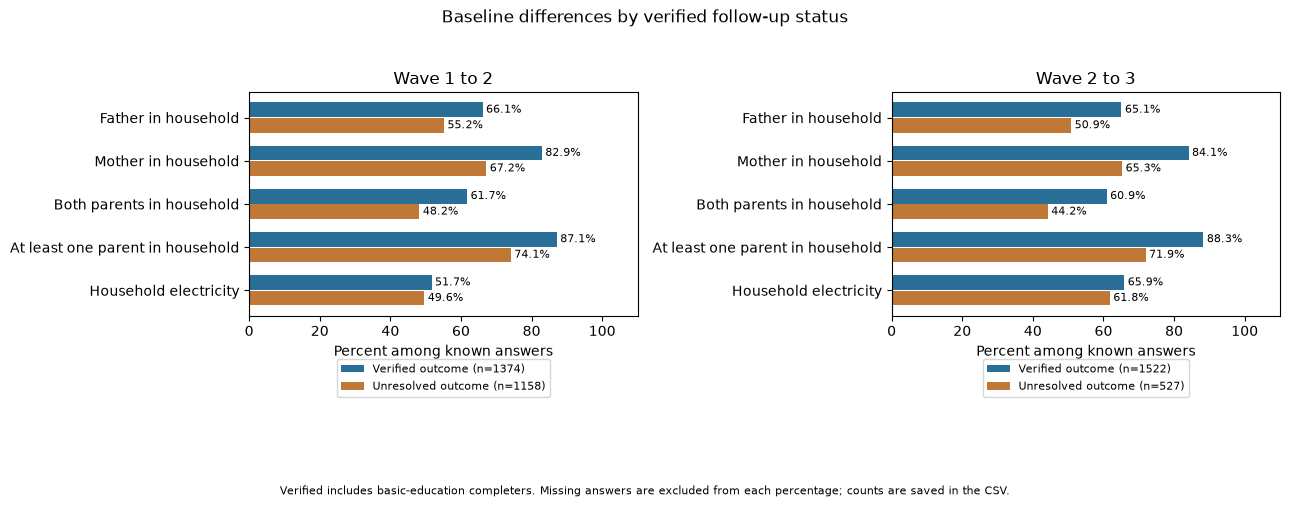

In [5]:
# Attrition audit: baseline features only; unknown outcomes remain unknown.
attrition_tables = []
attrition_frames = {}
numeric_fields = ["age", "hh_size", "asset_count", "rooms", "school_spend", "durables_value"]
categorical_fields = ["sex", "regioncode", "urbrur", "relationship_to_head",
                      "father_edu", "mother_edu", "father_in_hh", "mother_in_hh",
                      "electricity", "both_parents_in_hh", "either_parent_in_hh"]
predictor_fields = ["age", "sex", "regioncode", "urbrur", "father_in_hh",
                    "mother_in_hh", "father_edu", "mother_edu", "hh_size",
                    "asset_count", "electricity", "rooms"]

for wave, filename, labelled in [
    ("Wave 1 to 2", "w1_baseline_all_statuses.csv", train),
    ("Wave 2 to 3", "w2_baseline_all_statuses.csv", test_raw),
]:
    baseline = pd.read_csv(PROC / filename)
    assert not baseline.duplicated(["FPrimary", "hhmid"]).any()
    assert baseline.status.notna().all()
    allowed = {"enrolled", "dropout", "completed_basic", "status_unknown",
               "id_mismatch", "moved_out", "not_in_w2_roster",
               "not_in_w3_roster", "household_not_found"}
    assert set(baseline.status).issubset(allowed)
    included = baseline.status.isin(["enrolled", "dropout"])
    verified = baseline.status.isin(["enrolled", "dropout", "completed_basic"])
    assert set(zip(baseline.loc[included, "FPrimary"], baseline.loc[included, "hhmid"])) == set(zip(labelled.FPrimary, labelled.hhmid))
    assert baseline.loc[included, "status"].eq("dropout").sum() == labelled[TARGET].sum()
    # Three-valued logic: an unknown parent status is never silently treated as absence.
    father, mother = baseline.father_in_hh, baseline.mother_in_hh
    assert father.dropna().isin([0, 1]).all() and mother.dropna().isin([0, 1]).all()
    baseline["both_parents_in_hh"] = np.select(
        [father.eq(1) & mother.eq(1), father.eq(0) | mother.eq(0)], [1., 0.], default=np.nan)
    baseline["either_parent_in_hh"] = np.select(
        [father.eq(1) | mother.eq(1), father.eq(0) & mother.eq(0)], [1., 0.], default=np.nan)
    baseline["verified_followup"] = verified
    baseline["model_included"] = included
    attrition_frames[wave] = baseline
    print(f"\n{wave}: {len(baseline)} baseline children")
    for group, mask in [("Model included", included), ("Model excluded", ~included),
                        ("Verified outcome (including completers)", verified),
                        ("Unresolved follow-up/outcome", ~verified)]:
        print(f"  {group}: {mask.sum()} ({100 * mask.mean():.2f}%)")
        attrition_tables.append(dict(wave=wave, comparison="cohort_flow", group=group,
                                     feature="children", level="all", n_total=len(baseline),
                                     count=int(mask.sum()), percent=100 * mask.mean()))
    for status, count in baseline.status.value_counts().items():
        attrition_tables.append(dict(wave=wave, comparison="status_breakdown", group="All baseline",
                                     feature="status", level=status, n_total=len(baseline),
                                     count=int(count), percent=100 * count / len(baseline)))
    for comparison, mask, names in [
        ("followup", verified, ("Verified", "Unresolved")),
        ("model_selection", included, ("Included", "Excluded")),
    ]:
        for group, group_mask in zip(names, [mask, ~mask]):
            part = baseline.loc[group_mask]
            for feature in numeric_fields + categorical_fields:
                values = part[feature]
                common = dict(wave=wave, comparison=comparison, group=group, feature=feature,
                              n_total=len(part), n_observed=int(values.notna().sum()),
                              n_missing=int(values.isna().sum()), missing_percent=100 * values.isna().mean())
                if feature in numeric_fields:
                    attrition_tables.append(dict(**common, level="numeric", mean=values.mean(),
                                                 median=values.median(), q25=values.quantile(.25), q75=values.quantile(.75)))
                else:
                    # Include zero-count categories to allow direct group comparisons.
                    for level in sorted(baseline[feature].dropna().unique()):
                        count = int(values.eq(level).sum())
                        attrition_tables.append(dict(**common, level=str(level), count=count,
                                                     percent=100 * count / values.notna().sum() if values.notna().any() else np.nan))
        # Numeric standardized differences: verified/included minus unresolved/excluded.
        for feature in numeric_fields:
            a, b = baseline.loc[mask, feature].dropna(), baseline.loc[~mask, feature].dropna()
            pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
            attrition_tables.append(dict(wave=wave, comparison=comparison, group="First minus second",
                                         feature=feature, level="standardized_mean_difference",
                                         standardized_difference=(a.mean()-b.mean()) / pooled_sd if pooled_sd > 0 else np.nan))
    for feature in predictor_fields:
        attrition_tables.append(dict(wave=wave, comparison="weighting_feasibility", group="All baseline",
                                     feature=feature, level="availability", n_total=len(baseline),
                                     n_observed=int(baseline[feature].notna().sum()),
                                     n_missing=int(baseline[feature].isna().sum()),
                                     missing_percent=100 * baseline[feature].isna().mean(),
                                     distinct_observed=int(baseline[feature].nunique())))
    complete = baseline[predictor_fields].notna().all(axis=1)
    print(f"  Complete baseline predictor records: {complete.sum()}/{len(baseline)}")
    print("  Co-residence percentages among children with known answers:")
    for feature in ["father_in_hh", "mother_in_hh", "both_parents_in_hh", "either_parent_in_hh"]:
        print(f"    {feature}: verified {100*baseline.loc[verified,feature].mean():.2f}%, "
              f"unresolved {100*baseline.loc[~verified,feature].mean():.2f}%")

attrition_comparison = pd.DataFrame(attrition_tables)
attrition_comparison.to_csv(OUT / "attrition_comparison.csv", index=False)

# Unweighted baseline descriptive comparisons, not population estimates or causal effects.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = {"father_in_hh": "Father in household", "mother_in_hh": "Mother in household",
          "both_parents_in_hh": "Both parents in household", "either_parent_in_hh": "At least one parent in household",
          "electricity": "Household electricity"}
for ax, (wave, baseline) in zip(axes, attrition_frames.items()):
    y = np.arange(len(labels))
    for offset, verified_value, title, color in [(-.18, True, "Verified outcome", "#2a6f97"),
                                                 (.18, False, "Unresolved outcome", "#c07837")]:
        part = baseline.loc[baseline.verified_followup.eq(verified_value)]
        values = [100 * part[c].mean() for c in labels]
        ax.barh(y + offset, values, height=.34, color=color, label=f"{title} (n={len(part)})")
        for pos, value, column in zip(y + offset, values, labels):
            ax.text(value + 1, pos, f"{value:.1f}%", va="center", fontsize=8)
    ax.set_yticks(y, labels.values())
    ax.invert_yaxis()
    ax.set_xlim(0, 110)
    ax.set_xlabel("Percent among known answers")
    ax.set_title(wave)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.17), fontsize=8)
fig.suptitle("Baseline differences by verified follow-up status")
fig.text(.5, .01, "Verified includes basic-education completers. Missing answers are excluded from each percentage; counts are saved in the CSV.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .12, 1, .95])
fig.savefig(FIG / "attrition_comparison.png", dpi=300, bbox_inches="tight")
plt.show()



### Interpretation and follow-up weighting feasibility

In Wave 1, 1,225/2,532 children (48.38%) are excluded from modelling, but 67 completed basic education. The unresolved-outcome count is therefore 1,158 (45.73%). Wave 2 has 654/2,049 excluded (31.92%), including 127 completers; 527 (25.72%) have unresolved outcomes. The recorded statuses distinguish exclusion reasons but do not establish every underlying cause.

The feedback's approximate 52% versus 67% parent co-residence comparison is not reproduced by the explicit parent-presence definitions checked here. For Wave 1 verified versus unresolved outcomes, father presence is 66.10% versus 55.19%, mother presence 82.89% versus 67.16%, both parents 61.72% versus 48.21%, and at least one parent 87.12% versus 74.13%, among known answers. The CSV also reports included-versus-excluded comparisons and their missingness. Parent co-residence is consistently lower among unresolved children, supporting concern about selective observation; it does not identify the direction of bias in dropout predictions.

**Weighting is feasible to investigate, not yet validated.** Twelve baseline demographic/family/wealth predictors are available for the broader cohort; 2,220/2,532 Wave 1 and 1,872/2,049 Wave 2 records are complete on all twelve. A future follow-up model should use baseline predictors only, train-fold imputation and grouped out-of-fold propensity estimates. Before using inverse probabilities, examine calibration, overlap/positivity, extreme weights, truncation sensitivity and effective sample size. Weighting assumes observation is independent of the relevant outcome conditional on these predictors; unobserved drivers may violate this. Completers must remain separate: verified follow-up and inclusion in the current binary model are different events. Any weighting analysis must define its target population accordingly.

No weights or new dropout labels are created here. The model estimates risk among children with observable, task-eligible outcomes and may not generalise to those with unresolved follow-up. Subgroup predictive performance requires the later model-evaluation step.

## Shared model-evaluation metrics

All subsequent model comparisons will use `src/evaluation_metrics.py`. PR-AUC is defined as **average precision (AP)**, rather than trapezoidal PR-curve area. Brier score measures mean squared probability error (lower is better). Evaluation must use held-out predictions; this cell does not fit models or report model performance.

The operational policy selects the highest-risk **20%**, rounded down to avoid exceeding capacity. Exact probability ties are resolved using a deterministic hash of the unique household/person key, independent of outcomes and input order. This is a cohort-specific ranking rule, not a universal probability threshold. Report the actual selected count and fraction alongside precision, recall, lift over random targeting and the confusion matrix (rows: actual 0/1; columns: unselected/selected 0/1). With fewer than five observations the policy selects nobody, and precision is undefined. AP/recall are undefined when no dropouts occur; these are reported as NaN, not zero.

A random policy's expected precision equals cohort prevalence and expected recall equals the selected fraction. These are theoretical reference values, not simulated model results. For later subgroup reporting, evaluate the overall selection mask within each subgroup; independently selecting 20% in each subgroup represents a different allocation policy. Calibration curves and calibration-error estimates will be added in the calibration step.


In [6]:
from src.evaluation_metrics import evaluate_binary_risk, select_top_risk

INTERVENTION_CAPACITY = 0.20

def evaluation_row_ids(frame):
    """Stable compound identity keys for tie handling only; never predictors."""
    import json
    assert frame[["FPrimary", "hhmid"]].notna().all().all()
    assert not frame.duplicated(["FPrimary", "hhmid"]).any()
    return [json.dumps([str(household), str(person)], separators=(",", ":"))
            for household, person in zip(frame["FPrimary"], frame["hhmid"])]

# Future use with aligned out-of-sample predictions:
# metrics = evaluate_binary_risk(y_valid, predicted_probabilities,
#                               evaluation_row_ids(validation_frame),
#                               capacity=INTERVENTION_CAPACITY)
print("Shared metrics ready: average precision, Brier score and top-20% policy.")


Shared metrics ready: average precision, Brier score and top-20% policy.


## 3. Figures 1.1 and 1.2: missing answers and the outcome

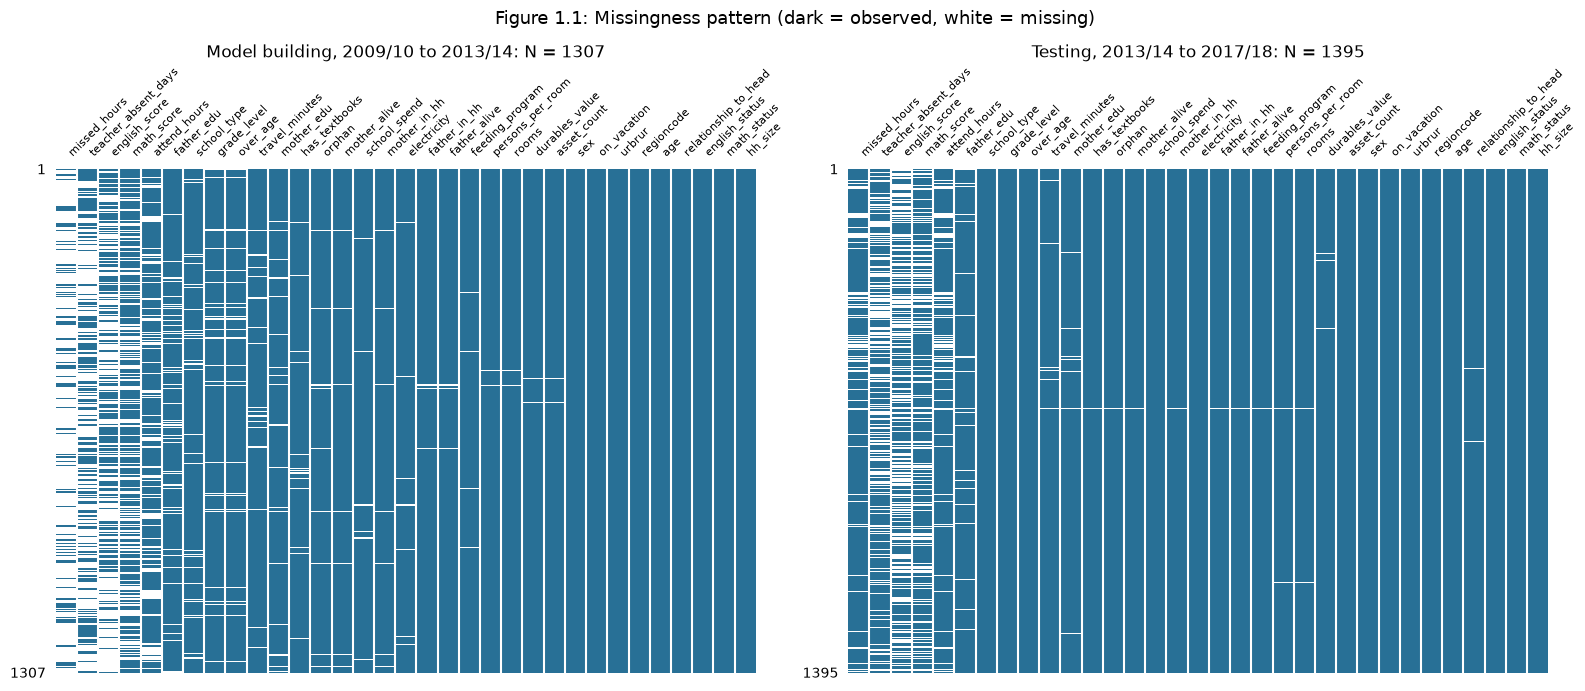

X_train: 3847 of 43131 answers missing (8.92%); complete rows 53 of 1307
X_test: 1827 of 46035 answers missing (3.97%); complete rows 467 of 1395


In [7]:
miss = X_train[FEATURES_33].isna().mean().sort_values(ascending=False)
order = miss.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, df) in zip(axes, [("Model building, 2009/10 to 2013/14", X_train), ("Testing, 2013/14 to 2017/18", X_test)]):
    msno.matrix(df[order], ax=ax, sparkline=False, fontsize=8, color=(0.16, 0.44, 0.59))
    ax.set_title(f"{name}: N = {len(df)}", fontsize=12)
plt.suptitle("Figure 1.1: Missingness pattern (dark = observed, white = missing)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig1_1_missingness_heatmap.png", bbox_inches="tight")
plt.show()

for name, df in [("X_train", X_train), ("X_test", X_test)]:
    m = df[FEATURES_33].isna()
    print(f"{name}: {m.values.sum()} of {m.size} answers missing ({m.values.mean():.2%}); "
          f"complete rows {(~m.any(axis=1)).sum()} of {len(df)}")

*How to read Figure 1.1:* each thin row is one child and each column one feature; white marks are missing answers. Columns are sorted from most to least missing in the model-building table.

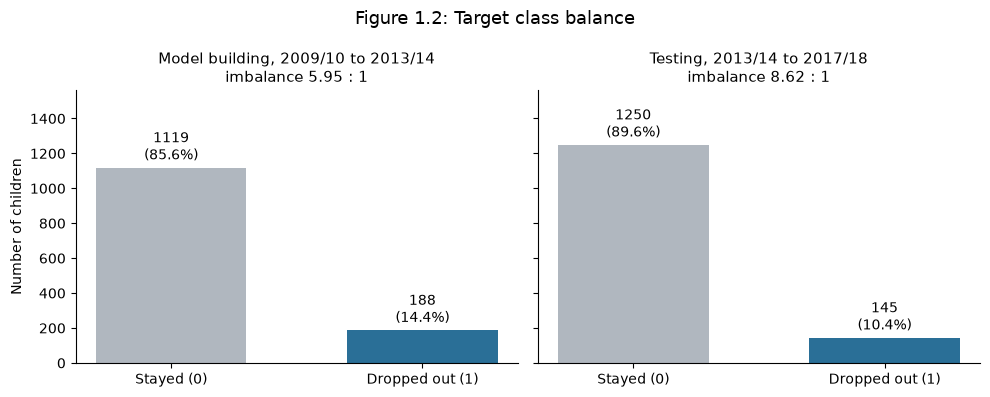

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, y) in zip(axes, [("Model building, 2009/10 to 2013/14", y_train), ("Testing, 2013/14 to 2017/18", y_test)]):
    counts = y.value_counts().reindex([0, 1])
    bars = ax.bar(["Stayed (0)", "Dropped out (1)"], counts.values, color=[GREY, BLUE], width=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom")
    ax.set_title(f"{name}\nimbalance {counts[0] / counts[1]:.2f} : 1", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of children")
axes[0].set_ylim(0, max(len(y_train), len(y_test)) * 1.12)
plt.suptitle("Figure 1.2: Target class balance", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig1_2_target_distribution.png", bbox_inches="tight")
plt.show()

## 4. Fit the pipeline on X_train only, then apply it to X_test

Two versions are built from the same steps (`src/pipeline_builder.py`):
* **XGBoost version**: no log transform and no scaling (trees only compare values).
* **Logistic regression / PCA version**: log on long tails, then `StandardScaler`, one option per label left out.

`fit` learns every setting (medians, modes, KNN neighbours, cap limits, money ranks, encoders, scaler) from **X_train only**; `transform` applies those settings to X_test unchanged.

In [9]:
pre_xgb = build_pipeline("xgb").fit(X_train)
pre_lr = build_pipeline("lr").fit(X_train)

def as_frame(pre, X):
    return pd.DataFrame(pre.transform(X), columns=pre.named_steps["prep"].get_feature_names_out(), index=X.index)

Xtr_xgb, Xte_xgb = as_frame(pre_xgb, X_train), as_frame(pre_xgb, X_test)
Xtr_lr, Xte_lr = as_frame(pre_lr, X_train), as_frame(pre_lr, X_test)

# leakage check: applying the pipeline to X_test must not change anything it learned
import pickle
state = pickle.dumps(pre_xgb); _ = pre_xgb.transform(X_test)
assert pickle.dumps(pre_xgb) == state
print("Leakage check passed: transforming X_test does not change the fitted settings.")
print(pre_xgb)

Leakage check passed: transforming X_test does not change the fitted settings.
Pipeline(steps=[('missed_hours_rule', MissedHoursRule()),
                ('missing_flags', MissingFlagger()),
                ('grade_knn', GradeKNNImputer()),
                ('drop_repeating', ColumnDropper()),
                ('recode', CategoryRecoder()),
                ('prep',
                 ColumnTransformer(transformers=[('mean',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   'passthrough')]),
                                                  ['english_score',
                                                   'math_score']),
                                                 ('median',
                                                  Pipeli...
 

## 5. Pipeline output verification

In [10]:
checks = {
    "Raw features": len(FEATURES_33),
    "Features after removing 3 repeating ones": len(FEATURES_30),
    "Columns, XGBoost version": Xtr_xgb.shape[1],
    "Columns, logistic regression version": Xtr_lr.shape[1],
    "Rows X_train / X_test": f"{len(Xtr_xgb)} / {len(Xte_xgb)}",
    "Missing values left (train, test)": f"{int(Xtr_xgb.isna().sum().sum())}, {int(Xte_xgb.isna().sum().sum())}",
}
assert len(FEATURES_30) == 30 and Xtr_xgb.shape[1] == 53 and Xtr_lr.shape[1] == 48
assert Xtr_xgb.isna().sum().sum() == 0 and Xte_xgb.isna().sum().sum() == 0
for k, v in checks.items():
    print(f"{k:45s} {v}")

groups = {"numbers or ordered numbers": 16, "yes/no items": 9, "one-hot label columns": 24, "'was missing' flags": 4}
print("\n53 columns =", " + ".join(f"{v} {k}" for k, v in groups.items()))

Raw features                                  33
Features after removing 3 repeating ones      30
Columns, XGBoost version                      53
Columns, logistic regression version          48
Rows X_train / X_test                         1307 / 1395
Missing values left (train, test)             0, 0

53 columns = 16 numbers or ordered numbers + 9 yes/no items + 24 one-hot label columns + 4 'was missing' flags


**Structural feature removal is checked separately from later transformations.** Before subsequent imputation, capping and ranking, each removed feature can be rebuilt exactly from retained source fields, including matching missing values. This does not claim that the full preprocessing pipeline is invertible. The check below rebuilds them and counts any child where the rebuilt value differs.

In [11]:
d = train
reconstructed = {
    "school_grade": d.age - d.over_age - 5,
    "lost_a_parent (orphan)": pd.Series(np.select(
        [d.father_alive.eq(0) | d.mother_alive.eq(0), d.father_alive.eq(1) & d.mother_alive.eq(1)],
        [1., 0.], default=np.nan), index=d.index),
    "people_per_room": d.hh_size / d.rooms,
}
originals = {"school_grade": "grade_level", "lost_a_parent (orphan)": "orphan", "people_per_room": "persons_per_room"}
descriptions = {"school_grade": "age - over_age - 5",
                "lost_a_parent (orphan)": "Three-valued parent-alive logic; unknown stays unknown",
                "people_per_room": "household size / rooms"}
rebuild = pd.DataFrame([{"removed feature": name, "rebuilt from kept features": descriptions[name],
    "children checked": len(d), "children that differ": int((~np.isclose(values, d[originals[name]], equal_nan=True)).sum())}
    for name, values in reconstructed.items()])
print(rebuild.to_string(index=False))
assert rebuild["children that differ"].sum() == 0
rebuild.to_csv(OUT / "feature_reconstruction.csv", index=False)
print("This checks the structural feature removal only; capping/ranking intentionally change values.")


       removed feature                             rebuilt from kept features  children checked  children that differ
          school_grade                                     age - over_age - 5              1307                     0
lost_a_parent (orphan) Three-valued parent-alive logic; unknown stays unknown              1307                     0
       people_per_room                                 household size / rooms              1307                     0
This checks the structural feature removal only; capping/ranking intentionally change values.


## 6. Figure 2.1: extreme values before and after capping

The cap limits are the ones the pipeline learned from X_train (IQR fence on the log scale). Money is no longer capped: it is ranked (Phase 1, C1), so only the three capped features are shown.

                upper limit  capped (train)  capped (test)
travel_minutes        294.0               2              0
hh_size                15.2               6              4
rooms                  18.8               5              1
Total capped: 13 (train), 5 (test). No child deleted.


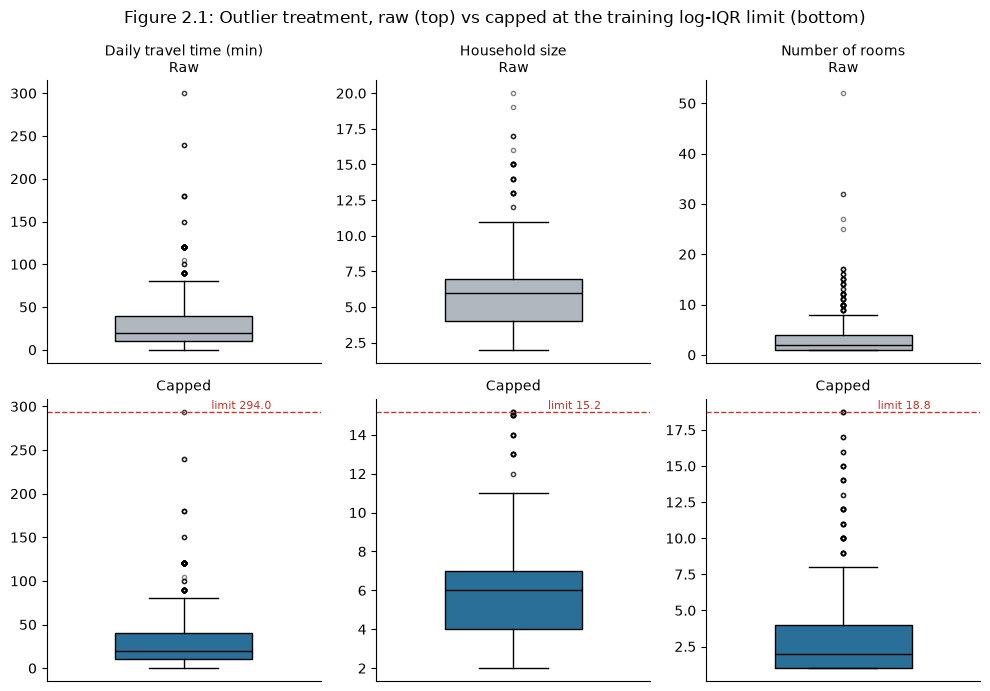

In [12]:
capper = pre_xgb.named_steps["prep"].named_transformers_["cap"].named_steps["cap"]
CAP = ["travel_minutes", "hh_size", "rooms"]
LABEL = {"travel_minutes": "Daily travel time (min)", "hh_size": "Household size", "rooms": "Number of rooms"}
limits = dict(zip(CAP, capper.upper_))
capped_train = {c: int((X_train[c] > limits[c]).sum()) for c in CAP}
capped_test = {c: int((X_test[c] > limits[c]).sum()) for c in CAP}
print(pd.DataFrame({"upper limit": pd.Series(limits).round(1), "capped (train)": capped_train,
                    "capped (test)": capped_test}).to_string())
print("Total capped:", sum(capped_train.values()), "(train),", sum(capped_test.values()), "(test). No child deleted.")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for j, c in enumerate(CAP):
    raw = X_train[c].dropna()
    for i, (data, lab) in enumerate([(raw, "Raw"), (raw.clip(upper=limits[c]), "Capped")]):
        ax = axes[i, j]
        ax.boxplot(data, widths=0.5, patch_artist=True, boxprops=dict(facecolor=GREY if i == 0 else BLUE),
                   medianprops=dict(color="black"), flierprops=dict(marker="o", markersize=3, alpha=0.5))
        ax.set_xticks([])
        ax.set_title(f"{LABEL[c]}\n{lab}" if i == 0 else lab, fontsize=10)
        if i == 1:
            ax.axhline(limits[c], color=RED, ls="--", lw=1)
            ax.text(1.32, limits[c], f"limit {limits[c]:.1f}", color=RED, fontsize=8, va="bottom", ha="right")
        ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 2.1: Outlier treatment, raw (top) vs capped at the training log-IQR limit (bottom)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig2_1_outlier_boxplots.png", bbox_inches="tight")
plt.show()

## 7. Figures 3.1 and 3.2: features that repeat each other

The brief asks for pairs with |r| ≥ 0.85. The correlation is measured with **Spearman ρ** to describe monotone relationships and reduce sensitivity to extreme values, as planned in Phase 1; non-normality does not prohibit computing Pearson r. The cell also shows Pearson r for the flagged pairs, to make the difference visible.

father_alive vs orphan: Spearman rho = -0.850, Pearson r = -0.850
rooms vs persons_per_room: Spearman rho = -0.855, Pearson r = -0.563


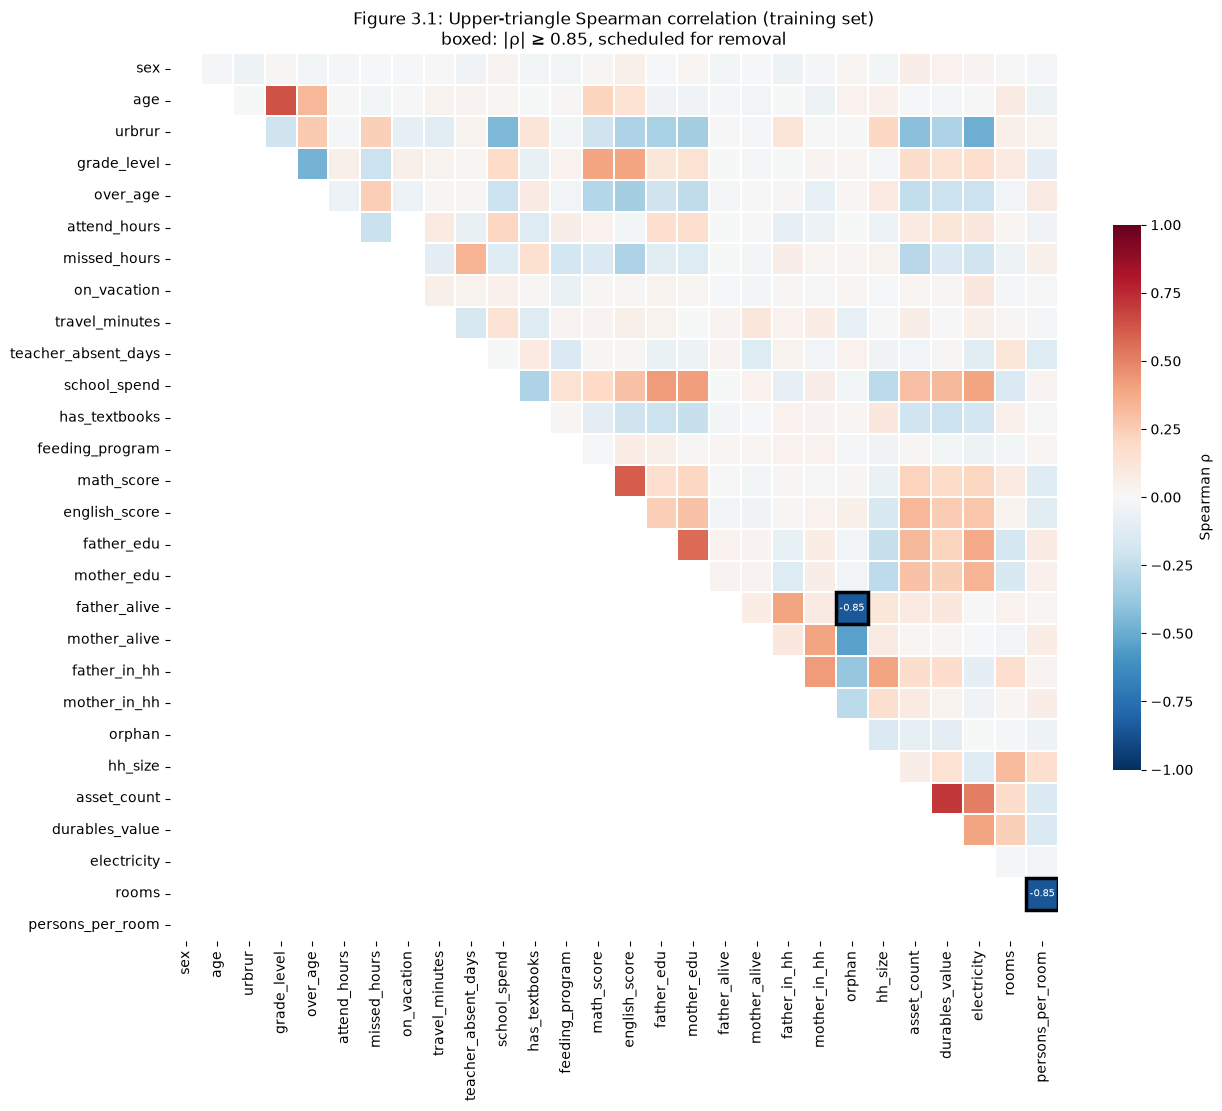

In [13]:
TYPES = {"Nominal": ["regioncode", "school_type", "relationship_to_head", "math_status", "english_status"]}
CORR_FEATS = [c for c in FEATURES_33 if c not in TYPES["Nominal"]]
rho = X_train[CORR_FEATS].corr(method="spearman")
pear = X_train[CORR_FEATS].corr(method="pearson")
pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(CORR_FEATS) for b in CORR_FEATS[i + 1:] if abs(rho.loc[a, b]) >= 0.85]
for a, b, r in pairs:
    print(f"{a} vs {b}: Spearman rho = {r:+.3f}, Pearson r = {pear.loc[a, b]:+.3f}")

mask = np.tril(np.ones_like(rho, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(rho, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.6, "label": "Spearman ρ"}, ax=ax)
for a, b, r in pairs:
    i, j = CORR_FEATS.index(a), CORR_FEATS.index(b)
    ax.add_patch(plt.Rectangle((max(i, j), min(i, j)), 1, 1, fill=False, edgecolor="black", lw=2.5))
    ax.text(max(i, j) + 0.5, min(i, j) + 0.5, f"{r:.2f}", ha="center", va="center", fontsize=7, color="white")
ax.set_title("Figure 3.1: Upper-triangle Spearman correlation (training set)\nboxed: |ρ| ≥ 0.85, scheduled for removal", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig3_1_correlation_matrix.png", bbox_inches="tight")
plt.show()

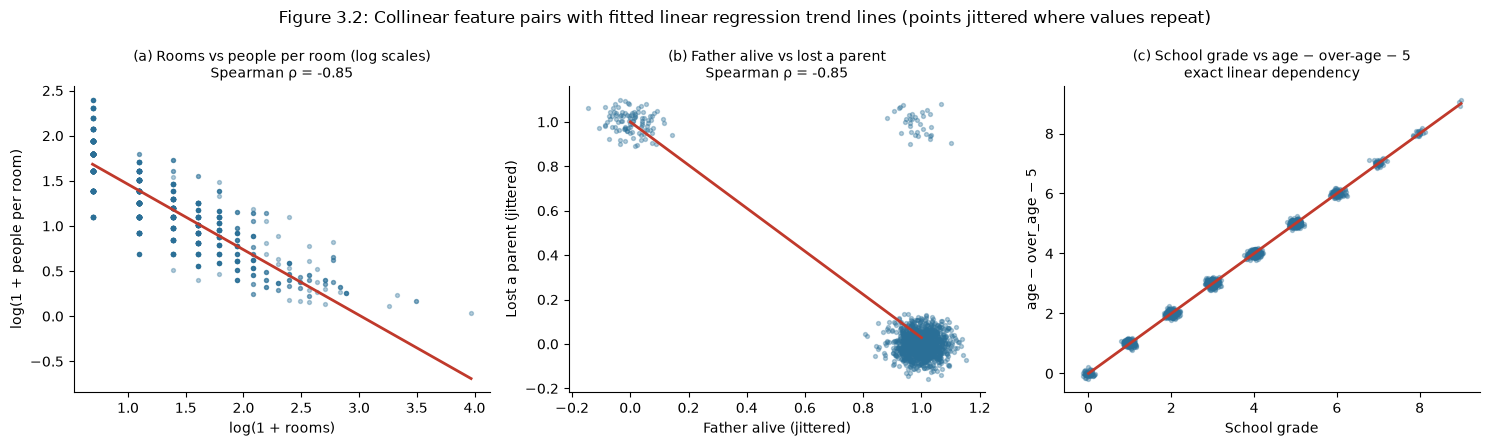

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
rng = np.random.default_rng(0)

d = X_train[["rooms", "persons_per_room"]].dropna()
lx, ly = np.log1p(d["rooms"]), np.log1p(d["persons_per_room"])
axes[0].scatter(lx, ly, s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(lx, ly, 1); xs = np.linspace(lx.min(), lx.max(), 50)
axes[0].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[0].set_xlabel("log(1 + rooms)"); axes[0].set_ylabel("log(1 + people per room)")
axes[0].set_title(f"(a) Rooms vs people per room (log scales)\nSpearman ρ = {d['rooms'].corr(d['persons_per_room'], method='spearman'):+.2f}", fontsize=10)

d = X_train[["father_alive", "orphan"]].dropna()
axes[1].scatter(d["father_alive"] + rng.normal(0, 0.05, len(d)), d["orphan"] + rng.normal(0, 0.05, len(d)), s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(d["father_alive"], d["orphan"], 1); xs = np.linspace(0, 1, 50)
axes[1].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[1].set_xlabel("Father alive (jittered)"); axes[1].set_ylabel("Lost a parent (jittered)")
axes[1].set_title(f"(b) Father alive vs lost a parent\nSpearman ρ = {d['father_alive'].corr(d['orphan'], method='spearman'):+.2f}", fontsize=10)

d = X_train[["grade_level", "age", "over_age"]].dropna()
implied = d["age"] - d["over_age"] - 5
axes[2].scatter(d["grade_level"] + rng.normal(0, 0.08, len(d)), implied + rng.normal(0, 0.08, len(d)), s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(d["grade_level"], implied, 1); xs = np.linspace(0, 9, 50)
axes[2].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[2].set_xlabel("School grade"); axes[2].set_ylabel("age − over_age − 5")
axes[2].set_title("(c) School grade vs age − over-age − 5\nexact linear dependency", fontsize=10)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 3.2: Collinear feature pairs with fitted linear regression trend lines (points jittered where values repeat)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig3_2_collinear_scatterplots.png", bbox_inches="tight")
plt.show()

**Check promised in Phase 1 (B4b):** the choice of which feature to drop is re-checked inside each of the 5 folds, using only the building part of the fold. The removal list is fixed from structural identities and domain meaning, independent of dropout. The MI-only diagnostic below may select different features; it does not change the pipeline.

In [15]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def mi_one(x, y, discrete):
    ok = x.notna()
    return mutual_info_classif(x[ok].to_numpy().reshape(-1, 1), y[ok], discrete_features=[discrete], random_state=42)[0]

rows = []
for k, (a, _) in enumerate(cv.split(X_train, y_train, groups=X_train["district_id"]), start=1):
    Xa, ya = X_train.iloc[a], y_train.iloc[a]
    r = Xa[CORR_FEATS].corr(method="spearman")
    flagged = sorted({tuple(sorted((p, q))) for p in CORR_FEATS for q in CORR_FEATS if p < q and abs(r.loc[p, q]) >= 0.85})
    # within each flagged pair, drop the feature with less information about dropout
    mi = {c: mi_one(Xa[c], ya, c not in ("persons_per_room", "rooms")) for c in ["persons_per_room", "rooms", "orphan", "father_alive", "grade_level", "age", "over_age"]}
    drop1 = "persons_per_room" if mi["persons_per_room"] < mi["rooms"] else "rooms"
    drop2 = "orphan" if mi["orphan"] < mi["father_alive"] else "father_alive"
    drop3 = min(["grade_level", "age", "over_age"], key=lambda c: mi[c])
    rows.append({"fold": k, "pairs |rho|>=0.85": len(flagged), "drop 1": drop1, "drop 2": drop2, "drop 3": drop3})
fold_drops = pd.DataFrame(rows)
print(fold_drops.to_string(index=False))

 fold  pairs |rho|>=0.85           drop 1       drop 2      drop 3
    1                  1 persons_per_room       orphan grade_level
    2                  1            rooms       orphan grade_level
    3                  2            rooms       orphan grade_level
    4                  2 persons_per_room father_alive         age
    5                  1            rooms       orphan         age


*What this shows:* MI-only choices agree with the fixed structural list in only 1 of 5 folds. The diagnostic is descriptive, not the selection rule. The pipeline always removes people per room, orphan status and grade because their source fields are retained; the structural identities are checked separately. This does not establish that all later imputation, capping or ranking preserves information.

## 8. Figure 3.3: which features tell us most about dropout

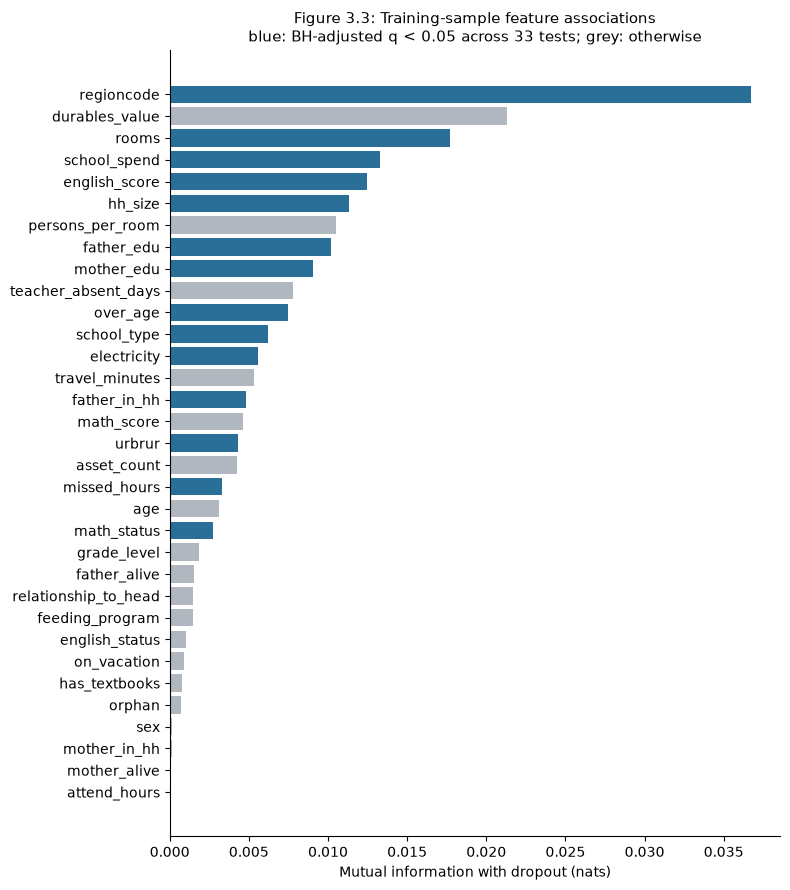

         feature       type               test            p    effect  Pearson chi2  df  minimum expected  cells expected <5  observed n  MC standard error     effect type              effect size  |effect|       MI            q  q-value (BY sensitivity) BH q<0.05
      regioncode    Nominal Pearson chi-square 2.608755e-20  0.294926    113.684905 9.0         10.356542                  0        1307                NaN      Cramer's V      Cramer's V = +0.295  0.294926 0.036719 8.608891e-19              3.520002e-18       yes
  durables_value Continuous     Mann-Whitney U 1.493183e-01  0.065816           NaN NaN               NaN                  0        1302                NaN rank-biserial r rank-biserial r = +0.066  0.065816 0.021320 2.463752e-01              1.000000e+00        no
           rooms   Discrete     Mann-Whitney U 2.003811e-04  0.165490           NaN NaN               NaN                  0        1302                NaN rank-biserial r rank-biserial r = +0.165  0.16549

In [16]:
# Reuse the exact Phase 1 sparse-aware, multiplicity-adjusted association audit.
imp = pd.read_csv(ROOT / "phase1_strategy/B4a_feature_target_tests.csv").rename(
    columns={"mutual information": "MI", "p-value": "p", "q-value (BH)": "q"}).sort_values("MI")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(imp.feature, imp.MI, color=np.where(imp.q < .05, BLUE, GREY))
ax.set_xlabel("Mutual information with dropout (nats)")
ax.set_title("Figure 3.3: Training-sample feature associations\nblue: BH-adjusted q < 0.05 across 33 tests; grey: otherwise", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "fig3_3_target_importance.png", bbox_inches="tight")
plt.show()
print(imp.sort_values("MI", ascending=False).head(8).to_string(index=False))


## 9. Figure 4.1: what the transformation stages do to one feature (daily travel time)

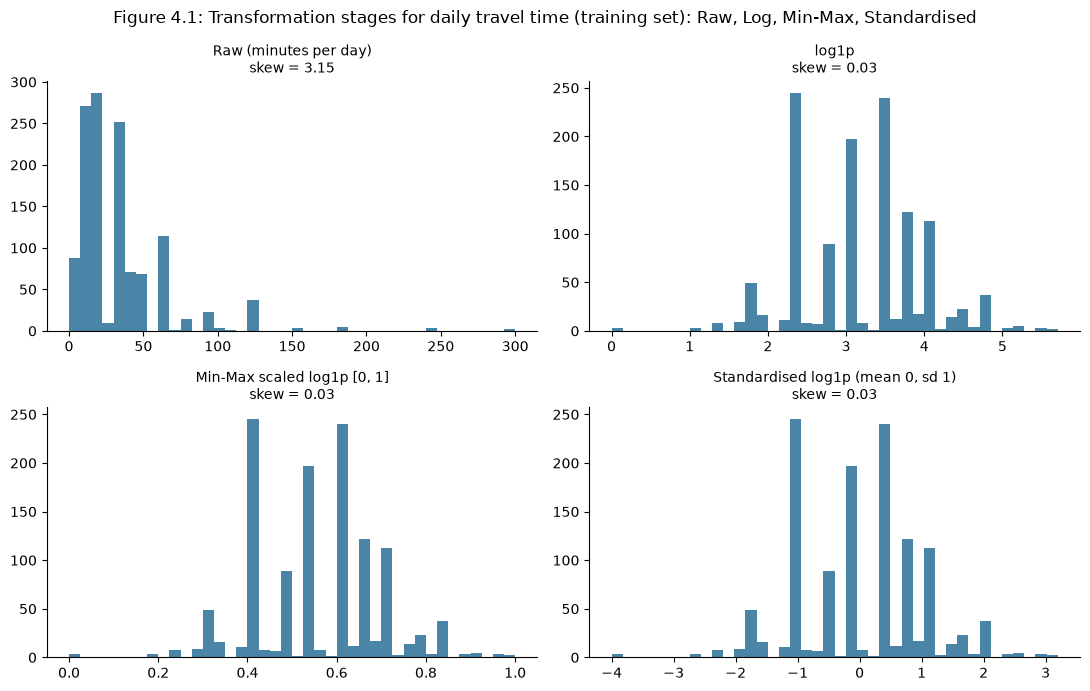

In [17]:
x = X_train["travel_minutes"].dropna().to_numpy().reshape(-1, 1)
lx = np.log1p(x)
stages = [("Raw (minutes per day)", x), ("log1p", lx),
          ("Min-Max scaled log1p [0, 1]", MinMaxScaler().fit_transform(lx)),
          ("Standardised log1p (mean 0, sd 1)", StandardScaler().fit_transform(lx))]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (title, v) in zip(axes.ravel(), stages):
    v = v.ravel()
    ax.hist(v, bins=40, color=BLUE, alpha=0.85)
    ax.set_title(f"{title}\nskew = {pd.Series(v).skew():.2f}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 4.1: Transformation stages for daily travel time (training set): Raw, Log, Min-Max, Standardised", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig4_1_transformation_grid.png", bbox_inches="tight")
plt.show()

## 10. Figure 5.1: PCA scree and cumulative variance

PCA is fitted on the 48 preprocessed logistic-regression columns of X_train: 16 numeric/ordinal columns are standardised; 32 binary, one-hot and missingness indicators remain on their 0/1 scale. PCA centres these inputs but does not additionally scale them. Its variance percentages therefore describe this deliberately mixed-scaled representation, not 48 unit-variance columns. The diagnostic is not used as model input.

Components needed: 21 of 48 for 90% of the variance, 28 for 95%


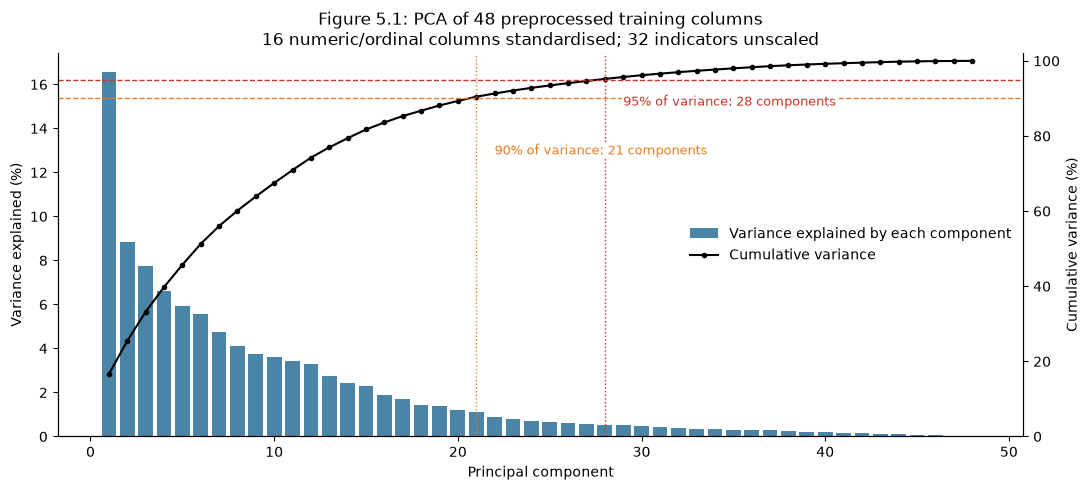

In [18]:
pca = PCA().fit(Xtr_lr)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
k90, k95 = int(np.argmax(cum >= 0.90) + 1), int(np.argmax(cum >= 0.95) + 1)
print(f"Components needed: {k90} of {len(ratio)} for 90% of the variance, {k95} for 95%")

fig, ax = plt.subplots(figsize=(11, 5))
idx = np.arange(1, len(ratio) + 1)
ax.bar(idx, ratio * 100, color=BLUE, alpha=0.85, label="Variance explained by each component")
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained (%)")
ax2 = ax.twinx()
ax2.plot(idx, cum * 100, color="black", marker="o", markersize=3, lw=1.5, label="Cumulative variance")
for level, k, col in [(90, k90, "#e67e22"), (95, k95, RED)]:
    ax2.axhline(level, color=col, ls="--", lw=1)
    ax2.axvline(k, color=col, ls=":", lw=1)
    ax2.text(k + 1, level - 12 if level == 90 else level - 4, f"{level}% of variance: {k} components", color=col, fontsize=9,
             va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax2.set_ylabel("Cumulative variance (%)"); ax2.set_ylim(0, 102)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", frameon=False)
ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
plt.title("Figure 5.1: PCA of 48 preprocessed training columns\n16 numeric/ordinal columns standardised; 32 indicators unscaled", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig5_1_pca_scree_plot.png", bbox_inches="tight")
plt.show()
pd.DataFrame({"component": idx, "variance ratio": ratio, "cumulative variance": cum}).to_csv(
    OUT / "pca_variance.csv", index=False)


## 11. Other checks promised in Phase 1

* **Hours missed:** the rule "blank = 0 when attendance was recorded" is compared with simply filling the median.
* **Money after inflation adjustment:** where the testing children sit within the 2009/10 money ranks.
* **'Was missing' flags:** how often each flag is switched on in each period (no outcomes used).

In [19]:
r = MissedHoursRule().transform(X_train)
print(f"Hours missed: {int(X_train['missed_hours'].isna().sum() - r['missed_hours'].isna().sum())} blanks set to 0 by the rule; "
      f"{int(r['missed_hours'].isna().sum())} remain (holiday/unknown attendance) and are filled with the median")
print(f"Share reporting some hours missed when attendance was recorded: "
      f"2009/10 {((X_train['missed_hours'] > 0) & X_train['attend_hours'].notna()).sum() / X_train['attend_hours'].notna().sum():.1%}, "
      f"2013/14 {((X_test['missed_hours'] > 0) & X_test['attend_hours'].notna()).sum() / X_test['attend_hours'].notna().sum():.1%}")

for c in ["durables_value", "school_spend"]:
    print(f"{c}: typical rank of testing children against 2009/10 values = {Xte_xgb[c].median():.2f} "
          f"(0.50 would mean no real change)")

flags = [c for c in Xtr_xgb if c.endswith("_missing") and c != "school_type_missing"]
print(pd.DataFrame({"2009/10 (%)": (Xtr_xgb[flags].mean() * 100).round(1),
                    "2013/14 (%)": (Xte_xgb[flags].mean() * 100).round(1)}).to_string())

Hours missed: 756 blanks set to 0 by the rule; 261 remain (holiday/unknown attendance) and are filled with the median
Share reporting some hours missed when attendance was recorded: 2009/10 15.7%, 2013/14 14.4%
durables_value: typical rank of testing children against 2009/10 values = 0.63 (0.50 would mean no real change)
school_spend: typical rank of testing children against 2009/10 values = 0.39 (0.50 would mean no real change)
                             2009/10 (%)  2013/14 (%)
teacher_absent_days_missing         56.8         31.8
attend_hours_missing                21.8         11.7
father_edu_missing                   7.7          5.4
mother_edu_missing                   3.8          1.9


## 12. Quick end-to-end check with 5 district-grouped folds

This only checks that the full pipeline (preparation + model) runs fold by fold with fold-fitted preprocessing: every preparation step is re-fitted on the building part of each fold, and each dropout gets extra weight recalculated inside the fold. Model tuning, calibration and frozen primary/secondary retrospective temporal evaluation belong to the modelling phase, so **X_test outcomes are not used here**.

In [20]:
def cv_check(model, pipeline_fn=build_pipeline):
    pr, roc = [], []
    for a, b in cv.split(X_train, y_train, groups=X_train["district_id"]):
        ya = y_train.iloc[a]
        spw = (ya == 0).sum() / (ya == 1).sum()
        p = pipeline_fn(model, default_estimator(model, spw)).fit(X_train.iloc[a], ya)
        s = p.predict_proba(X_train.iloc[b])[:, 1]
        pr.append(average_precision_score(y_train.iloc[b], s)); roc.append(roc_auc_score(y_train.iloc[b], s))
    return np.mean(pr), np.std(pr), np.mean(roc)

def without_missed_rule(model, estimator):
    p = build_pipeline(model, estimator)
    p.steps[0] = ("missed_hours_rule", "passthrough")      # hours missed filled with the median instead
    return p

results = []
for m in ["lr", "xgb"]:
    for label, fn in [("Phase 1 plan", build_pipeline), ("hours missed: median instead of rule", without_missed_rule)]:
        mean_pr, sd_pr, mean_roc = cv_check(m, fn)
        results.append({"model": m, "variant": label, "PR-AUC (mean)": round(mean_pr, 3), "PR-AUC (sd)": round(sd_pr, 3), "ROC-AUC": round(mean_roc, 3)})
cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))
print(f"\nReference: a model with no skill has PR-AUC equal to the dropout rate, {y_train.mean():.3f}")
cv_results.to_csv(OUT / "cv_results.csv", index=False)


model                              variant  PR-AUC (mean)  PR-AUC (sd)  ROC-AUC
   lr                         Phase 1 plan          0.266        0.072    0.627
   lr hours missed: median instead of rule          0.275        0.076    0.635
  xgb                         Phase 1 plan          0.252        0.089    0.602
  xgb hours missed: median instead of rule          0.257        0.091    0.610

Reference: a model with no skill has PR-AUC equal to the dropout rate, 0.144


## Baseline model comparison using shared metrics

Evaluate the existing balanced logistic regression and XGBoost settings on the exact five verified `cv_splits`. Each model fits a fresh preprocessing pipeline within each training fold, including inner grouped grade-KNN selection. Class weighting uses only that fold's training labels. Globally transformed matrices are not used here.

These are **untuned, uncalibrated benchmarks**. The logistic model is the existing regularised baseline; explicit L1/ElasticNet tuning and additional model families remain later work. No temporal records participate. `baseline_metrics.csv` contains each fold's AP, Brier score, capacity-policy precision/recall/lift and confusion counts. `baseline_oof_predictions.csv` retains one held-out prediction per training child per model, with a pseudonymous identity key and within-fold selection flag.

Means and sample standard deviations below describe variation across five folds; they are not confidence intervals. Top-20% selection is applied separately within each validation fold. These probabilities can support diagnostics, but calibration must not be fitted and evaluated on the same OOF records: unbiased calibrated performance requires an additional inner calibration split within each outer training fold.


In [21]:
from src.model_evaluation import evaluate_baselines

baseline_metrics, baseline_oof = evaluate_baselines(
    train, cv_splits, capacity=INTERVENTION_CAPACITY
)
baseline_metrics.to_csv(OUT / "baseline_metrics.csv", index=False)
baseline_oof.to_csv(OUT / "baseline_oof_predictions.csv", index=False)
summary_columns = ["average_precision", "brier_score", "recall_at_capacity",
                   "precision_at_capacity", "lift_at_capacity"]
print(baseline_metrics.groupby("model")[summary_columns].agg(["mean", "std"]).round(4).to_string())
print("Uncalibrated training-only baselines; temporal cohorts have not been scored.")


lr fold 1/5: AP=0.3811, recall@capacity=0.5000


lr fold 2/5: AP=0.2509, recall@capacity=0.2941


lr fold 3/5: AP=0.3012, recall@capacity=0.4419


lr fold 4/5: AP=0.1671, recall@capacity=0.2941


lr fold 5/5: AP=0.2281, recall@capacity=0.3333


...

xgb fold 2/5: AP=0.2185, recall@capacity=0.3824


xgb fold 3/5: AP=0.2716, recall@capacity=0.3953


xgb fold 4/5: AP=0.1505, recall@capacity=0.2353


xgb fold 5/5: AP=0.2073, recall@capacity=0.2564


      average_precision         brier_score         recall_at_capacity         precision_at_capacity         lift_at_capacity        
                   mean     std        mean     std               mean     std                  mean     std             mean     std
model                                                                                                                                
lr               0.2657  0.0805      0.2284  0.0427             0.3727  0.0934                0.2713  0.0795           1.8719  0.4601
xgb              0.2519  0.0991      0.1706  0.0271             0.3539  0.1089                0.2565  0.0835           1.7773  0.5398
Uncalibrated training-only baselines; temporal cohorts have not been scored.


## Six-family model comparison (fixed, untuned settings)

Compare XGBoost, LightGBM, CatBoost, Random Forest, Extra Trees and logistic regression using the same verified five folds. Logistic regression includes both the previous L2 reference and an explicit ElasticNet configuration (`saga`, `l1_ratio=0.5`, `C=1`), yielding seven configurations. Every fit uses training-only preprocessing and training-fold class weights. All tree models receive the same imputed, one-hot representation; this experiment does not evaluate CatBoost's native categorical handling.

Settings are fixed before scoring: 300 boosting iterations at learning rate 0.05 with depth 3; LightGBM uses 7 leaves. Forests use 300 trees, square-root feature sampling and a minimum of five observations per leaf to limit overly specific splits. These are transparent starting choices, not tuned optima or equal-compute claims. Full estimator settings are saved in the metrics CSV. The ElasticNet baseline uses the existing LR scaling; its penalty and strength will be assessed through later inner-fold tuning. No outer-validation early stopping or temporal tuning is performed.

Results are exploratory and uncalibrated. Report fold variation, not just the largest mean, and do not claim that selecting the highest-scoring configuration yields an unbiased final performance estimate. Model selection, sensitivity tests and calibration still require training-only nested validation. The temporal cohorts remain unscored.

Implementation references: [scikit-learn logistic regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [CatBoost parameters](https://catboost.ai/docs/en/references/training-parameters/common), and [LightGBM parameters](https://lightgbm.readthedocs.io/en/latest/Parameters.html).


In [22]:
from src.model_evaluation import MODEL_NAMES
from sklearn.exceptions import ConvergenceWarning

with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    model_comparison_metrics, model_comparison_oof = evaluate_baselines(
        train, cv_splits, capacity=INTERVENTION_CAPACITY, models=MODEL_NAMES
    )
model_comparison_metrics.to_csv(OUT / "model_comparison_metrics.csv", index=False)
model_comparison_oof.to_csv(OUT / "model_comparison_oof_predictions.csv", index=False)
print(model_comparison_metrics.groupby("model")[summary_columns].agg(["mean", "std"]).round(4).to_string())
print("Seven fixed configurations across six families; no tuning, calibration or temporal scoring yet.")


lr fold 1/5: AP=0.3811, recall@capacity=0.5000


lr fold 2/5: AP=0.2509, recall@capacity=0.2941


lr fold 3/5: AP=0.3012, recall@capacity=0.4419


lr fold 4/5: AP=0.1671, recall@capacity=0.2941


lr fold 5/5: AP=0.2281, recall@capacity=0.3333


...

extra_trees fold 3/5: AP=0.3233, recall@capacity=0.4884


extra_trees fold 4/5: AP=0.1801, recall@capacity=0.2647


extra_trees fold 5/5: AP=0.3564, recall@capacity=0.3590


              average_precision         brier_score         recall_at_capacity         precision_at_capacity         lift_at_capacity        
                           mean     std        mean     std               mean     std                  mean     std             mean     std
model                                                                                                                                        
catboost                 0.2533  0.0895      0.1761  0.0258             0.3606  0.1322                0.2633  0.1060           1.8104  0.6551
elasticnet               0.2684  0.0828      0.2286  0.0426             0.3826  0.1067                0.2788  0.0894           1.9215  0.5265
extra_trees              0.2856  0.0780      0.1611  0.0190             0.4054  0.0932                0.2948  0.0799           2.0367  0.4615
lightgbm                 0.2334  0.0867      0.1781  0.0331             0.3337  0.1034                0.2412  0.0783           1.6758  0.5121
lr    


Seven fixed configurations across six families; no tuning, calibration or temporal scoring yet.


### Interpretation of the fixed-setting comparison

Random Forest has the highest mean AP (0.2869), closely followed by Extra Trees (0.2856), versus 0.2657 for the original logistic model. Extra Trees has mean recall of 40.54% at 20% capacity and precision of 29.48%; Random Forest has recall of 39.40%. These are exploratory gains on the same training validation folds, not established improvements on future children. Extra Trees also has the lowest mean Brier score (0.1611) among these configurations, but this alone does not establish adequate calibration. Fold variability is substantial and the settings remain untuned. All seven configurations and all fold results are retained, including weaker results for LightGBM; the temporal cohort has not been used to choose a winner.


## Missingness-indicator and geography sensitivity

Four prespecified configurations are evaluated using all seven fixed model configurations and the same five training folds: **full**, **no_missing_flags**, **no_geography**, and **neither**. This is 140 model/fold fits. Every pipeline is freshly fitted inside its training fold, including grouped grade-KNN selection. The default pipeline remains unchanged.

**Missingness scope:** remove only `teacher_absent_days_missing`, `attend_hours_missing`, `father_edu_missing` and `mother_edu_missing`. Keep the underlying features, imputation rules, assessment-status categories and the school-type missing category. This tests the incremental effect of the four explicit indicators; it does not eliminate every way missingness can influence predictions.

**Geography scope:** remove both region and urban/rural from final predictors **and** grade-KNN matching. District identifiers remain exclusively as validation-group metadata, never as predictors or distance components. Thus this is a broader geography ablation, not a pure region-fixed-effect test. Other socioeconomic variables may still proxy location. No new model settings are chosen from these results.

Compare AP, recall/precision/lift at 20% capacity and Brier score. Use paired fold differences against the full variant; fold standard deviations are descriptive, not confidence intervals. Brier score assesses overall probability error and is not a complete calibration diagnosis; calibration curves and calibrated comparisons remain for the calibration step. Differences alone cannot establish that the model learned survey-administration artifacts. No temporal cohorts are scored here.


In [23]:
from src.model_evaluation import evaluate_sensitivity

with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    sensitivity_metrics, sensitivity_oof = evaluate_sensitivity(
        train, cv_splits, capacity=INTERVENTION_CAPACITY
    )
sensitivity_metrics.to_csv(OUT / "sensitivity_metrics.csv", index=False)
sensitivity_oof.to_csv(OUT / "sensitivity_oof_predictions.csv", index=False)
print(sensitivity_metrics.groupby(["model", "variant"])[summary_columns].mean().round(4).to_string())
full = sensitivity_metrics.query("variant == 'full'")[["model", "fold"] + summary_columns]
paired = sensitivity_metrics.merge(full, on=["model", "fold"], suffixes=("", "_full"), validate="many_to_one")
for metric in summary_columns:
    paired[metric + "_delta"] = paired[metric] - paired[metric + "_full"]
print("\nPaired fold differences versus full (positive AP/recall/precision/lift is better; negative Brier is better):")
print(paired.groupby(["model", "variant"])[[c + "_delta" for c in summary_columns]].agg(["mean", "std"]).round(4).to_string())


Variant: full


lr fold 1/5: AP=0.3811, recall@capacity=0.5000


lr fold 2/5: AP=0.2509, recall@capacity=0.2941


lr fold 3/5: AP=0.3012, recall@capacity=0.4419


lr fold 4/5: AP=0.1671, recall@capacity=0.2941


...

extra_trees fold 2/5: AP=0.1639, recall@capacity=0.2941


extra_trees fold 3/5: AP=0.2620, recall@capacity=0.3721


extra_trees fold 4/5: AP=0.1823, recall@capacity=0.2059


extra_trees fold 5/5: AP=0.2836, recall@capacity=0.3590


                                average_precision  brier_score  recall_at_capacity  precision_at_capacity  lift_at_capacity
model         variant                                                                                                      
catboost      full                         0.2533       0.1761              0.3606                 0.2633            1.8104
              neither                      0.2176       0.1886              0.2806                 0.2058            1.4089
              no_geography                 0.2115       0.1879              0.2921                 0.2135            1.4669
              no_missing_flags             0.2572       0.1758              0.3450                 0.2521            1.7328
elasticnet    full                         0.2684       0.2286              0.3826                 0.2788            1.9215
              neither                      0.2161       0.2417              0.2756                 0.2022            1.3845
        

### Sensitivity findings

Removing the four explicit flags has model-dependent effects. Random Forest mean AP changes from 0.2869 to 0.2906, logistic regression from 0.2657 to 0.2832, and ElasticNet from 0.2684 to 0.2810. Extra Trees decreases from 0.2856 to 0.2766 and XGBoost from 0.2519 to 0.2475. For Random Forest, the small AP gain does not improve mean recall at capacity (39.40% versus 39.37%). Thus a higher ranking score does not automatically improve the operational decision rule.

Removing region and urban/rural from both predictors and KNN matching lowers mean AP for every configuration, including Random Forest (0.2869 to 0.2595) and Extra Trees (0.2856 to 0.2585). Geographic information contributes to internal validation performance, but its temporal stability is unproven. The results neither establish a survey-mode artifact nor justify automatically dropping geography or flags. Retain these as sensitivity evidence, with later nested selection, calibration and frozen temporal comparisons still required. The default pipeline has not been switched to a selected variant.


### Region indicators only: a narrower geographic sensitivity check

The professor requested comparison with and without geographic fixed-effect variables. This paired experiment removes only the one-hot region indicators from the downstream model. Urban/rural, the four missingness flags, grade-KNN matching (including region), and the same five district-grouped folds remain unchanged. It complements the broader geography experiment above, which also removed urban/rural and changed KNN matching.

Seven fixed model configurations use identical settings in both variants. Metrics are uncalibrated, training-cohort out-of-fold results; this comparison does not select a final pipeline or establish temporal generalization. Because KNN retains region, the ablation does not remove every indirect source of regional information.

In [24]:
from src.model_evaluation import evaluate_region_only

region_metrics, region_oof = evaluate_region_only(train, cv_splits, capacity=INTERVENTION_CAPACITY)
region_metrics.to_csv(OUT / "region_only_metrics.csv", index=False)
region_oof.to_csv(OUT / "region_only_oof_predictions.csv", index=False)
region_summary = region_metrics.groupby(["model", "variant"])[summary_columns].mean()
display(region_summary.round(4))
region_delta = region_summary.xs("no_region_predictor", level="variant") - region_summary.xs("full", level="variant")
print("Paired mean differences: region indicators removed minus full")
display(region_delta.round(4))

Region-only variant: full


lr fold 1/5: AP=0.3811, recall@capacity=0.5000


lr fold 2/5: AP=0.2509, recall@capacity=0.2941


lr fold 3/5: AP=0.3012, recall@capacity=0.4419


lr fold 4/5: AP=0.1671, recall@capacity=0.2941


...

extra_trees fold 4/5: AP=0.2258, recall@capacity=0.2353


extra_trees fold 5/5: AP=0.3129, recall@capacity=0.3590


average_precision  brier_score  \
model         variant                                               
catboost      full                            0.2533       0.1761   
              no_region_predictor             0.2167       0.1873   
elasticnet    full                            0.2684       0.2286   
              no_region_predictor             0.2206       0.2370   
extra_trees   full                            0.2856       0.1611   
              no_region_predictor             0.2554       0.1684   
lightgbm      full                            0.2334       0.1781   
              no_region_predictor             0.2176       0.1858   
lr            full                            0.2657       0.2284   
              no_region_predictor             0.2208       0.2372   
random_forest full                            0.2869       0.1713   
              no_region_predictor             0.2594       0.1775   
xgb           full                            0.2519       0.1706   
              no_region_predictor             0.2112       0.1790   

                                   recall_at_capacity  precision_at_capacity  \
model         variant                                                          
catboost      full                             0.3606                 0.2633   
              no_region_predictor              0.3101                 0.2258   
elasticnet    full                             0.3826                 0.2788   
              no_region_predictor              0.2717                 0.1987   
extra_trees   full                             0.4054                 0.2948   
              no_region_predictor              0.3598                 0.2610   
lightgbm      full                             0.3337                 0.2412   
              no_region_predictor              0.3213                 0.2333   
lr            full                             0.3727                 0.2713   
              no_region_predictor              0.2717                 0.1987   
random_forest full                             0.3940                 0.2868   
              no_region_predictor              0.3304                 0.2411   
xgb           full                             0.3539                 0.2565   
              no_region_predictor              0.3262                 0.2371   

                                   lift_at_capacity  
model         variant                                
catboost      full                           1.8104  
              no_region_predictor            1.5584  
elasticnet    full                           1.9215  
              no_region_predictor            1.3650  
extra_trees   full                           2.0367  
              no_region_predictor            1.8087  
lightgbm      full                           1.6758  
              no_region_predictor            1.6141  
lr            full                           1.8719  
              no_region_predictor            1.3650  
random_forest full                           1.9797  
              no_region_predictor            1.6605  
xgb           full                           1.7773  
              no_region_predictor            1.6386

Paired mean differences: region indicators removed minus full


,average_precision,brier_score,recall_at_capacity,precision_at_capacity,lift_at_capacity
model,,,,,
catboost,-0.0366,0.0111,-0.0505,-0.0375,-0.2520
elasticnet,-0.0478,0.0084,-0.1109,-0.0801,-0.5565
extra_trees,-0.0302,0.0073,-0.0455,-0.0338,-0.2279
lightgbm,-0.0158,0.0077,-0.0125,-0.0080,-0.0617
lr,-0.0448,0.0087,-0.1010,-0.0726,-0.5070
random_forest,-0.0275,0.0063,-0.0635,-0.0457,-0.3192
xgb,-0.0407,0.0085,-0.0277,-0.0194,-0.1386


**Interpretation.** Removing only region indicators reduced mean average precision and recall at 20% capacity for all seven fixed configurations; uncalibrated Brier scores also increased (worsened). Random Forest mean AP decreased from 0.2869 to 0.2594 and recall from 0.3940 to 0.3304; Extra Trees AP decreased from 0.2856 to 0.2554 and recall from 0.4054 to 0.3598. The full-input predictions exactly reproduced the earlier fixed-model comparison, and grade-KNN selected the same k in each paired fit.

These are descriptive mean differences across the same five district-grouped folds, not significance tests or evidence that regional patterns will transfer across waves. Region remains in KNN matching, so the experiment isolates downstream region indicators only. Keep the default full-feature pipeline unchanged; temporal and regional subgroup evaluation remain necessary. The broader geography ablation is retained as supplementary sensitivity evidence.

## Training-only hyperparameter tuning with nested grouped validation

Six families are tuned: ElasticNet/L1 logistic regression, XGBoost, LightGBM, CatBoost, Random Forest and Extra Trees. The previous L2 logistic model remains a reference in the earlier comparison. This step keeps the **full feature configuration**; it does not select a missingness/geography variant or implement the separate region-only comparison discussed after the broader sensitivity experiment.

Within each of the same five outer district-grouped folds, three inner `StratifiedGroupKFold` splits select parameters by mean average precision. Inner seeds are fixed at 142 plus the outer fold number. District and household separation, complete fold coverage and both-class presence are checked at both levels. Outer validation labels never enter parameter search. All learned preprocessing is fitted on each inner training partition; the grade imputer conducts its own grouped k-selection inside that fit. Since this search changes only estimator parameters, the inner-fitted preprocessing matrix is reused across candidates within that same fold. Selected settings and preprocessing are then refitted on the whole outer training partition before scoring its held-out children.

**Four candidates per family, declared before this tuning run:**
- Logistic: `C` in {0.1, 1.0} crossed with `l1_ratio` in {0.5, 1.0}, testing stronger regularisation and ElasticNet versus L1.
- XGBoost: depth in {2, 3} crossed with minimum child weight in {1, 5}, limiting interaction depth and small leaves.
- LightGBM: (depth, leaves) in {(2, 3), (3, 7)} crossed with minimum child samples in {10, 20}.
- CatBoost: depth in {2, 3} crossed with L2 leaf regularisation in {3, 10}.
- Random Forest and Extra Trees: minimum samples per leaf in {3, 5, 10, 20}.

Other settings remain as in the fixed baseline, including 300 trees/iterations, boosting learning rate 0.05, one CPU thread and fixed seeds. This modest, equal-candidate search includes the respective baseline settings, but is not exhaustive or equal in compute cost. Exact inner-score ties use declared candidate order. Class weights are recalculated from each training subset; no early stopping or calibration uses outer validation data. Logistic nonconvergence triggers one retry with five times the iteration budget at the same tolerance. On that retry, balanced observation weights are divided by their maximum M and C is multiplied by M. This preserves the weighted logistic objective up to an overall factor 1/M while bounding numerical weights; the scale is recorded. A candidate that still fails in any inner fold is ineligible and its failure is recorded; if none are eligible, the search stops. Final selected-model refits must converge.

There are 360 inner candidate fits and 30 outer refits. `tuning_results.csv` records every inner score, selected candidate, group-overlap check and class ratio; `tuned_metrics.csv` records outer results and selected settings; `tuned_oof_predictions.csv` records held-out probabilities. These are family-specific estimates of the tuning procedure, not a final deployed model or an unbiased estimate after choosing the best family from the outer scores.

The same outer data have already informed exploratory comparisons, so this study remains retrospective. Nested validation controls fitting and parameter-selection leakage within this run; it does not undo previous inspection. Temporal scoring, calibration and a frozen final model remain future steps. See [scikit-learn's nested-validation guidance](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).


In [25]:
from src.model_tuning import evaluate_nested_tuning

tuning_results, tuned_metrics, tuned_oof = evaluate_nested_tuning(
    train, cv_splits, capacity=INTERVENTION_CAPACITY
)
tuning_results.to_csv(OUT / "tuning_results.csv", index=False)
tuned_metrics.to_csv(OUT / "tuned_metrics.csv", index=False)
tuned_oof.to_csv(OUT / "tuned_oof_predictions.csv", index=False)
print(tuned_metrics.groupby("model")[summary_columns].agg(["mean", "std"]).round(4).to_string())
fixed = model_comparison_metrics[["model", "fold"] + summary_columns]
paired_tuning = tuned_metrics.merge(fixed, on=["model", "fold"], suffixes=("", "_fixed"), validate="one_to_one")
for metric in summary_columns:
    paired_tuning[metric + "_delta"] = paired_tuning[metric] - paired_tuning[metric + "_fixed"]
print("\nPaired outer-fold differences from each family's fixed baseline:")
print(paired_tuning.groupby("model")[[c + "_delta" for c in summary_columns]].agg(["mean", "std"]).round(4).to_string())
print("Family-specific nested estimates; uncalibrated, full features, no temporal scoring.")


Outer fold 1/5 elasticnet: selected {'C': 0.1, 'l1_ratio': 1.0}; AP=0.3475


Outer fold 1/5 xgb: selected {'max_depth': 2, 'min_child_weight': 1}; AP=0.3952


Outer fold 1/5 lightgbm: selected {'max_depth': 2, 'num_leaves': 3, 'min_child_samples': 20}; AP=0.3903


Outer fold 1/5 catboost: selected {'depth': 2, 'l2_leaf_reg': 3.0}; AP=0.4025


Outer fold 1/5 random_forest: selected {'min_samples_leaf': 20}; AP=0.3531


...

Outer fold 5/5 lightgbm: selected {'max_depth': 2, 'num_leaves': 3, 'min_child_samples': 10}; AP=0.2271


Outer fold 5/5 catboost: selected {'depth': 2, 'l2_leaf_reg': 10.0}; AP=0.2234


Outer fold 5/5 random_forest: selected {'min_samples_leaf': 20}; AP=0.3723


Outer fold 5/5 extra_trees: selected {'min_samples_leaf': 20}; AP=0.3889


              average_precision         brier_score         recall_at_capacity         precision_at_capacity         lift_at_capacity        
                           mean     std        mean     std               mean     std                  mean     std             mean     std
model                                                                                                                                        
catboost                 0.2587  0.0958      0.1944  0.0271             0.3511  0.1123                0.2560  0.0902           1.7635  0.5565
elasticnet               0.2520  0.0731      0.2215  0.0240             0.4046  0.0919                0.2945  0.0796           2.0327  0.4527
extra_trees              0.3030  0.0791      0.1938  0.0233             0.3998  0.0673                0.2910  0.0660           2.0093  0.3320
lightgbm                 0.2603  0.0899      0.1947  0.0379             0.3482  0.1043                0.2527  0.0796           1.7493  0.5184
random

### Nested tuning results and trade-offs

Extra Trees has the highest family-specific mean AP in this run: 0.3030 (fold SD 0.0791), versus its fixed baseline 0.2856. Random Forest increases from 0.2869 to 0.2942. LightGBM increases from 0.2334 to 0.2603, XGBoost from 0.2519 to 0.2591, and CatBoost from 0.2533 to 0.2587. Logistic ElasticNet/L1 selection decreases AP from 0.2684 to 0.2520. Inner selection is not guaranteed to improve outer performance, even when the baseline candidate is available.

Operational performance does not always follow AP: tuned Random Forest captures 41.63% of dropouts at 20% capacity, versus 39.40% for its fixed baseline. Tuned Extra Trees captures 39.98%, slightly below its previous 40.54%. Its Brier score worsens from 0.1611 to 0.1938; Random Forest worsens from 0.1713 to 0.1879. Brier also worsens for the three boosting families, while logistic Brier improves. Tuning optimized AP, not probability calibration, and class-weighted probabilities remain uncalibrated.

These are exploratory nested results, not statistically established gains or final temporal performance. No family has been declared the final winner, no default pipeline has been replaced, and no full-cohort final model has been fitted. The next calibration analysis must preserve the same outer validation isolation; it must not fit and evaluate a calibrator on these same OOF records.


## Probability calibration with nested training-only fits

**Prespecified primary method: sigmoid; sensitivity method: isotonic.** Compare both against each family's tuned uncalibrated probabilities on the same outer validation children. Sigmoid here is unweighted logistic recalibration of the base probability's log-odds, clipped to [0.000001, 0.999999] for numerical stability. Isotonic fits a monotone mapping with out-of-range clipping. Neither calibrator uses class weights: it targets the observed training event frequency, not an artificially balanced population. Isotonic is a sensitivity analysis because the available calibration sample is small and its flexible steps can overfit.

For each outer training partition, three district-grouped calibration folds generate OOF base probabilities. **Each calibration-fold base model is itself tuned only within that fold's training subset**, using the four-candidate/three-fold search. This excludes calibration-held-out outcomes from both model fitting and hyperparameter selection. Preprocessing and grade-KNN selection obey the same boundary. Pool those independent training OOF probabilities to fit the calibrators. Separately retune/refit the base model on the full outer training partition, apply the mappings to its outer validation probabilities, and score only there. No prior outer OOF files or temporal outcomes fit the calibrators.

The calibration procedure uses smaller training samples to learn its mapping than the final outer-trained base model; transfer between those score distributions is evaluated on the outer fold, not assumed perfect. Sigmoid can preserve rankings when its fitted slope is positive; isotonic can introduce ties, so AP and top-tier selections must still be checked. Both methods are reported without selecting one from outer validation performance.

**Calibration error:** ten fixed equal-width probability bins on [0,1]. ECE is the sample-weighted absolute difference between bin mean prediction and observed dropout rate. Empty bins have no contribution; their means are undefined. ECE is bin-dependent and may be unstable in small groups. Brier score reflects overall probability quality, not calibration alone. `calibration_curves.csv` contains bin boundaries, counts and events for each fold and pooled OOF diagnostics; pooled curves mix the five separately fitted outer models and are not confidence intervals. Small-bin points require caution.

Outputs: `calibration_metrics.csv`, `calibration_oof_predictions.csv`, `calibration_curves.csv`, and `figures/calibration_curves.png`. These results concern the observed training cohort, not population-representative or temporal risk calibration. See [scikit-learn probability calibration guidance](https://scikit-learn.org/stable/modules/calibration.html).

**Numerical convergence:** deeper calibration partitions exposed SAGA iteration-limit failures. The retry uses equivalent weight/C rescaling, verified by a probability-equivalence test. Any fits that still fail are recorded in `calibration_training_details` as rejected candidate fits; an unconverged candidate never supplies calibration probabilities. The retry and eligibility policy is identical to the tuning section.


Calibration outer fold 1/5 elasticnet completed


Calibration outer fold 1/5 xgb completed


Calibration outer fold 1/5 lightgbm completed


Calibration outer fold 1/5 catboost completed


Calibration outer fold 1/5 random_forest completed


...

Calibration outer fold 5/5 lightgbm completed


Calibration outer fold 5/5 catboost completed


Calibration outer fold 5/5 random_forest completed


Calibration outer fold 5/5 extra_trees completed


                           average_precision         brier_score         recall_at_capacity         precision_at_capacity         lift_at_capacity         ece_10_equal_width        
                                        mean     std        mean     std               mean     std                  mean     std             mean     std               mean     std
model         method                                                                                                                                                                 
catboost      isotonic                0.2263  0.0776      0.1196  0.0053             0.3510  0.1022                0.2560  0.0843           1.7631  0.5063             0.0372  0.0220
              sigmoid                 0.2587  0.0958      0.1214  0.0060             0.3511  0.1123                0.2560  0.0902           1.7635  0.5565             0.0227  0.0147
              uncalibrated            0.2587  0.0958      0.1944  0.0271             0.351

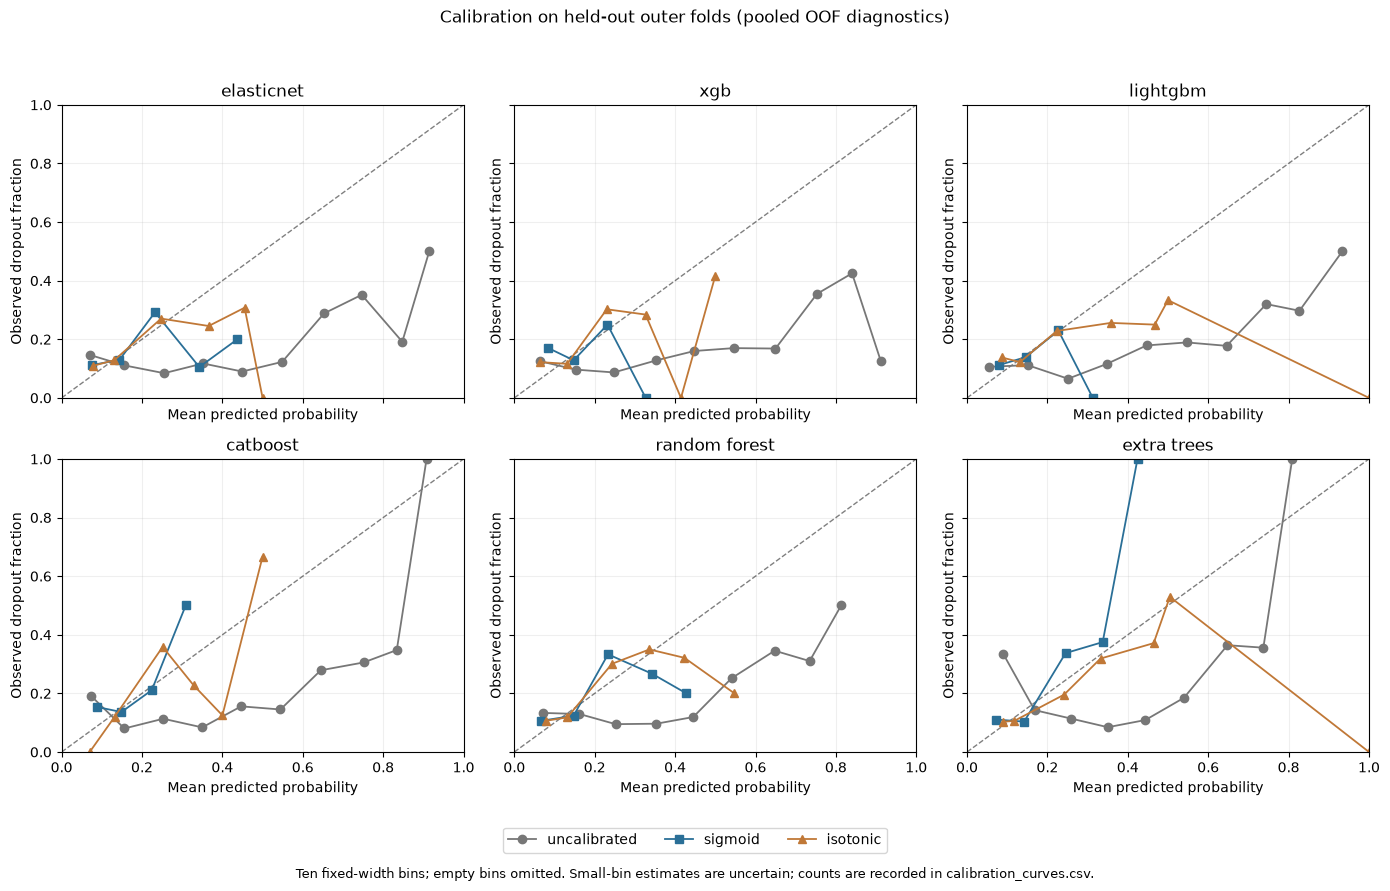

In [26]:
from src.model_calibration import evaluate_calibration

calibration_metrics, calibration_oof, calibration_curves = evaluate_calibration(
    train, cv_splits, capacity=INTERVENTION_CAPACITY
)
calibration_metrics.to_csv(OUT / "calibration_metrics.csv", index=False)
calibration_oof.to_csv(OUT / "calibration_oof_predictions.csv", index=False)
calibration_curves.to_csv(OUT / "calibration_curves.csv", index=False)
calibration_summary_columns = summary_columns + ["ece_10_equal_width"]
print(calibration_metrics.groupby(["model", "method"])[calibration_summary_columns].agg(["mean", "std"]).round(4).to_string())

from src.model_tuning import TUNING_GRIDS
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
styles = {"uncalibrated": ("#777777", "o"), "sigmoid": ("#2a6f97", "s"), "isotonic": ("#c07837", "^")}
for ax, model in zip(axes.flat, TUNING_GRIDS):
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, alpha=.5)
    for method, (color, marker) in styles.items():
        bins = calibration_curves.query("model == @model and method == @method and fold == 'pooled_oof' and n > 0")
        ax.plot(bins.mean_probability, bins.observed_rate, marker=marker, color=color, label=method, linewidth=1.3)
    ax.set_title(model.replace("_", " "))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(alpha=.2)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed dropout fraction")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(.5, .035))
fig.suptitle("Calibration on held-out outer folds (pooled OOF diagnostics)")
fig.text(.5, .015, "Ten fixed-width bins; empty bins omitted. Small-bin estimates are uncertain; counts are recorded in calibration_curves.csv.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, .09, 1, .95])
fig.savefig(FIG / "calibration_curves.png", dpi=300, bbox_inches="tight")
plt.show()


### Calibration findings

All six tuned families have lower mean Brier score after sigmoid calibration. Extra Trees changes from 0.1938 to 0.1180 and Random Forest from 0.1879 to 0.1205. Their mean ten-bin ECE falls from 0.2687 to 0.0493 and from 0.2528 to 0.0522, respectively. These improvements concern held-out training folds; later-period calibration is still unknown.

Every fitted sigmoid slope was positive, so each outer fold retained its ranking: AP and top-20% recall match the tuned uncalibrated model. Extra Trees remains at mean AP 0.3030 and recall 39.98%; Random Forest remains at AP 0.2942 and recall 41.63%. Calibration improved probability estimates rather than ranking performance in this run.

Isotonic sometimes has a slightly lower Brier score, but introduces probability ties and lowers mean AP across the six families in this experiment. It remains a sensitivity method, not an automatically selected winner. Sigmoid was specified as the primary method before scoring. Sparse-bin extremes in the pooled reliability curves should not be treated as precise risks; counts are available in the CSV. No final full-cohort model or temporal prediction has been produced.


### Performance by region and parental co-residence

This addresses the professor's request to report geographic and family co-residence performance. Use the existing **nested, training-only sigmoid-calibrated OOF predictions** for all six tuned model families; each child contributes one held-out prediction. No model is refitted or selected here, and no later-wave data are used. Region labels retain the original survey codes. Family groups are both parents, father only, mother only, neither parent, and unknown if either answer is missing. Co-residence means living in the household, not whether a parent is alive.

Pool the held-out predictions for descriptive subgroup AP, Brier score, calibration error and operational confusion counts. These pooled scores differ from the earlier mean of five fold scores. **Keep each fold's original top-20% selections**: do not choose a new top 20% within each subgroup. Consequently subgroup selection fractions can differ; recall and precision describe the same original intervention policy.

Report counts for every observed group. Flag n < 50, fewer than 10 events or non-events, or fewer than five districts as sparse: this is an analyst-defined caution rule, not an assignment requirement. AP is undefined for single-class groups. Use 500 reproducible district bootstrap draws for approximate 95% percentile intervals on AP, Brier, recall and precision in non-sparse groups; suppress intervals if fewer than 90% of draws define the metric. These intervals hold predictions fixed and do **not** include refitting/tuning uncertainty, survey weights or uncertainty due to attrition. ECE uses ten fixed-width bins and can be unstable in small groups.

These are descriptive results for observed children, not causal claims, population estimates or temporal generalization evidence. High/low-risk regional stratification and later-wave subgroup results remain separate work; do not define high-risk regions using these held-out outcomes.

In [27]:
from src.subgroup_evaluation import evaluate_subgroups

subgroup_metrics = evaluate_subgroups(train, calibration_oof, bootstrap_reps=500, random_state=42)
subgroup_metrics.to_csv(OUT / "subgroup_metrics.csv", index=False)
subgroup_columns = ["n", "events", "districts", "sparse_group", "average_precision", "brier_score",
                    "selected_fraction", "recall_under_fold_policy", "precision_under_fold_policy"]
print("Counts per subgroup (identical across models):")
display(subgroup_metrics.drop_duplicates(["dimension", "subgroup"])[["dimension", "subgroup", "n", "events", "districts", "sparse_group"]])
for subgroup_dimension in ["region", "parent_co_residence"]:
    print(subgroup_dimension, "— pooled held-out performance; intervals are in subgroup_metrics.csv")
    display(subgroup_metrics[subgroup_metrics.dimension.eq(subgroup_dimension)].set_index(["subgroup", "model"])[subgroup_columns].round(4))

Counts per subgroup (identical across models):


,dimension,subgroup,n,events,districts,sparse_group
0,overall,all,1307,188,136,False
1,region,region_1,141,19,10,False
2,region,region_10,72,33,5,False
3,region,region_2,83,10,15,False
4,region,region_3,101,9,8,True
5,region,region_4,89,5,13,True
6,region,region_5,124,9,19,True
7,region,region_6,224,19,26,False
8,region,region_7,135,18,18,False
9,region,region_8,200,56,16,False


region — pooled held-out performance; intervals are in subgroup_metrics.csv


,,n,events,districts,sparse_group,average_precision,brier_score,selected_fraction,recall_under_fold_policy,precision_under_fold_policy
subgroup,model,,,,,,,,,
region_1,catboost,141,19,10,False,0.0987,0.1217,0.1064,0.0526,0.0667
region_10,catboost,72,33,5,False,0.4447,0.3178,0.8889,0.9091,0.4688
region_2,catboost,83,10,15,False,0.1949,0.1051,0.0964,0.2000,0.2500
region_3,catboost,101,9,8,True,0.1187,0.0837,0.0198,0.1111,0.5000
region_4,catboost,89,5,13,True,0.2919,0.0579,0.0337,0.2000,0.3333
region_5,catboost,124,9,19,True,0.0864,0.0730,0.0887,0.1111,0.0909
region_6,catboost,224,19,26,False,0.0912,0.0826,0.0536,0.0000,0.0000
region_7,catboost,135,18,18,False,0.1801,0.1159,0.1037,0.0556,0.0714
region_8,catboost,200,56,16,False,0.2315,0.2168,0.5800,0.5000,0.2414


parent_co_residence — pooled held-out performance; intervals are in subgroup_metrics.csv


,,n,events,districts,sparse_group,average_precision,brier_score,selected_fraction,recall_under_fold_policy,precision_under_fold_policy
subgroup,model,,,,,,,,,
both_parents,catboost,798,130,124,False,0.2187,0.1347,0.2531,0.4077,0.2624
father_only,catboost,48,10,33,True,0.3836,0.1615,0.3125,0.6000,0.4000
mother_only,catboost,262,23,92,False,0.1087,0.0834,0.0534,0.1304,0.2143
neither_parent,catboost,171,19,80,False,0.1644,0.0997,0.1228,0.1053,0.0952
unknown,catboost,28,6,17,True,0.4236,0.1666,0.2857,0.5000,0.3750
both_parents,elasticnet,798,130,124,False,0.2391,0.1337,0.2469,0.4769,0.3147
father_only,elasticnet,48,10,33,True,0.3000,0.1653,0.2917,0.4000,0.2857
mother_only,elasticnet,262,23,92,False,0.1231,0.0824,0.0611,0.1304,0.1875
neither_parent,elasticnet,171,19,80,False,0.2013,0.1006,0.1462,0.2632,0.2000


**Findings and limits.** The audit contains 96 rows: six models, each assessed overall, in ten survey regions and in five parental co-residence groups. Region codes 3, 4 and 5 have only 9, 5 and 9 observed dropout events and are flagged as sparse. Father-only (48 children, 10 events) and unknown co-residence (28 children, 6 events) are also flagged; their interval fields are intentionally blank.

All six configurations have lower observed recall for mother-only households than for both-parent households under the unchanged intervention policy. Mother-only includes 262 children and 23 observed dropout events; both-parent includes 798 children and 130 events. Across models, recall ranges from 4.3–13.0% versus 40.0–49.2%, respectively. For example, Random Forest selects 7 mother-only children and captures 1 of 23 dropouts (4.3% recall), compared with 215 selected and 64 of 130 captured (49.2%) in both-parent households. Its approximate fixed-prediction district-bootstrap recall intervals are 0.0–15.8% and 32.1–62.8%, respectively.

This exposes a limitation hidden by aggregate performance. Different subgroup prevalence, selection rates and small event counts complicate comparisons; the audit does not establish a causal explanation or a formal significance result. Do not infer from lower Brier scores alone that a lower-prevalence subgroup has better discrimination. No subgroup thresholds or pipeline settings have been changed based on these held-out results. Compare against the planned simple demographic baseline and examine later-wave subgroup performance under a frozen policy before claiming transferability. Attrition and model-fitting uncertainty remain outside these intervals.

### High-recall experiment: aim to miss very few dropout cases

The user requested an explicit 95% recall objective after the subgroup audit exposed low recall among mother-only households. This is an additional exploratory objective, not a replacement for the professor's PR-AUC and top-20% benchmarks. The same outer folds have already been inspected, so these results are not confirmatory; the later-wave cohort remains unscored.

**Prespecified search.** Compare six fixed model configurations (ElasticNet, XGBoost, LightGBM, CatBoost, Random Forest, Extra Trees), each with the original balanced-class weighting or twice the positive/dropout weight, and with or without the two direct `father_in_hh`/`mother_in_hh` predictors: 24 candidates. Other hyperparameters use the earlier fixed comparison settings, not settings selected from outer results. Parent education, parent-alive status, region, urban/rural and KNN stay unchanged. Removing two indicators does not remove all indirect family information.

**Selection within training only.** For each outer training partition, obtain three-fold district-grouped OOF scores for every candidate. Fit preprocessing and compute class weights only on each inner training partition. For each candidate, choose the highest inclusive score threshold that attains empirical 95% recall overall and in each co-residence group with at least 10 training dropout events. Tied scores are all included. The 10-event rule is an analyst-defined minimum, not a guarantee of precision. Select the candidate flagging the smallest fraction of the training OOF cohort; break ties by higher inner pooled AP, then fixed candidate order. These inner scores are selection evidence, not independent performance estimates. Nonconverged candidates are ineligible.

Refit only the chosen candidate on the complete outer training partition, freeze its learned threshold, and score the held-out districts. Report realized recall, missed cases, precision, alert workload and group performance, including groups below the event minimum. Also retain top-20% recall for the selected candidate. The minimum workload is within this finite search only; there is no claim of a globally optimal model or a guaranteed 95% future recall.

**Score interpretation.** This separate experiment uses raw model scores for decisions; they are not calibrated probabilities. Existing calibrated models and their results remain unchanged. A threshold learned from inner OOF scores can transfer imperfectly to the refitted model; the outer results explicitly measure that limitation. Different outer folds may choose different families, so pooled AP/calibration is not reported for their incomparable raw score scales. Report pooled confusion counts and subgroup recall for the complete selection procedure instead. Subgroup sparsity flags use the earlier rule; no confidence or fairness guarantee is asserted.

Outputs: `high_recall_selection.csv`, `high_recall_metrics.csv`, `high_recall_oof_predictions.csv`, `high_recall_subgroup_metrics.csv`. Neither the model family nor the threshold is selected using later-wave labels. See [threshold-selection guidance](https://scikit-learn.org/stable/modules/classification_threshold.html).

In [28]:
from src.high_recall_evaluation import evaluate_high_recall

high_recall_selection, high_recall_metrics, high_recall_oof, high_recall_subgroups = evaluate_high_recall(
    train, cv_splits, target=.95
)
high_recall_selection.to_csv(OUT / "high_recall_selection.csv", index=False)
high_recall_metrics.to_csv(OUT / "high_recall_metrics.csv", index=False)
high_recall_oof.to_csv(OUT / "high_recall_oof_predictions.csv", index=False)
high_recall_subgroups.to_csv(OUT / "high_recall_subgroup_metrics.csv", index=False)
print("Held-out fold results for the training-selected procedure:")
display(high_recall_metrics[["fold", "model", "positive_multiplier", "include_parent_indicators", "threshold",
                           "recall", "target_met", "selected_fraction", "precision", "fn", "top20_recall"]].round(4))
print("Pooled decisions and family subgroup results (no pooled raw-score AP):")
display(high_recall_subgroups[high_recall_subgroups.dimension.isin(["overall", "parent_co_residence"])][
    ["dimension", "subgroup", "n", "events", "selected_n", "selected_fraction", "tp", "fn", "recall", "precision", "target_met", "sparse_group"]].round(4))

High-recall outer fold 1/5: selecting on training only


Selected {'model': 'random_forest', 'positive_multiplier': 2.0, 'include_parent_indicators': False}; held-out recall 1.000, flagged 1.000


High-recall outer fold 2/5: selecting on training only


Selected {'model': 'elasticnet', 'positive_multiplier': 2.0, 'include_parent_indicators': False}; held-out recall 0.971, flagged 0.996


High-recall outer fold 3/5: selecting on training only


...

Selected {'model': 'random_forest', 'positive_multiplier': 2.0, 'include_parent_indicators': False}; held-out recall 1.000, flagged 1.000


Held-out fold results for the training-selected procedure:


,fold,model,positive_multiplier,include_parent_indicators,threshold,recall,target_met,selected_fraction,precision,fn,top20_recall
0,1,random_forest,2.0,False,0.2397,1.0000,True,1.0000,0.1434,0,0.4737
1,2,elasticnet,2.0,False,0.0680,0.9706,True,0.9960,0.1315,1,0.2941
2,3,random_forest,1.0,True,0.1276,0.9535,True,0.9556,0.1589,2,0.4651
3,4,elasticnet,2.0,True,0.0816,1.0000,True,0.9611,0.1377,0,0.2647
4,5,random_forest,2.0,False,0.2261,1.0000,True,1.0000,0.1483,0,0.4103


Pooled decisions and family subgroup results (no pooled raw-score AP):


,dimension,subgroup,n,events,selected_n,selected_fraction,tp,fn,recall,precision,target_met,sparse_group
0,overall,all,1307,188,1284,0.9824,185,3,0.9840,0.1441,True,False
11,parent_co_residence,both_parents,798,130,794,0.9950,128,2,0.9846,0.1612,True,False
12,parent_co_residence,father_only,48,10,48,1.0000,10,0,1.0000,0.2083,True,True
13,parent_co_residence,mother_only,262,23,248,0.9466,22,1,0.9565,0.0887,True,False
14,parent_co_residence,neither_parent,171,19,166,0.9708,19,0,1.0000,0.1145,True,False
15,parent_co_residence,unknown,28,6,28,1.0000,6,0,1.0000,0.2143,True,True


**Observed result.** Across the 1,307 held-out children, the training-selected procedure flags 1,284 (98.2%), catches 185 of 188 observed dropouts (98.4% recall), and misses 3. Precision is 14.4%. It reaches the 95% overall target in 5 of five outer folds. For mother-only households it catches 22 of 23 dropouts (95.7%), while flagging 248 of 262 children. Family groups below the target: none in this observed sample.

**Workload matters.** Flagging every child would catch all 188 observed dropouts and flag 1,307 children. This fitted procedure saves only 23 screening places relative to that universal policy, while missing 3 observed dropout cases. Its high recall is therefore achieved through near-universal screening, not a strong improvement in selective identification. The 95% criterion is an empirical training objective, not a guarantee on new cohorts or small groups. Sparse subgroup results remain uncertain.

Settings vary by outer training partition; this does not establish a single best family, weight multiplier or parental-feature decision. No final full-data model has been fitted, and no temporal predictions have been made. Keep this as an experimental high-recall procedure alongside the existing calibrated models and top-20% benchmark. The next useful improvement is to investigate stronger baseline predictors and broader screening workflows; do not tune again on these outer results or silently replace the main pipeline. A later-wave evaluation must test a frozen procedure before any transferability claim.

**Regional caution.** The three misses occur in region codes 3 (7 of 9 caught; 77.8% recall) and 5 (8 of 9 caught; 88.9%). Both regions are sparse by the prespecified event-count rule. Thus reaching 95% overall and in the observed co-residence groups does not establish 95% recall in every region.

### Balanced precision and recall: training-only F1 selection

The user explicitly selected a balance between missed dropouts and false alarms after the high-recall experiment flagged nearly everyone. This experiment maximizes F1, the harmonic mean of precision and recall: `2TP / (2TP + FP + FN)`. F1 penalizes both false positives and false negatives, but does not encode a monetary cost or guarantee high precision/recall separately. Keep the professor's PR-AUC/top-20% reporting and the earlier high-recall experiment as benchmarks.

**Prespecified candidate set:** the six fixed comparison model families; positive/dropout class-weight multipliers 0.5, 1 and 2; and retaining or removing only the two direct parental co-residence indicators. These 36 configurations vary weighting and family features while retaining all other fixed comparison settings. Half-strength weighting is included to test less emphasis on dropout cases; it is not a guarantee of fewer false alarms. Shared preprocessing is fitted independently in every training partition. Class weights use that partition's labels only. KNN and other family variables remain unchanged.

**Nested selection:** within each of the five original district-grouped outer folds, obtain three-fold grouped inner OOF scores per candidate. Choose its inclusive score threshold maximizing empirical inner F1 over all unique scores; include all exact ties. If threshold F1 ties, prefer fewer flags. Select the candidate by highest inner F1, then fewer flags, higher inner AP and fixed candidate order. Refit only the selected candidate on the complete outer training partition, freeze its threshold, and score the held-out districts. Failed convergence makes a candidate ineligible. Inner performance is selection evidence, not independent validation. Scores are uncalibrated decision scores, not individual probability estimates; transfer from inner to refitted scores is evaluated by the outer results.

Report false alarms, misses, precision, recall, F1 and workload, plus region/co-residence performance. F1 selection has no subgroup recall guarantee; sparse subgroup flags remain necessary. Different outer folds may choose different model families, so do not pool raw scores for AP or calibration. Compare pooled decisions with all six existing sigmoid-calibrated top-20% benchmarks, the high-recall experiment and flagging everyone; these comparisons do not enter model/threshold selection.

This is exploratory work on repeatedly inspected outer folds. No later-wave data are used, no final model is chosen from outer results, and no deployment claim follows. A revised objective can improve the trade-off without making weak predictors highly accurate. See [decision-threshold guidance](https://scikit-learn.org/stable/modules/classification_threshold.html).

Outputs: `balanced_risk_selection.csv`, `balanced_risk_metrics.csv`, `balanced_risk_oof_predictions.csv`, `balanced_risk_subgroup_metrics.csv`, `balanced_risk_comparison.csv`.

In [29]:
from src.balanced_risk_evaluation import evaluate_balanced_risk, compare_policies

balanced_selection, balanced_metrics, balanced_oof, balanced_subgroups = evaluate_balanced_risk(train, cv_splits)
balanced_comparison = compare_policies(train, balanced_oof, calibration_oof, high_recall_oof)
balanced_selection.to_csv(OUT / "balanced_risk_selection.csv", index=False)
balanced_metrics.to_csv(OUT / "balanced_risk_metrics.csv", index=False)
balanced_oof.to_csv(OUT / "balanced_risk_oof_predictions.csv", index=False)
balanced_subgroups.to_csv(OUT / "balanced_risk_subgroup_metrics.csv", index=False)
balanced_comparison.to_csv(OUT / "balanced_risk_comparison.csv", index=False)
print("Held-out results for the training-selected balanced procedure:")
display(balanced_metrics[["fold", "model", "positive_multiplier", "include_parent_indicators", "threshold",
                          "precision", "recall", "f1", "selected_fraction", "tp", "fp", "fn"]].round(4))
print("Pooled policy comparison; no selection uses these results:")
display(balanced_comparison[["policy", "selected_n", "tp", "fp", "fn", "precision", "recall", "f1"]].round(4))
print("Family subgroup performance:")
display(balanced_subgroups[balanced_subgroups.dimension.eq("parent_co_residence")][
    ["subgroup", "n", "events", "selected_n", "tp", "fp", "fn", "precision", "recall", "f1", "sparse_group"]].round(4))

Balanced outer fold 1/5: training-only F1 selection


Selected {'model': 'extra_trees', 'positive_multiplier': 0.5, 'include_parent_indicators': True}; precision 0.436, recall 0.447, flagged 0.147


Balanced outer fold 2/5: training-only F1 selection


Selected {'model': 'elasticnet', 'positive_multiplier': 0.5, 'include_parent_indicators': False}; precision 0.171, recall 0.412, flagged 0.325


Balanced outer fold 3/5: training-only F1 selection


...

,fold,model,positive_multiplier,include_parent_indicators,threshold,precision,recall,f1,selected_fraction,tp,fp,fn
0,1,extra_trees,0.5,True,0.3975,0.4359,0.4474,0.4416,0.1472,17,22,21
1,2,elasticnet,0.5,False,0.4701,0.1707,0.4118,0.2414,0.3254,14,68,20
2,3,extra_trees,0.5,True,0.3215,0.4118,0.4884,0.4468,0.1889,21,30,22
3,4,extra_trees,1.0,True,0.4571,0.1944,0.2059,0.2000,0.1401,7,29,27
4,5,random_forest,2.0,True,0.5963,0.3256,0.3590,0.3415,0.1635,14,29,25


Pooled policy comparison; no selection uses these results:


,policy,selected_n,tp,fp,fn,precision,recall,f1
0,balanced_F1,251,73,178,115,0.2908,0.3883,0.3326
1,high_recall,1284,185,1099,3,0.1441,0.9840,0.2514
2,catboost_top20,260,67,193,121,0.2577,0.3564,0.2991
3,elasticnet_top20,260,77,183,111,0.2962,0.4096,0.3438
4,extra_trees_top20,260,76,184,112,0.2923,0.4043,0.3393
5,lightgbm_top20,260,66,194,122,0.2538,0.3511,0.2946
6,random_forest_top20,260,79,181,109,0.3038,0.4202,0.3527
7,xgb_top20,260,69,191,119,0.2654,0.3670,0.3080
8,flag_everyone,1307,188,1119,0,0.1438,1.0000,0.2515


Family subgroup performance:


,subgroup,n,events,selected_n,tp,fp,fn,precision,recall,f1,sparse_group
11,both_parents,798,130,199,59,140,71,0.2965,0.4538,0.3587,False
12,father_only,48,10,12,5,7,5,0.4167,0.5000,0.4545,True
13,mother_only,262,23,15,3,12,20,0.2000,0.1304,0.1579,False
14,neither_parent,171,19,19,2,17,17,0.1053,0.1053,0.1053,False
15,unknown,28,6,6,4,2,2,0.6667,0.6667,0.6667,True


**Observed result, not a performance guarantee.** The balanced procedure flags 251 of 1,307 children (19.2%), catches 73 of 188 observed dropouts (38.8% recall), and produces 178 false alarms. Precision is 29.1% and pooled decision F1 is 0.333; 115 dropout cases remain missed. These counts come from the held-out folds, not the scores used to select settings.

Compared with the earlier high-recall procedure, false alarms decrease from 1099 to 178, while missed dropouts increase from 3 to 115. This is a trade-off, not a simultaneous solution to both errors. Across the six established tuned/calibrated top-20% benchmarks, F1 ranges from 0.295 to 0.353; the complete comparison above must remain visible rather than reporting only the favorable comparison against flagging nearly everyone.

For mother-only households, this procedure flags 15 of 262 children, catches 3 of 23 dropouts (13.0%), and produces 12 false alarms. Overall F1 optimization does not ensure good performance for every group. Regional and family counts, missed cases and sparse-group flags are retained in `balanced_risk_subgroup_metrics.csv`.

The procedure corrects the previous objective's incentive to achieve recall through near-universal screening, but does not establish that the current predictors can identify most dropouts with few false alarms. No main pipeline replacement or final model promotion is automatic. Preserve this experiment and inspect stronger baseline predictors before claiming a reliable system; freeze a final procedure before later-wave evaluation. The repeatedly inspected outer folds limit confirmatory interpretation.

**Adoption decision: do not replace the existing pipeline with this experiment.** The existing Random Forest top-20% benchmark catches 79 cases with 181 false alarms (F1 0.353), whereas the balanced procedure catches 73 with 178 false alarms (F1 0.333). Saving only three false alarms while missing six additional dropout cases does not improve the chosen balance. This is descriptive evidence on the reused folds, not a formal significance claim. Stronger baseline predictors require investigation; the goal of catching most dropouts with few false alarms remains unmet.

## 13. Save the processed data and the decision log

In [30]:
def save(frame, X, y, name):
    if name.startswith("test"):
        frame = frame.assign(in_primary_test=test_cohorts.in_primary_test.to_numpy(dtype=int),
                             in_secondary_test=test_cohorts.in_secondary_test.to_numpy(dtype=int))
    out = pd.concat([X[ID_COLS].reset_index(drop=True), frame.reset_index(drop=True), y.reset_index(drop=True)], axis=1)
    out.to_csv(PROC / name, index=False)
    return out.shape

shapes = {
    "train_processed_xgb.csv": save(Xtr_xgb, X_train, y_train, "train_processed_xgb.csv"),
    "test_processed_xgb.csv": save(Xte_xgb.assign(in_both_tables=test_in_train.astype(int).values), X_test, y_test, "test_processed_xgb.csv"),
    "train_processed_lr.csv": save(Xtr_lr, X_train, y_train, "train_processed_lr.csv"),
    "test_processed_lr.csv": save(Xte_lr.assign(in_both_tables=test_in_train.astype(int).values), X_test, y_test, "test_processed_lr.csv"),
}
for k, v in shapes.items():
    print(f"data/processed/{k}: {v[0]} rows x {v[1]} columns")

data/processed/train_processed_xgb.csv: 1307 rows x 59 columns
data/processed/test_processed_xgb.csv: 1395 rows x 62 columns
data/processed/train_processed_lr.csv: 1307 rows x 54 columns
data/processed/test_processed_lr.csv: 1395 rows x 57 columns


In [31]:
planned = ("persons_per_room", "orphan", "grade_level")
n_match = int((fold_drops[["drop 1", "drop 2", "drop 3"]].apply(tuple, axis=1) == planned).sum())
lr_pr = cv_results.query("model == 'lr' and variant == 'Phase 1 plan'")["PR-AUC (mean)"].item()
lr_med = cv_results.query("model == 'lr' and variant != 'Phase 1 plan'")["PR-AUC (mean)"].item()
log = pd.DataFrame([
    ["Fix recording errors", "Fixed rules (codes, impossible values)", "Applied in 01_build_dataset; nothing learned", "As planned"],
    ["Inflation adjustment", "Convert 2013/14 money to 2009/10 prices (CPI)", f"Factor {CPI_FACTOR_W2_TO_W1:.2f} (World Bank CPI, weighted by interview months)", "Fixed external price adjustment; other distribution changes remain"],
    ["Split", "By time; primary new households; secondary new people", f"X_train {len(X_train)}, all temporal {len(X_test)}, primary {test_cohorts.in_primary_test.sum()}, secondary {test_cohorts.in_secondary_test.sum()}", "As planned"],
    ["Hours missed", "Blank = 0 when attendance recorded; median otherwise", f"Rule applied; CV PR-AUC (LR) {lr_pr} vs {lr_med} with median fill (descriptive comparison; uncertainty retained)", "Sensitivity comparison; no formal equivalence claim"],
    ["Was-missing flags", "4 flags before filling", "teacher absent, hours attended, father's and mother's education", "As planned"],
    ["Was-missing flags across periods", "Compare flags between periods", "All four flags are less frequent later; relative frequencies differ by feature (see section 11); survey mode alone does not identify the cause", "Confirmed limitation"],
    ["Filling gaps", "Mean / median / mode by skew; 'missing' option for school type", "SimpleImputer fitted on X_train", "As planned"],
    ["School grade", "Mixed-distance KNN with training-only k selection", f"Inner-grouped k={pre_xgb.named_steps['grade_knn'].n_neighbors_} on full training; over-age recalculated", "Revised and validated"],
    ["Repeating features", "Spearman |rho| >= 0.85, VIF > 10; drop 3; re-check in each fold", f"MI-only diagnostic matched the structural list in {n_match}/5 folds; removal is fixed from source identities/domain meaning, not MI; rebuilt exactly including unknowns", "Fixed structural list; MI-only check is descriptive"],
    ["Extreme values", "Log-IQR cap on travel, household size, rooms", f"Limits {', '.join(f'{v:.1f}' for v in limits.values())}; {sum(capped_train.values())} capped (train)", "As planned"],
    ["Money", "Rank 0-1 against model-building values", "TrainingRank fitted on X_train", "As planned"],
    ["Encoding", "One-hot, ordinal, 0/1", f"{Xtr_xgb.shape[1]} columns (XGBoost), {Xtr_lr.shape[1]} (LR)", "As planned"],
    ["Scaling", "None for XGBoost; log + StandardScaler for LR and PCA", f"PCA: {k90} components for 90%, {k95} for 95%", "As planned"],
    ["Cross-validation", "5 folds, stratified, grouped by district", "StratifiedGroupKFold; 0 shared districts or households", "As planned"],
    ["Class imbalance", "Class weighting, recalculated per fold", "scale_pos_weight / class_weight='balanced'", "As planned"],
    ["Calibration, final test", "Training-only nested tuning/calibration; frozen retrospective temporal evaluation", "Nested training-only sigmoid/isotonic calibration; temporal results recorded by the final decision-log cell", "See final executed decision log"],
], columns=["Step", "Planned in Phase 1", "Implemented in Phase 2", "Status"])
log.to_csv(OUT / "decision_log.csv", index=False)
pd.set_option("display.max_colwidth", 90)
print(log.to_string(index=False))

                            Step                                                                Planned in Phase 1                                                                                                                                          Implemented in Phase 2                                                             Status
            Fix recording errors                                            Fixed rules (codes, impossible values)                                                                                                                    Applied in 01_build_dataset; nothing learned                                                         As planned
            Inflation adjustment                                     Convert 2013/14 money to 2009/10 prices (CPI)                                                                                                      Factor 1.62 (World Bank CPI, weighted by interview months) Fixed external price adjustment; other di

### Baseline-wave education enrichment: controlled experiment

Preserve the professor-praised longitudinal cohorts, mixed-distance grade KNN, redundant-feature removal, log-IQR handling and grouped validation. The added predictors are a data-informed extension, not a claim that the professor explicitly requested them. The attendance blank-to-zero rule is unchanged here to isolate the new features.

Three prespecified variants: baseline; literacy plus funding; literacy plus funding plus routed teacher absence and teaching arrangement. Keep all six fixed comparison model families, original five district-grouped outer folds and household separation. The baseline variant ignores every added column. All learned preprocessing is refitted within training partitions; no final temporal evaluation occurs here. Both enriched CSV exports preserve the original columns and labels, with target last.

Report average precision (PR-AUC), recall/precision at top 20%, and family/region subgroup results. For the user's preference to tolerate false alarms rather than miss dropouts, additionally learn an inclusive F2-maximizing threshold from three grouped inner OOF folds (seed 842 + outer fold). F2 emphasizes recall; it is not a monetary cost ratio or guaranteed recall. Threshold ties prefer fewer alerts. Freeze thresholds before outer scoring. Fit unweighted sigmoid calibration on inner OOF scores and report held-out Brier score, ECE and calibration bins. Raw-score ranking/top-20 and F2 decisions remain separate from calibrated probabilities. No hyperparameter search or model selection is performed in this feature experiment.

Compare each variant with its own fixed-model baseline; older tuned/calibrated results are separate benchmarks. The outer folds have been explored repeatedly, so improvements remain exploratory. Added features may also shift across survey waves. Retain the professor's temporal, drift, attrition, interpretability and final-report requirements for subsequent steps; this experiment does not complete them or establish deployment readiness.


In [32]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from src.feature_enrichment import export_enriched
from src.enrichment_evaluation import evaluate_enrichment

enriched_exports = export_enriched(ROOT)
enriched_train = enriched_exports['train_w1_w2']
enrichment_splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(
    enriched_train, enriched_train.dropout, enriched_train.district_id))
enrichment_metrics, enrichment_oof, enrichment_subgroups, enrichment_curves = evaluate_enrichment(
    enriched_train, enrichment_splits)
for name, frame in [('metrics', enrichment_metrics), ('oof_predictions', enrichment_oof),
                    ('subgroup_metrics', enrichment_subgroups), ('calibration_curves', enrichment_curves)]:
    frame.to_csv(OUT / f'enrichment_{name}.csv', index=False)
display(enrichment_metrics.groupby(['variant','model'])[
    ['average_precision','top20_recall','top20_precision','calibrated_brier','recall','precision','selected_fraction']].mean().round(4))
display(enrichment_subgroups[enrichment_subgroups.dimension.eq('overall')][
    ['variant','model','policy','selected_n','tp','fp','fn','precision','recall']].round(4))


Enrichment fold 1/5: baseline


Finished six families, inner thresholds and sigmoid calibration


Enrichment fold 1/5: literacy_funding


Finished six families, inner thresholds and sigmoid calibration


Enrichment fold 1/5: literacy_funding_teacher


...

Finished six families, inner thresholds and sigmoid calibration


Enrichment fold 5/5: literacy_funding_teacher


Finished six families, inner thresholds and sigmoid calibration


average_precision  top20_recall  \
variant                  model                                            
baseline                 catboost                  0.2533        0.3606   
                         elasticnet                0.2684        0.3826   
                         extra_trees               0.2856        0.4054   
                         lightgbm                  0.2334        0.3337   
                         random_forest             0.2869        0.3940   
                         xgb                       0.2519        0.3539   
literacy_funding         catboost                  0.2575        0.3569   
                         elasticnet                0.2750        0.3563   
                         extra_trees               0.2924        0.3882   
                         lightgbm                  0.2399        0.3304   
                         random_forest             0.2906        0.3985   
                         xgb                       0.2552        0.3204   
literacy_funding_teacher catboost                  0.2632        0.3301   
                         elasticnet                0.2705        0.3408   
                         extra_trees               0.2818        0.4104   
                         lightgbm                  0.2491        0.3203   
                         random_forest             0.2890        0.3998   
                         xgb                       0.2553        0.3152   

                                        top20_precision  calibrated_brier  \
variant                  model                                              
baseline                 catboost                0.2633            0.1213   
                         elasticnet              0.2788            0.1201   
                         extra_trees             0.2948            0.1180   
                         lightgbm                0.2412            0.1217   
                         random_forest           0.2868            0.1182   
                         xgb                     0.2565            0.1215   
literacy_funding         catboost                0.2600            0.1213   
                         elasticnet              0.2597            0.1203   
                         extra_trees             0.2831            0.1172   
                         lightgbm                0.2407            0.1213   
                         random_forest           0.2905            0.1178   
                         xgb                     0.2331            0.1216   
literacy_funding_teacher catboost                0.2408            0.1215   
                         elasticnet              0.2483            0.1207   
                         extra_trees             0.2988            0.1177   
                         lightgbm                0.2333            0.1216   
                         random_forest           0.2908            0.1180   
                         xgb                     0.2293            0.1219   

                                        recall  precision  selected_fraction  
variant                  model                                                
baseline                 catboost       0.9510     0.1447             0.9453  
                         elasticnet     0.9523     0.1438             0.9499  
                         extra_trees    0.7666     0.1633             0.7130  
                         lightgbm       0.9057     0.1448             0.8973  
                         random_forest  0.8557     0.1534             0.8205  
                         xgb            0.9603     0.1427             0.9663  
literacy_funding         catboost       0.9586     0.1431             0.9618  
                         elasticnet     0.9591     0.1446             0.9530  
                         extra_trees    0.9027     0.1604             0.8337  
                         lightgbm       0.9412     0.1470             0.9219  
                         random_forest  0.8106    

,variant,model,policy,selected_n,tp,fp,fn,precision,recall
0,baseline,catboost,F2,1234,178,1056,10,0.1442,0.9468
1,baseline,catboost,top20,260,69,191,119,0.2654,0.3670
32,baseline,elasticnet,F2,1240,178,1062,10,0.1435,0.9468
33,baseline,elasticnet,top20,260,73,187,115,0.2808,0.3883
64,baseline,extra_trees,F2,930,144,786,44,0.1548,0.7660
65,baseline,extra_trees,top20,260,77,183,111,0.2962,0.4096
96,baseline,lightgbm,F2,1173,171,1002,17,0.1458,0.9096
97,baseline,lightgbm,top20,260,63,197,125,0.2423,0.3351
128,baseline,random_forest,F2,1070,160,910,28,0.1495,0.8511
129,baseline,random_forest,top20,260,75,185,113,0.2885,0.3989


In [33]:
# Paired descriptive summary; never used to select features or thresholds.
summary_columns_enrichment = ['average_precision','top20_recall','top20_precision',
    'calibrated_brier','recall','precision','selected_fraction']
enrichment_summary = enrichment_metrics.groupby(['variant','model'])[summary_columns_enrichment].mean().reset_index()
enrichment_baseline = enrichment_summary[enrichment_summary.variant.eq('baseline')].set_index('model')
for column in summary_columns_enrichment:
    enrichment_summary[column + '_change_vs_baseline'] = (
        enrichment_summary[column] - enrichment_summary.model.map(enrichment_baseline[column]))
enrichment_summary.to_csv(OUT / 'enrichment_summary.csv', index=False)
display(enrichment_summary[['variant','model','average_precision',
                           'average_precision_change_vs_baseline','top20_recall']].round(4))


,variant,model,average_precision,average_precision_change_vs_baseline,top20_recall
0,baseline,catboost,0.2533,0.0000,0.3606
1,baseline,elasticnet,0.2684,0.0000,0.3826
2,baseline,extra_trees,0.2856,0.0000,0.4054
3,baseline,lightgbm,0.2334,0.0000,0.3337
4,baseline,random_forest,0.2869,0.0000,0.3940
5,baseline,xgb,0.2519,0.0000,0.3539
6,literacy_funding,catboost,0.2575,0.0042,0.3569
7,literacy_funding,elasticnet,0.2750,0.0066,0.3563
8,literacy_funding,extra_trees,0.2924,0.0068,0.3882
9,literacy_funding,lightgbm,0.2399,0.0065,0.3304


### Enrichment findings and decision

All three variants were evaluated across the same five outer district folds and six fixed families (90 outer evaluations; 23,526 held-out prediction records). Inner three-fold predictions fitted F2 thresholds and sigmoid calibration; model hyperparameters stayed fixed. Independent verification reproduced all six earlier fixed-model baseline predictions exactly (maximum absolute difference 0), including top-20% decisions. All original source modules and processed baseline datasets retained their checksums. Both added notebook sections executed successfully in a fresh kernel; all 59 unit tests passed, including questionnaire mapping, unique joins, target-last preservation, threshold correctness and nested training boundaries.

**Ranking:** literacy plus funding raised mean fold AP for every fixed family, by 0.0033--0.0068. Extra Trees increased from 0.2856 to 0.2924 and Random Forest from 0.2869 to 0.2906. These small differences are exploratory, not evidence of a statistically established improvement. The later-wave test cohort remains unscored.

**Fixed workload:** improvements in AP did not consistently translate to more dropouts in the top 20%. Random Forest caught 75/188 at baseline and 76/188 with literacy/funding, with 260 children selected in both cases. Extra Trees fell from 77 to 74. Adding teacher routing increased Extra Trees' count to 78 but reduced its mean AP to 0.2818. The earlier tuned/sigmoid Random Forest caught 79 at the same workload; the new experiment does not beat that existing benchmark on this policy. Comparisons with tuned models have a different tuning protocol and are context, not controlled feature-effect estimates.

**Recall-focused policy:** literacy/funding Random Forest's inner-selected F2 thresholds caught 152/188 dropouts (80.9%), missed 36 and flagged 888/1,307 children (67.9%): 736 false alarms, precision 17.1%. Its baseline F2 policy caught 160, missed 28 and flagged 1,070, with 910 false alarms. Thus the added features reduced workload and false alarms for this procedure but also reduced overall recall. Mother-only households improved from 12/23 to 14/23 caught, while false alarms fell from 167 to 120; this remains insufficient subgroup recall and does not establish fairness. Other models reached higher recall mainly by flagging most children. F2 alone does not solve weak separation.

**Decision:** retain literacy/funding and teacher routing as documented experiments, without replacing the default pipeline or declaring a winning model from these repeatedly explored outer folds. Preserve the professor-praised KNN, redundant-feature removal, cohort construction and grouped validation. A next controlled step could test training-only tuning of literacy/funding; broadening features or lowering thresholds is not a guarantee of improvement. Operational capacity and future temporal/regional evaluation remain necessary. The professor's remaining interpretability and final-report requirements are not completed by this experiment.

Files: separate `train_w1_w2_enriched.csv` and `test_w2_w3_enriched.csv` (1,307 and 1,395 rows, 45 columns, target last); `enrichment_metrics.csv`, `enrichment_oof_predictions.csv`, `enrichment_subgroup_metrics.csv`, `enrichment_calibration_curves.csv`, `enrichment_summary.csv`. Original tables remain unchanged. Teacher routing recovers 70 training answers and excludes 11 recorded answers inconsistent with the teacher arrangement (net +59 observed); it is not a claim of improved performance or a count of total instruction days lost.


### Nested tuning of literacy/funding: false alarms at an inner 80% recall target

User-approved follow-up to the feature experiment. Preserve the professor-praised KNN, redundant-feature removal, outlier treatment and longitudinal cohorts. Retain all six recommended model families, AP-based model tuning, top-20% reporting, calibration, and region/family subgroup checks. Only the literacy/funding feature extension is used; teacher routing and the attendance rule stay at the original baseline setting.

Compare fixed settings with the original four-candidate tuning grid per family. Selection maximizes mean AP across three district-grouped inner folds, with stable candidate-order ties. For calibration/threshold fitting, generate three-fold training OOF scores; **retune each model inside each OOF training subset**, so its validation labels do not influence hyperparameter selection. Refit all learned preprocessing within every fit partition. Then choose the highest inclusive raw-score threshold capturing at least 80% of inner OOF dropouts (ceil of the required event count); include all tied scores. This target approximates the user's requested comparison around 81% recall and is declared before observing results. It is an empirical training target, not a guarantee or subgroup constraint.

Fit sigmoid calibration on these training-only OOF scores. Re-select hyperparameters using the complete outer training partition, refit, freeze the raw threshold and calibrator, and evaluate on untouched outer-fold districts. Keep the original five outer folds (seed 42); threshold/calibration folds use seed 942 + outer fold, their internal searches 1942 + 10*outer fold + inner fold, and final searches 142 + outer fold. Households cannot cross district folds. Fixed and tuned versions use the same folds and target. Compare **observed** recall, false alarms and workload together; fewer false alarms accompanied by lower recall is not a same-recall improvement. No held-out label selects any threshold, feature, model family or hyperparameter.

Report mean fold AP, top-20% recall/precision, sigmoid Brier/ECE and reliability bins, operational confusion counts, and family/region results. Raw scores define ranking and decisions; calibrated probabilities are reported separately. Existing results remain preserved. The repeatedly explored outer folds make this exploratory; no overall winner is deployed, and the later-wave test cohort remains unscored. Temporal drift, attrition limitations and the remaining professor recommendations still apply.


In [34]:
from src.enrichment_tuning import evaluate_enrichment_tuning
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

tuning_enriched_train = pd.read_csv(ROOT / 'data/processed/train_w1_w2_enriched.csv')
tuning_enriched_splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(
    tuning_enriched_train, tuning_enriched_train.dropout, tuning_enriched_train.district_id))
(enriched_search, enriched_tuning_metrics, enriched_tuning_oof,
 enriched_tuning_subgroups, enriched_tuning_curves) = evaluate_enrichment_tuning(
    tuning_enriched_train, tuning_enriched_splits, target=.80)
for name, frame in [('search', enriched_search), ('metrics', enriched_tuning_metrics),
                    ('oof_predictions', enriched_tuning_oof), ('subgroup_metrics', enriched_tuning_subgroups),
                    ('calibration_curves', enriched_tuning_curves)]:
    frame.to_csv(OUT / f'enrichment_tuning_{name}.csv', index=False)
enriched_tuning_summary = enriched_tuning_metrics.groupby(['setting','model'])[
    ['average_precision','top20_recall','top20_precision','calibrated_brier','calibrated_ece']].mean().reset_index()
enriched_tuning_summary.to_csv(OUT / 'enrichment_tuning_summary.csv', index=False)
display(enriched_tuning_summary.round(4))
display(enriched_tuning_subgroups[enriched_tuning_subgroups.dimension.eq('overall')][
    ['setting','model','policy','selected_n','tp','fp','fn','precision','recall']].round(4))


Enriched tuning: outer fold 1/5


  threshold/calibration fold 1/3: nested AP search


  threshold/calibration fold 2/3: nested AP search


  threshold/calibration fold 3/3: nested AP search


  elasticnet: outer fits complete


...

  catboost: outer fits complete


  random_forest: outer fits complete


  extra_trees: outer fits complete


,setting,model,average_precision,top20_recall,top20_precision,calibrated_brier,calibrated_ece
0,fixed,catboost,0.2575,0.3569,0.2600,0.1226,0.0277
1,fixed,elasticnet,0.2750,0.3563,0.2597,0.1212,0.0330
2,fixed,extra_trees,0.2924,0.3882,0.2831,0.1185,0.0253
3,fixed,lightgbm,0.2399,0.3304,0.2407,0.1225,0.0229
4,fixed,random_forest,0.2906,0.3985,0.2905,0.1192,0.0245
5,fixed,xgb,0.2552,0.3204,0.2331,0.1225,0.0253
6,tuned,catboost,0.2577,0.3780,0.2752,0.1221,0.0199
7,tuned,elasticnet,0.2644,0.3772,0.2749,0.1219,0.0323
8,tuned,extra_trees,0.2920,0.4098,0.2985,0.1187,0.0405
9,tuned,lightgbm,0.2611,0.3265,0.2370,0.1228,0.0306


,setting,model,policy,selected_n,tp,fp,fn,precision,recall
0,fixed,catboost,recall80,1111,165,946,23,0.1485,0.8777
1,fixed,catboost,top20,260,68,192,120,0.2615,0.3617
32,fixed,elasticnet,recall80,1042,159,883,29,0.1526,0.8457
33,fixed,elasticnet,top20,260,68,192,120,0.2615,0.3617
64,fixed,extra_trees,recall80,962,161,801,27,0.1674,0.8564
65,fixed,extra_trees,top20,260,74,186,114,0.2846,0.3936
96,fixed,lightgbm,recall80,1056,162,894,26,0.1534,0.8617
97,fixed,lightgbm,top20,260,63,197,125,0.2423,0.3351
128,fixed,random_forest,recall80,967,157,810,31,0.1624,0.8351
129,fixed,random_forest,top20,260,76,184,112,0.2923,0.4043


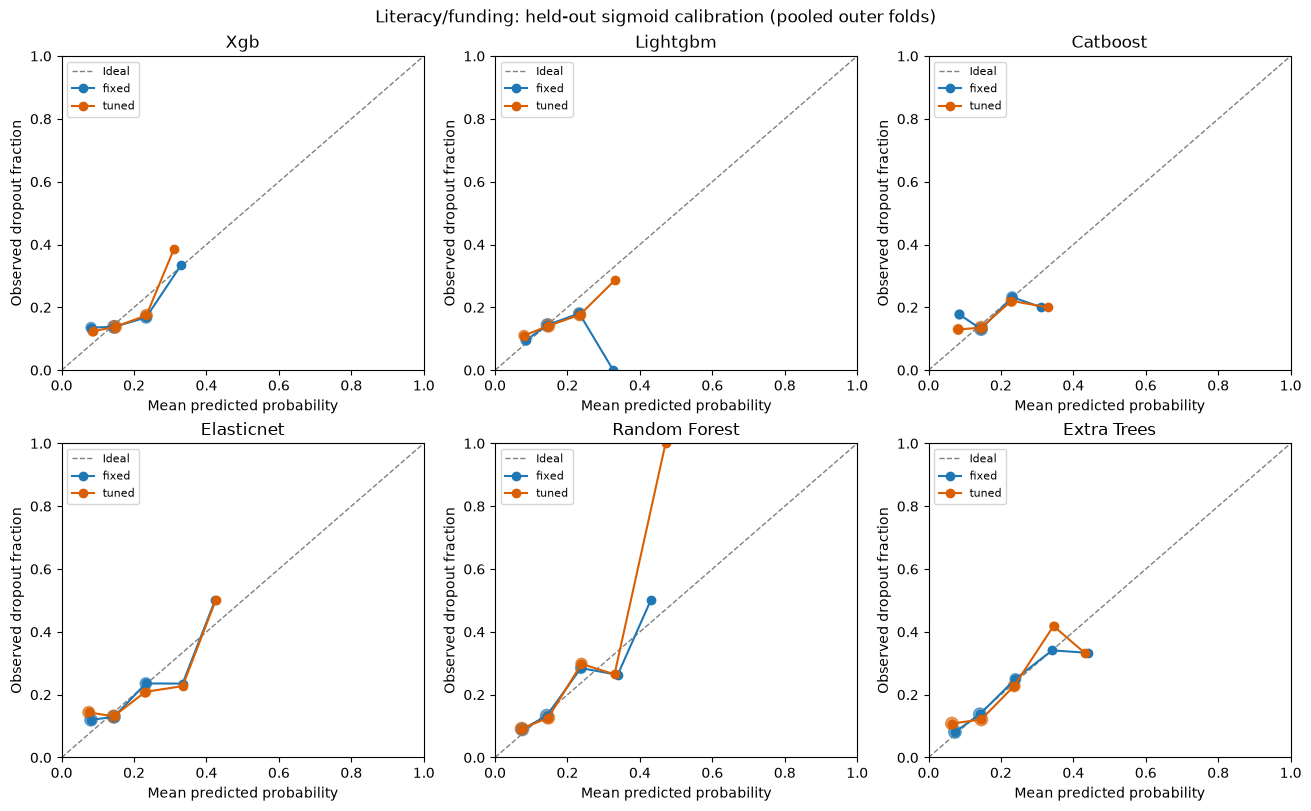

Larger markers indicate more observations; sparse bins are unstable. These curves do not fit the calibrator.


In [35]:
# Calibration curves use held-out sigmoid probabilities, never fitted to them.
import matplotlib.pyplot as plt
from src.model_calibration import reliability_bins
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
families = ['xgb','lightgbm','catboost','elasticnet','random_forest','extra_trees']
for ax, model in zip(axes.flat, families):
    ax.plot([0, 1], [0, 1], '--', color='grey', linewidth=1, label='Ideal')
    for setting, color in [('fixed', '#1f77b4'), ('tuned', '#d95f02')]:
        g = enriched_tuning_oof[enriched_tuning_oof.model.eq(model) & enriched_tuning_oof.setting.eq(setting)]
        bins, _ = reliability_bins(g.y_true, g.probability)
        bins = bins[bins.n.gt(0)]
        ax.plot(bins.mean_probability, bins.observed_rate, marker='o', color=color, label=setting)
        ax.scatter(bins.mean_probability, bins.observed_rate, s=15 + bins.n.clip(upper=200)/3,
                   color=color, alpha=.6)
    ax.set(title=model.replace('_',' ').title(), xlabel='Mean predicted probability',
           ylabel='Observed dropout fraction', xlim=(0,1), ylim=(0,1))
    ax.legend(fontsize=8)
fig.suptitle('Literacy/funding: held-out sigmoid calibration (pooled outer folds)')
fig.savefig(ROOT / 'figures/fig_enrichment_tuning_calibration.png', dpi=300, bbox_inches='tight')
plt.show()
print('Larger markers indicate more observations; sparse bins are unstable. These curves do not fit the calibrator.')


### Nested tuning findings: no reduction in false alarms without loss of recall

The six-family experiment completed all five outer folds, producing 1,440 candidate-search records, 60 outer evaluations and 15,684 held-out predictions. All 63 tests passed. Independent verification recomputed AP, Brier and confusion counts, checked AP-based candidate selection and inner recall constraints, and reproduced the earlier fixed literacy/funding model scores exactly (maximum absolute difference 0). All prior source files, datasets and result CSVs retained their checksums; previous notebook cells were unchanged. The new experiment and calibration diagnostic ran successfully in fresh kernels. No temporal predictions were generated.

**The intended improvement was not demonstrated.** Both procedures used the same inner 80% recall target, but achieved different held-out recalls. No tuned family reduced false alarms while maintaining or increasing its own fixed-model recall. These are exploratory results, not proof that improvement is impossible.

- Random Forest: fixed caught 157/188, missed 31, and generated 810 false alarms (967 flagged); tuned caught 158, missed 30, and generated 842 false alarms (1,000 flagged). One extra dropout caught cost 32 additional false alarms. Mean fold AP decreased from 0.2906 to 0.2876. At top 20%, both caught 76 out of 188 with 260 flagged.
- XGBoost, the professor's primary benchmark: mean AP improved from 0.2552 to 0.2673. At the training-selected recall policy, true positives increased from 163 to 170 and false alarms from 915 to 978. Top-20% true positives improved from 61 to 68. Better ranking here did not reduce the high-recall workload.
- Extra Trees: mean AP was essentially unchanged (0.2924 to 0.2920); top-20% true positives improved from 74 to 78. At the recall policy, true positives increased from 161 to 164 but false alarms rose from 801 to 887.
- ElasticNet was the only family with fewer false alarms at the recall policy (883 to 851), but caught fewer dropouts (159 to 151), increasing misses from 29 to 37. This is a trade-off, not an improvement at equal recall.
- CatBoost caught 165 to 167 dropouts while false alarms rose from 946 to 976. LightGBM caught 162 to 165 while false alarms rose from 894 to 908. Full metrics and calibration results are retained for every family.

**Family-group limitation remains:** for mother-only households, Random Forest recall at the inner-target policy fell from 15/23 to 14/23 and false alarms increased from 138 to 148. XGBoost caught 17/23 to 19/23 with false alarms increasing from 166 to 188. These subgroup counts are descriptive and do not establish causal effects or robust fairness guarantees. All region and co-residence groups are available in the subgroup CSV with sparse-group flags.

**Decision:** do not replace the current default with a tuned enriched model or claim that the false-alarm problem is fixed. The earlier F2 experiment used a different threshold objective (Random Forest 152 caught, 736 false alarms), so it is not the paired baseline for this 80%-target experiment. Likewise, the earlier tuned original-feature Random Forest still caught 79 at top 20%, exceeding this experiment's best top-20% count of 78. A modest AP increase does not by itself justify more alerts.

Further repeated searches on the same outer folds risk optimistic conclusions. The next decision should establish an affordable screening workload and freeze a candidate procedure before the professor-requested temporal evaluation; that evaluation can reveal drift, not improve a model by itself. Current evidence does not support promising both few misses and few false alarms from these survey predictors. Preserve the original KNN, redundant-feature removal, preprocessing and datasets. Existing attrition, geographic sensitivity, interpretability and final-report requirements remain applicable; this experiment does not complete all Phase 2 requirements.

New result files: `enrichment_tuning_search.csv`, `enrichment_tuning_metrics.csv`, `enrichment_tuning_oof_predictions.csv`, `enrichment_tuning_subgroup_metrics.csv`, `enrichment_tuning_calibration_curves.csv`, `enrichment_tuning_summary.csv`, and `figures/fig_enrichment_tuning_calibration.png`. The 80% training-recall policy is an experiment, not an approved intervention capacity or a deployment recommendation.


### Simple demographic targeting benchmark

This addresses the professor's request to compare the model against simple demographic targeting at the same intervention capacity. Prespecify an age/sex-only logistic regression: standardized age, a female indicator, fixed L2 C=1, no class weighting, interactions or hyperparameter search. Sex codes are the survey's recorded 1/2 categories. This is one transparent demographic comparator, not every possible demographic policy. No geography, parental co-residence, wealth, attendance or identifiers enter its estimator.

Use the same five district-grouped outer folds (seed 42), with household separation. Fit imputers/scaling only within each training partition. Report both uncalibrated and sigmoid results; sigmoid is prespecified for the primary comparison. Fit sigmoid on three-fold training OOF predictions (seed 1242 + outer fold), then refit the base estimator on the full outer training partition. No outer labels train calibration. Because settings are fixed, no additional tuning layer is needed. Report AP, Brier, calibration error and curves, plus top-20% precision/recall and confusion counts. At score ties, retain the established outcome-independent hashed-child-key rule; this matters because age/sex gives many tied scores.

Compare saved original-feature, tuned/sigmoid predictions for all six families with demographic sigmoid predictions after validating identities, labels, folds and selection rules. No complex model is retrained or selected here. Subgroup reporting retains each child's overall fold selection; do not give each subgroup a separate 20% quota. Random targeting is shown as its analytic expected count at the same per-fold capacity, not a fitted model or realized experiment. Training cohort only; later-wave predictions remain unscored. The repeatedly inspected folds make this descriptive evidence, not a confirmatory significance claim. Main pipeline, KNN and data are unchanged.


Random selection expected dropouts caught at the same capacity: 37.40


,model,average_precision,brier_score,ece_10_equal_width,recall_at_capacity,precision_at_capacity
0,catboost,0.2587,0.1214,0.0227,0.3511,0.2560
1,demographic_age_sex,0.1440,0.1232,0.0100,0.1977,0.1424
2,elasticnet,0.2520,0.1209,0.0365,0.4046,0.2945
3,extra_trees,0.3030,0.1180,0.0493,0.3998,0.2910
4,lightgbm,0.2603,0.1215,0.0225,0.3482,0.2527
5,random_forest,0.2942,0.1205,0.0522,0.4163,0.3024
6,xgb,0.2591,0.1215,0.0304,0.3628,0.2640


,model,selected_n,tp,fp,fn,precision,recall
0,catboost,260,67,193,121,0.2577,0.3564
16,demographic_age_sex,260,37,223,151,0.1423,0.1968
32,elasticnet,260,77,183,111,0.2962,0.4096
48,extra_trees,260,76,184,112,0.2923,0.4043
64,lightgbm,260,66,194,122,0.2538,0.3511
80,random_forest,260,79,181,109,0.3038,0.4202
96,xgb,260,69,191,119,0.2654,0.3670


,model,n,events,selected_n,tp,fp,fn,recall,sparse_group
13,catboost,262,23,14,3,11,20,0.130435,False
29,demographic_age_sex,262,23,52,6,46,17,0.260870,False
45,elasticnet,262,23,16,3,13,20,0.130435,False
61,extra_trees,262,23,4,2,2,21,0.086957,False
77,lightgbm,262,23,12,2,10,21,0.086957,False
93,random_forest,262,23,7,1,6,22,0.043478,False
109,xgb,262,23,13,3,10,20,0.130435,False


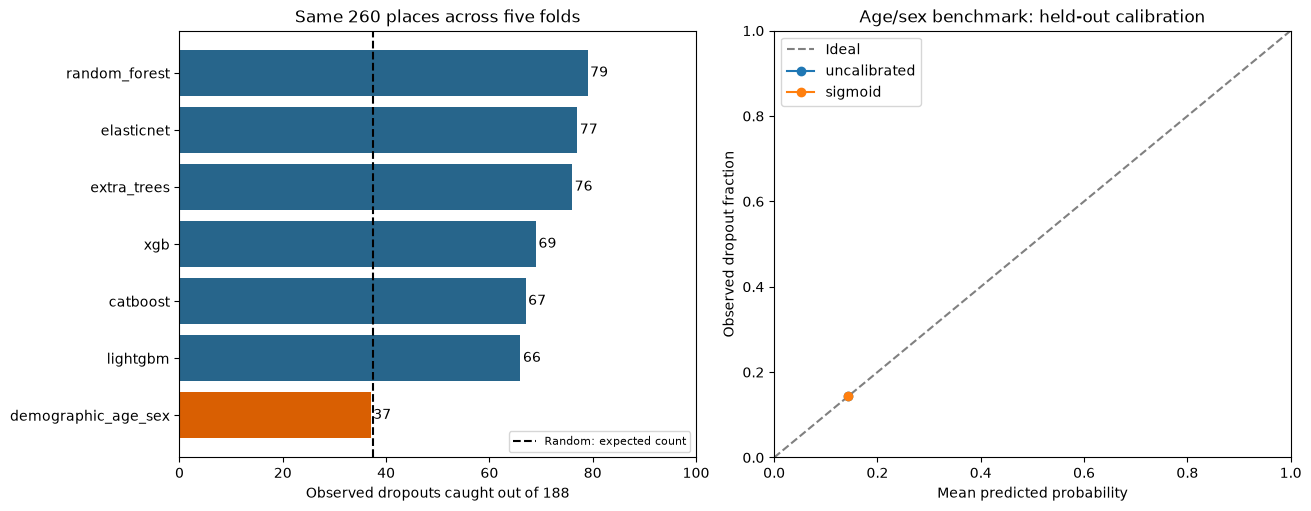

In [36]:
from src.demographic_baseline import evaluate_demographic, compare_demographic
from src.model_calibration import reliability_bins
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd
import matplotlib.pyplot as plt

demographic_train = pd.read_csv(ROOT / 'data/processed/train_w1_w2_raw.csv')
demographic_splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(
    demographic_train, demographic_train.dropout, demographic_train.district_id))
demographic_metrics, demographic_oof, demographic_curves = evaluate_demographic(demographic_train, demographic_splits)
prior_oof = pd.read_csv(OUT / 'calibration_oof_predictions.csv')
demographic_comparison = compare_demographic(demographic_train, demographic_oof, prior_oof)
prior_metrics = pd.read_csv(OUT / 'calibration_metrics.csv')
metric_columns = ['average_precision','brier_score','ece_10_equal_width','recall_at_capacity','precision_at_capacity']
demographic_summary = pd.concat([demographic_metrics[demographic_metrics.method.eq('sigmoid')],
    prior_metrics[prior_metrics.method.eq('sigmoid')]], ignore_index=True).groupby('model')[metric_columns].mean().reset_index()
for name, frame in [('metrics', demographic_metrics), ('oof_predictions', demographic_oof),
                    ('calibration_curves', demographic_curves), ('comparison', demographic_comparison),
                    ('summary', demographic_summary)]:
    frame.to_csv(OUT / f'demographic_{name}.csv', index=False)
demographic_overall = demographic_comparison[demographic_comparison.dimension.eq('overall')].copy()
random_expected_caught = sum(int(.2*len(b))*demographic_train.iloc[b].dropout.mean() for _,b in demographic_splits)
print(f'Random selection expected dropouts caught at the same capacity: {random_expected_caught:.2f}')
display(demographic_summary.round(4))
display(demographic_overall[['model','selected_n','tp','fp','fn','precision','recall']].round(4))
display(demographic_comparison[demographic_comparison.subgroup.eq('mother_only')][
    ['model','n','events','selected_n','tp','fp','fn','recall','sparse_group']])
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
counts=demographic_overall.sort_values('tp')
axes[0].barh(counts.model,counts.tp,color=['#d95f02' if x=='demographic_age_sex' else '#27658b' for x in counts.model])
axes[0].axvline(random_expected_caught,color='black',linestyle='--',label='Random: expected count')
for i,n in enumerate(counts.tp):axes[0].text(n+.5,i,str(n),va='center')
axes[0].set(xlabel='Observed dropouts caught out of 188',title='Same 260 places across five folds',xlim=(0,100))
axes[0].legend(fontsize=8)
axes[1].plot([0,1],[0,1],'--',color='grey',label='Ideal')
for method in ['uncalibrated','sigmoid']:
    g=demographic_oof[demographic_oof.method.eq(method)]
    bins,_=reliability_bins(g.y_true,g.probability);bins=bins[bins.n.gt(0)]
    axes[1].plot(bins.mean_probability,bins.observed_rate,marker='o',label=method)
axes[1].set(xlabel='Mean predicted probability',ylabel='Observed dropout fraction',
            title='Age/sex benchmark: held-out calibration',xlim=(0,1),ylim=(0,1))
axes[1].legend()
fig.savefig(ROOT / 'figures/fig_demographic_benchmark.png',dpi=300,bbox_inches='tight')
plt.show()


### Demographic benchmark findings and limits

At the identical total capacity of 260 children across the five folds, the prespecified sigmoid age/sex benchmark caught 37/188 dropouts (19.7% recall, 14.2% precision), with 223 false alarms and 151 misses. Random targeting would catch approximately 37 dropouts in expectation at these per-fold capacities. The uncalibrated age/sex model caught 41, with 219 false alarms and 147 misses; report this alongside the calibrated result rather than choosing whichever makes other models look better.

All six original-feature tuned/sigmoid models outperformed both demographic versions on these folds: Random Forest caught 79, ElasticNet 77, Extra Trees 76, XGBoost 69, CatBoost 67 and LightGBM 66, each with 260 selected. Random Forest therefore caught 42 more dropouts and produced 42 fewer false alarms than the calibrated demographic benchmark. This supports incremental value over this particular simple comparator; it does not establish deployment readiness, causal effects, or superiority over every possible demographic targeting policy. Complex models received tuning whereas this intentionally simple comparator had fixed settings.

Mean fold AP was 0.1440 for demographic sigmoid versus 0.2942 for Random Forest, 0.3030 for Extra Trees and 0.2591 for XGBoost. Calibration slopes were negative in three demographic folds, reversing the age/sex ranking under a mapping fitted exclusively on inner OOF scores. This instability is reported, not corrected after examining outer results. The uncalibrated demographic AP is approximately 0.1600 and remains below all six complex models. The demographic probabilities are concentrated near prevalence; their low calibration error and nearly coincident calibration-curve points do not imply useful discrimination. The broad, equal-width bins conceal detail when scores have such a narrow range.

The family-group limitation remains important. Among 262 mother-only children with 23 dropouts, the calibrated demographic policy selected 52 and caught 6 (46 false alarms), whereas Random Forest selected 7 and caught 1 (6 false alarms). These are inherited overall selections, not equal subgroup capacities. Higher overall model performance does not mean better recall in every group or establish fairness.

Verification: all 65 unit tests passed; the new notebook section executed in a fresh kernel; independent checks reproduced AP, Brier and confusion counts for all ten evaluations and 2,614 held-out records. Comparison checks enforce the same identities, labels, folds, capacity and tie-breaking. Previous source files, datasets, result CSVs and notebook cells remained unchanged. No temporal scoring, default-model replacement, commits or pushes occurred.

This completes the internal simple-demographic comparison requested by the professor. The subsequent sections document the frozen temporal comparison, global/local explanations, and logistic score effects. The final decision log and execution check record the completed integrated run.


### Model explanations: held-out XGBoost SHAP and logistic odds ratios

Address the professor's global/local SHAP and interpretable logistic-baseline recommendations. Explain the original-feature XGBoost benchmark and ElasticNet/L1 logistic model; this does not select a final deployed model. For each original outer fold, refit preprocessing and the saved hyperparameters previously selected using only that fold's training data. Require reproduction of the saved sigmoid-calibrated held-out predictions before accepting any explanation. The sigmoid parameters are reused, not refitted to held-out outcomes. No temporal cohort is used.

XGBoost's native exact TreeSHAP (`pred_contribs=True`, `approx_contribs=False`) explains its raw binary log-odds margin, using its training tree-path reference distribution. Contributions plus the bias must reconstruct each held-out raw margin. These are not probability percentage points. Report calibrated probability separately. Sum signed one-hot contributions back to their source variable before computing mean absolute grouped contribution across held-out children; this grouping is an aggregation of encoded-feature SHAP, not a fresh group-level Shapley game. Correlated variables can share attribution; preprocessing and imputation affect the values being explained. Global magnitudes do not establish direction or causation.

Local examples: select the smallest pseudonymous child-key hash within each of TP, FP, FN and TN, using existing top-20% predictions. These deliberately chosen diagnostic examples are not representative estimates. Labels select illustrations only, never model fits. Export no raw household/member IDs or names. Plot eight largest absolute source contributions plus an 'other features' sum to retain additivity.

For logistic regression, exponentiate penalized, class-weighted coefficients. These describe the fitted uncalibrated model-score odds, not causal effects, population odds ratios, or calibrated risk ratios. Numeric contrasts are one training-fold SD after the documented transformations (log/cap/rank where applicable); binary contrasts and fold-specific category references are explicitly exported. Zero penalized coefficients imply model OR=1, not evidence of no real association. Report all five fits, and descriptive median/min/max only within matching feature/contrast definitions. Fold ranges are not confidence intervals and fits overlap. Different fold scaling means standardized numeric contrasts need not equal the same raw-unit change.

References: [XGBoost native contributions](https://xgboost.readthedocs.io/en/release_2.0.0/python/python_api.html), [TreeSHAP output scales](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html). Existing model performance, data and thresholds remain unchanged; explanations do not improve predictions or prove future generalization.


Explanation fold 1/5: reproduced XGBoost and logistic predictions


Explanation fold 2/5: reproduced XGBoost and logistic predictions


Explanation fold 3/5: reproduced XGBoost and logistic predictions


Explanation fold 4/5: reproduced XGBoost and logistic predictions


Explanation fold 5/5: reproduced XGBoost and logistic predictions


,model,fold,training_n,validation_n,parameters,prediction_max_error,shared_districts,shared_households,shap_additivity_max_error
0,xgb,1,1042,265,"{""max_depth"": 2, ""min_child_weight"": 1}",2.637050e-09,0,0,0.000001
1,elasticnet,1,1042,265,"{""C"": 0.1, ""l1_ratio"": 1.0}",1.110223e-16,0,0,NaN
2,xgb,2,1055,252,"{""max_depth"": 2, ""min_child_weight"": 1}",4.280582e-09,0,0,0.000001
3,elasticnet,2,1055,252,"{""C"": 0.1, ""l1_ratio"": 0.5}",8.326673e-17,0,0,NaN
4,xgb,3,1037,270,"{""max_depth"": 2, ""min_child_weight"": 1}",5.706809e-09,0,0,0.000003
5,elasticnet,3,1037,270,"{""C"": 1.0, ""l1_ratio"": 1.0}",1.110223e-16,0,0,NaN
6,xgb,4,1050,257,"{""max_depth"": 2, ""min_child_weight"": 1}",8.244170e-09,0,0,0.000003
7,elasticnet,4,1050,257,"{""C"": 1.0, ""l1_ratio"": 1.0}",1.665335e-16,0,0,NaN
8,xgb,5,1044,263,"{""max_depth"": 2, ""min_child_weight"": 1}",1.649258e-09,0,0,0.000002
9,elasticnet,5,1044,263,"{""C"": 0.1, ""l1_ratio"": 1.0}",1.249001e-16,0,0,NaN


,feature,mean_abs_shap,mean_signed_shap,n
24,regioncode,0.4794,-0.2045,1307
4,durables_value,0.2682,-0.1090,1307
27,school_spend,0.2400,-0.1276,1307
6,english_score,0.1526,-0.0461,1307
31,teacher_absent_days_missing,0.1453,-0.0221,1307
15,math_score,0.1416,-0.0369,1307
32,travel_minutes,0.1313,-0.0306,1307
14,hh_size,0.1300,-0.0423,1307
0,age,0.1286,-0.0283,1307
23,over_age,0.0924,-0.0305,1307


,feature,contrast,folds_present,median_or,min_or,max_or,nonzero_folds
0,age,+1 training-fold SD of imputed value,5,1.0969,1.0000,1.3323,3
1,asset_count,+1 training-fold SD of imputed value,5,0.9054,0.8762,0.9528,5
2,attend_hours,+1 training-fold SD of imputed value,5,1.0000,0.9398,1.1295,4
3,attend_hours_missing,missing versus observed,5,1.0519,1.0000,1.6029,3
4,durables_value,+1 training-fold SD of training-reference rank,5,1.2410,1.1390,1.3768,5
5,electricity,yes versus no,5,0.8911,0.7186,1.0000,4
6,english_score,+1 training-fold SD of imputed value,5,0.7361,0.7253,0.8660,5
7,english_status_not_tested,english_status: not_tested versus reference blank_sheet,5,1.0000,0.5428,1.0000,2
8,english_status_scored,english_status: scored versus reference blank_sheet,5,1.0000,0.9405,1.0645,2
9,father_alive,alive versus deceased,5,1.1241,1.0000,1.1697,4


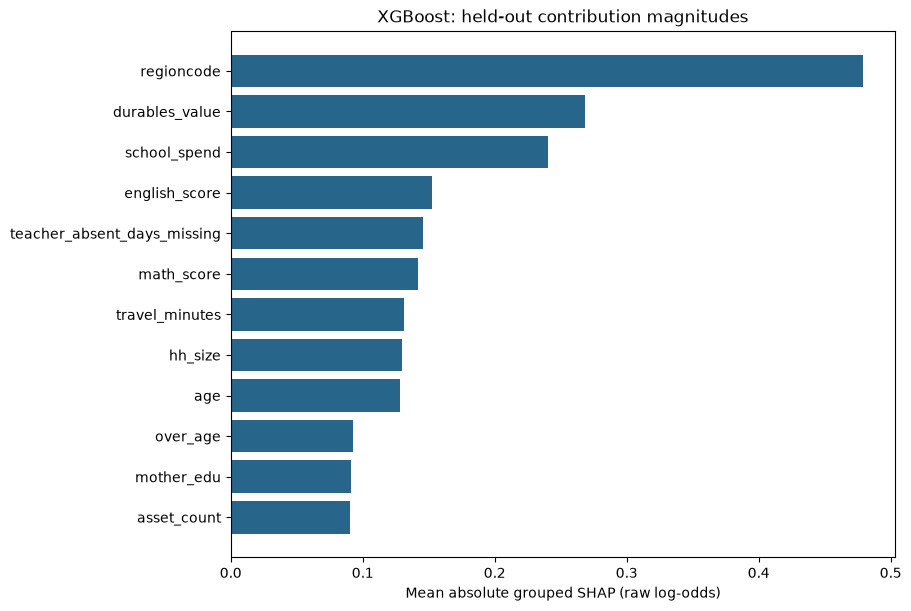

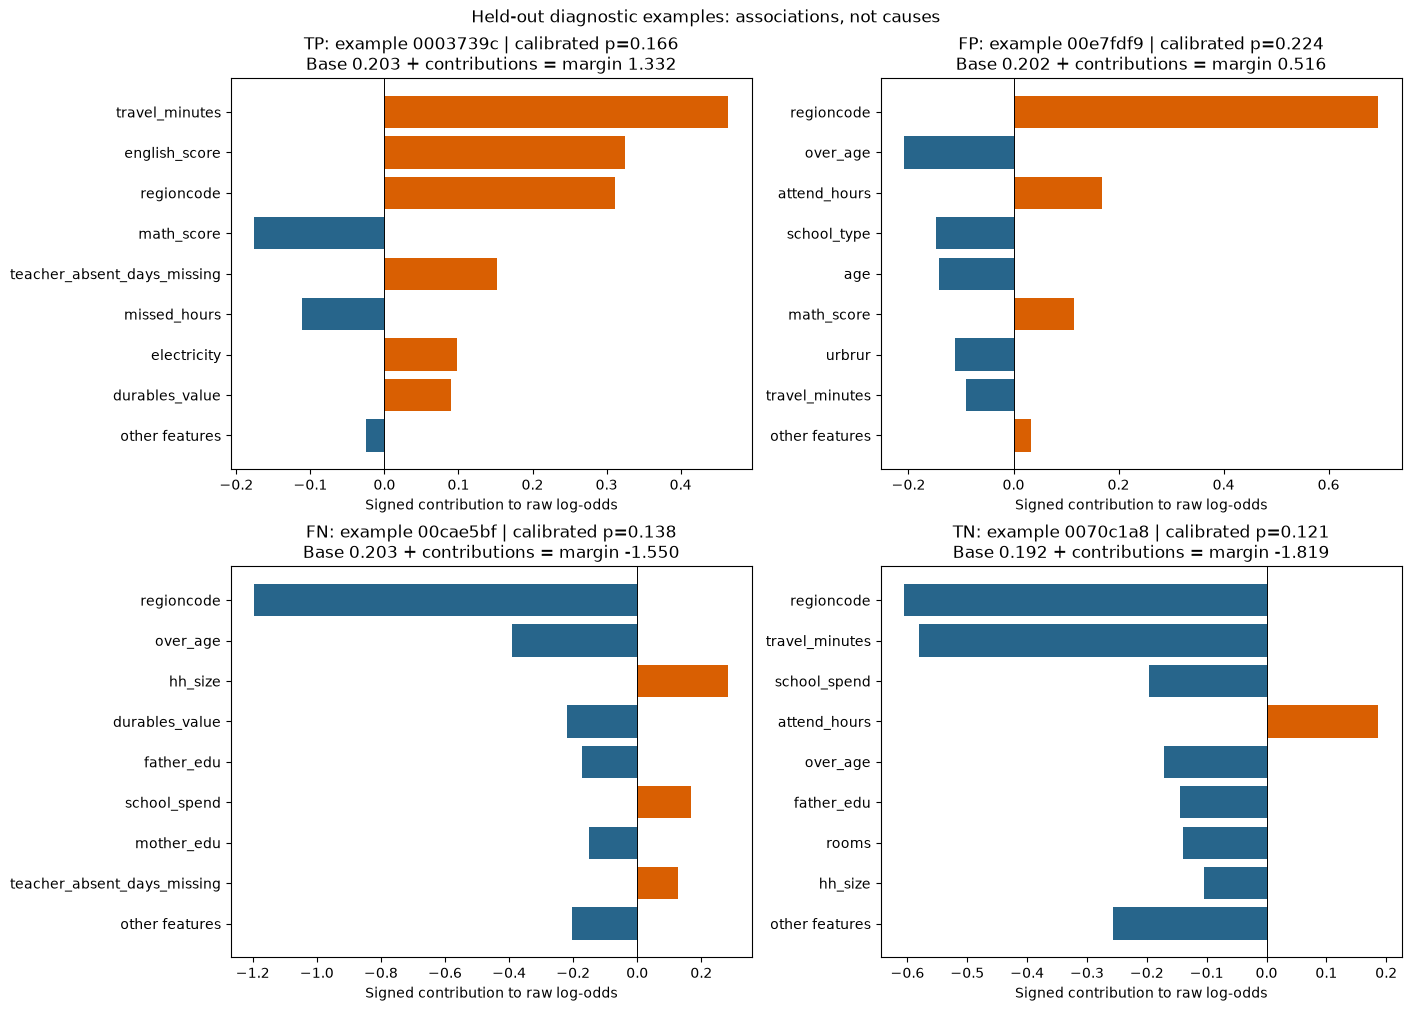

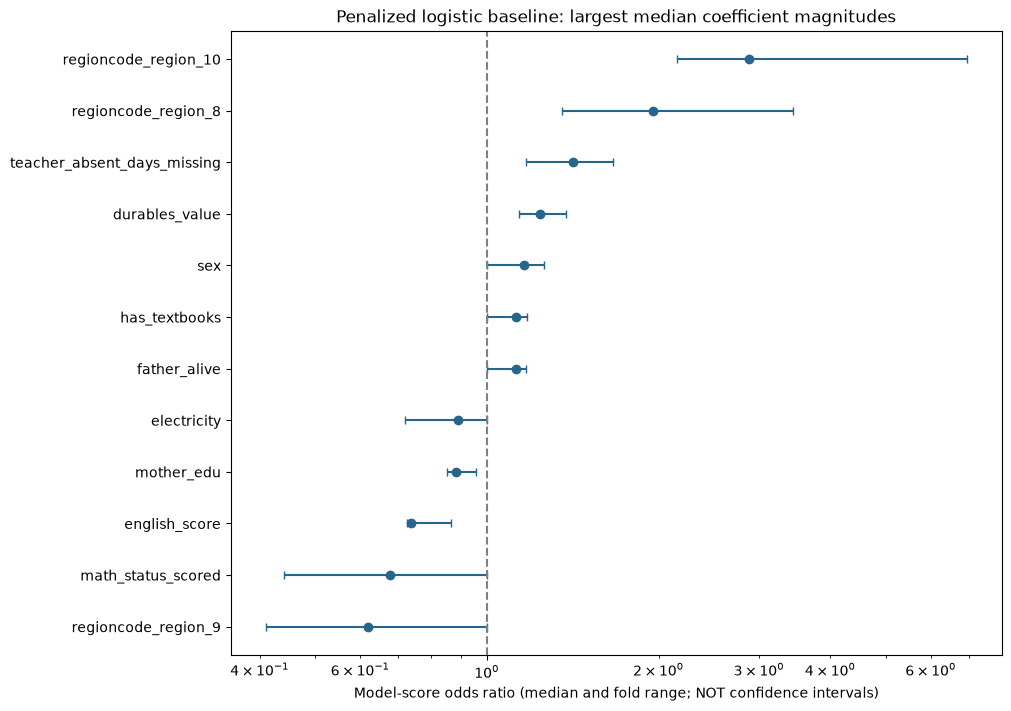

See the coefficient CSV for transformed units and category references. No causal claims or statistical confidence intervals.


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from src.model_interpretation import interpret_models

interpretation_train = pd.read_csv(ROOT / 'data/processed/train_w1_w2_raw.csv')
interpretation_splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(
    interpretation_train, interpretation_train.dropout, interpretation_train.district_id))
(interpretation_checks, shap_values_grouped, shap_children, shap_global,
 shap_local, logistic_odds, logistic_odds_summary) = interpret_models(
    interpretation_train, interpretation_splits, pd.read_csv(OUT / 'calibration_metrics.csv'),
    pd.read_csv(OUT / 'calibration_oof_predictions.csv'))
for name, frame in [('checks', interpretation_checks), ('shap_grouped', shap_values_grouped),
                    ('shap_children', shap_children), ('shap_global', shap_global), ('shap_local', shap_local),
                    ('logistic_odds', logistic_odds), ('logistic_odds_summary', logistic_odds_summary)]:
    frame.to_csv(OUT / f'interpretation_{name}.csv', index=False)
display(interpretation_checks)
display(shap_global.head(12).round(4))
display(logistic_odds_summary[logistic_odds_summary.folds_present.eq(5)].round(4))

fig,ax=plt.subplots(figsize=(9,6),constrained_layout=True)
g=shap_global.head(12).sort_values('mean_abs_shap')
ax.barh(g.feature,g.mean_abs_shap,color='#27658b')
ax.set(xlabel='Mean absolute grouped SHAP (raw log-odds)',title='XGBoost: held-out contribution magnitudes')
fig.savefig(ROOT / 'figures/fig_shap_global.png',dpi=300,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(2,2,figsize=(14,10),constrained_layout=True)
for ax,outcome in zip(axes.flat,['TP','FP','FN','TN']):
    g=shap_local[shap_local.outcome.eq(outcome)].copy()
    if g.empty:ax.set_visible(False);continue
    r=g.iloc[0];g=g.assign(magnitude=g.shap_log_odds.abs()).sort_values('magnitude',ascending=False)
    labels=g.feature.head(8).tolist()+['other features']
    values=g.shap_log_odds.head(8).tolist()+[g.shap_log_odds.iloc[8:].sum()]
    ax.barh(labels[::-1],values[::-1],color=['#d95f02' if x>0 else '#27658b' for x in values[::-1]])
    ax.axvline(0,color='black',linewidth=.7)
    ax.set(xlabel='Signed contribution to raw log-odds',
        title=f"{outcome}: example {r.child_key_sha256[:8]} | calibrated p={r.calibrated_probability:.3f}\nBase {r.base_margin:.3f} + contributions = margin {r.raw_margin:.3f}")
fig.suptitle('Held-out diagnostic examples: associations, not causes')
fig.savefig(ROOT / 'figures/fig_shap_local.png',dpi=300,bbox_inches='tight');plt.show()

g=logistic_odds_summary[logistic_odds_summary.folds_present.eq(5)].copy()
g['size']=np.abs(np.log(g.median_or));g=g.nlargest(12,'size').sort_values('median_or')
fig,ax=plt.subplots(figsize=(10,7),constrained_layout=True)
ax.errorbar(g.median_or,np.arange(len(g)),xerr=np.vstack([g.median_or-g.min_or,g.max_or-g.median_or]),
            fmt='o',color='#27658b',capsize=3)
ax.set_yticks(np.arange(len(g)),g.feature);ax.axvline(1,color='grey',linestyle='--');ax.set_xscale('log')
ax.set(xlabel='Model-score odds ratio (median and fold range; NOT confidence intervals)',
       title='Penalized logistic baseline: largest median coefficient magnitudes')
fig.savefig(ROOT / 'figures/fig_logistic_odds_ratios.png',dpi=300,bbox_inches='tight');plt.show()
print('See the coefficient CSV for transformed units and category references. No causal claims or statistical confidence intervals.')


#### Explanation findings and limitations

All 1,307 training-cohort children receive an explanation from a model fitted without their outer validation fold. All ten refits (five XGBoost and five logistic) reproduce the saved sigmoid-calibrated predictions, with maximum probability difference below 0.00000001. Independent checks confirm district/household separation, child identities, SHAP reconstruction, global aggregation and exponentiated logistic coefficients. The project test suite passes all 69 tests. Previous source files, processed datasets and evaluation CSVs remain byte-for-byte unchanged.

The largest average absolute grouped XGBoost contributions are region (0.479 raw log-odds), household durable-asset value (0.268), school spending (0.240), English score (0.153), the teacher-absence missingness flag (0.145) and mathematics score (0.142). These magnitudes describe influence on fitted scores, not the direction or causal effect of a variable. Geographic influence and a prominent missingness flag reinforce the need to interpret the existing geography/missingness sensitivity analyses and to evaluate temporal and regional generalization. SHAP does not establish that either variable is an artifact.

The four local plots illustrate one true positive, false positive, false negative and true negative under the existing within-fold top-20% policy. They show how contributions combine with each fold's base margin. Calibrated probabilities and rank cutoffs differ between folds; these examples do not imply a universal probability threshold.

For the penalized logistic benchmark, the female-versus-male model-score odds ratio has median 1.164 (fold range 1.000–1.261), while over-age has median 1.087 (1.085–1.193) per one training-fold standard deviation after imputation. These are conditional fitted-score associations. Penalization produces some zero coefficients; class weighting, transformed units and calibration prevent interpreting these as population or causal odds ratios. Fold ranges are descriptive, not confidence intervals.

This step explains the XGBoost and logistic benchmarks; it does not change their predictive performance, select a final model, or resolve the subgroup recall gap. If another model is selected for the final system, explain that fitted model separately. Freeze the model and policy before evaluating later-wave predictions; previous exploratory comparisons and inspection of cohort outcomes must be disclosed. The synchronized final report and the integrated execution check now accompany this notebook.


### Frozen retrospective temporal-evaluation protocol (25 October 2026)

The next evaluation follows the professor's requested temporal comparison, calibrated probabilities, regional checks and capacity-based intervention metrics. The exact settings and source hashes are saved in `phase2_implementation/temporal_evaluation_protocol.json`. This is a protocol freeze before temporal prediction evaluation, not a claim that later-wave data have never been inspected: cohort summaries and outcomes were examined earlier, and training cross-validation has been explored repeatedly.

**Model choice.** Use the original feature pipeline and retain the mixed-distance grade KNN, redundant-feature removal, grouped validation and outlier treatment praised by the professor. Extra Trees is the selected candidate because it has the highest existing mean sigmoid-calibrated five-fold average precision (0.3030), ahead of Random Forest (0.2942). Random Forest has higher mean recall at 20% capacity (0.4163 versus 0.3998); this trade-off must remain visible. Selection follows the professor's primary AP criterion, not a claim of statistically established superiority. Report all six families, keep XGBoost as the primary benchmark and penalized logistic regression as the interpretable baseline. Selected-model CV performance is optimistic after selection; no final deployment choice is established.

**Training and calibration.** Use the existing four-candidate grids, grouped inner tuning and training-only nested OOF sigmoid calibration. Full-training tuning uses seed 142; calibration uses `calibration_training_scores(train, model, outer_fold=0)` and its existing nested seeds. Fit preprocessing independently inside every training partition. Freeze parameters, fitted preprocessing and calibration before scoring later children. Uncalibrated and isotonic results are declared sensitivity comparisons; do not switch methods after examining temporal outcomes.

**Cohorts and allocation.** Primary evaluation excludes every household/person overlapping training; secondary evaluation excludes overlapping people but permits shared households. Define eligibility from IDs, never labels. The full later-wave table is descriptive context. Within each eligible cohort, flag the highest-risk `floor(0.20*N)` children using the existing deterministic tie rule. Twenty percent is a benchmark capacity assumption, not a verified service budget. Also report the prespecified 10%, 30%, 40% and 50% capacity curves so the cost of higher recall is visible. Do not use temporal outcomes to choose a winning capacity. No fixed 0.5 threshold or near-total-population flagging policy is adopted.

**Reporting.** For every model/cohort, report AP, recall, precision, selected count, TP/FP/FN/TN, Brier score, ten-bin ECE, calibration curves, prevalence and random-selection lift. Include the same demographic comparator and internal-versus-temporal performance differences. Report region, sex, urban/rural and parental co-residence subgroups using the cohort-level allocation, without granting each subgroup its own top-20% quota. Define high-risk regions solely by training regional prevalence exceeding training overall prevalence; retain unseen/missing regions separately. Show all subgroup counts, label n<30 or events<5 as sparse and descriptive, and leave undefined metrics missing. Use descriptive district-cluster bootstrap intervals (1,000 replicates, seed 20261025) with fixed scores/allocations; disclose that these do not account for model-selection uncertainty.

**Interpretation and limits.** Preserve all results, including deterioration, subgroup gaps and false alarms. Do not retune or replace the selected candidate using temporal outcomes. Prior geography/missingness ablations provide sensitivity evidence but do not themselves establish temporal robustness. Attrition means predictions concern observable children; no causal or population-wide guarantee follows. At protocol freeze, Extra Trees explanations, report synchronization, and integrated execution were separate pending requirements. They are completed in the subsequent sections and final verification. No temporal predictions are produced by this protocol section.


### Retrospective temporal evaluation: frozen protocol execution

This section refits the frozen six-family comparison and demographic benchmark on the earlier cohort, using nested training-only calibration. It may take several minutes. It writes only the new `temporal_*.csv` results. The primary cohort contains new households; the secondary contains new people and may share households with training. Districts may overlap across periods, so this is not a new-district external test. Prior inspection and repeated development are disclosed in the protocol above.

Apply the fixed Wave 2 monetary deflation once before transforming later predictors. Temporal labels are removed before prediction and used only for reporting. The primary method remains sigmoid; raw/isotonic methods and additional capacities are sensitivity results, not new model-selection opportunities. All confidence intervals are descriptive district-cluster bootstraps of fixed predictions/allocations, not model-fitting or selection uncertainty. Sparse groups and few-cluster groups are flagged in the subgroup CSV.


Temporal training-only fit: xgb


Temporal training-only fit: lightgbm


Temporal training-only fit: catboost


Temporal training-only fit: elasticnet


Temporal training-only fit: random_forest


...

Temporal scoring complete: secondary, n=1175, events=115


,cohort,rows,households,dropouts,dropout %,shared people,shared households,shared districts,train % of effective train+test,test % of effective train+test
0,All temporal records (descriptive),1395,1091,145,10.394265,220,486,134,48.371577,51.628423
1,Primary: new households,731,605,76,10.396717,0,0,129,64.131501,35.868499
2,Secondary: new people,1175,975,115,9.787234,0,370,134,52.659146,47.340854


,cohort,model,n,events,average_precision,recall_at_capacity,precision_at_capacity,tp,fp,fn,tn,brier_score,ece_10_equal_width
6,primary,xgb,731,76,0.147101,0.276316,0.143836,21,125,55,530,0.094082,0.041356
21,primary,lightgbm,731,76,0.135024,0.289474,0.150685,22,124,54,531,0.093632,0.037395
36,primary,catboost,731,76,0.153805,0.289474,0.150685,22,124,54,531,0.093272,0.034480
51,primary,elasticnet,731,76,0.151368,0.276316,0.143836,21,125,55,530,0.093200,0.037329
66,primary,random_forest,731,76,0.150922,0.302632,0.157534,23,123,53,532,0.092792,0.027444
81,primary,extra_trees,731,76,0.133749,0.263158,0.136986,20,126,56,529,0.093834,0.019705
96,primary,demographic_age_sex,731,76,0.083091,0.131579,0.068493,10,136,66,519,0.095555,0.041209
106,secondary,xgb,1175,115,0.132498,0.295652,0.144681,34,201,81,859,0.089998,0.047204
121,secondary,lightgbm,1175,115,0.124784,0.286957,0.140426,33,202,82,858,0.089628,0.045086
136,secondary,catboost,1175,115,0.138745,0.252174,0.123404,29,206,86,854,0.089248,0.041616


,cohort,model,cv_mean_average_precision,average_precision,average_precision_temporal_minus_cv_mean
0,primary,xgb,0.259125,0.147101,-0.112025
1,primary,lightgbm,0.260298,0.135024,-0.125274
2,primary,catboost,0.258703,0.153805,-0.104898
3,primary,elasticnet,0.251973,0.151368,-0.100605
4,primary,random_forest,0.294207,0.150922,-0.143286
5,primary,extra_trees,0.303045,0.133749,-0.169295
6,primary,demographic_age_sex,0.144007,0.083091,-0.060916
7,secondary,xgb,0.259125,0.132498,-0.126628
8,secondary,lightgbm,0.260298,0.124784,-0.135514
9,secondary,catboost,0.258703,0.138745,-0.119959


CV entries are unweighted means over five validation folds, not pooled AP. Temporal AP is cohort-wide; differences also reflect prevalence and cohort composition.


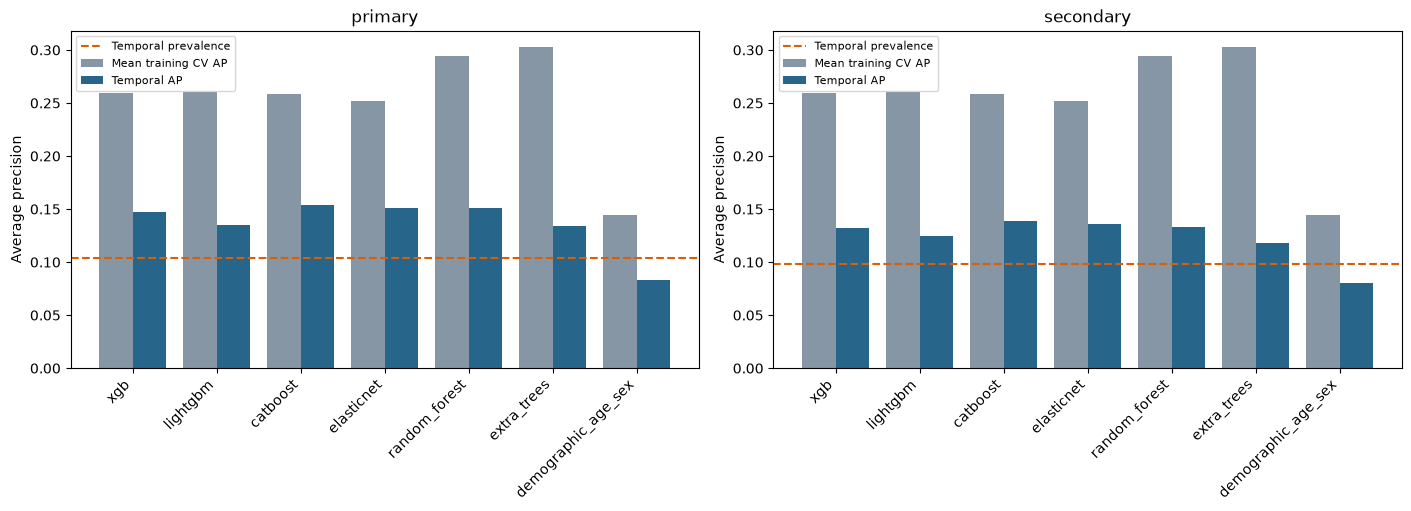

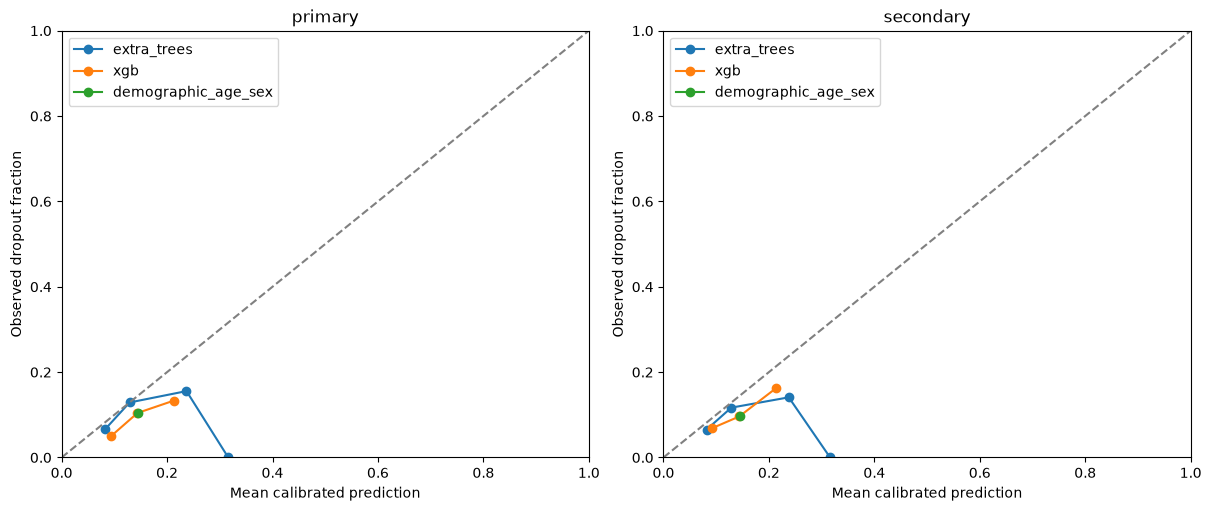

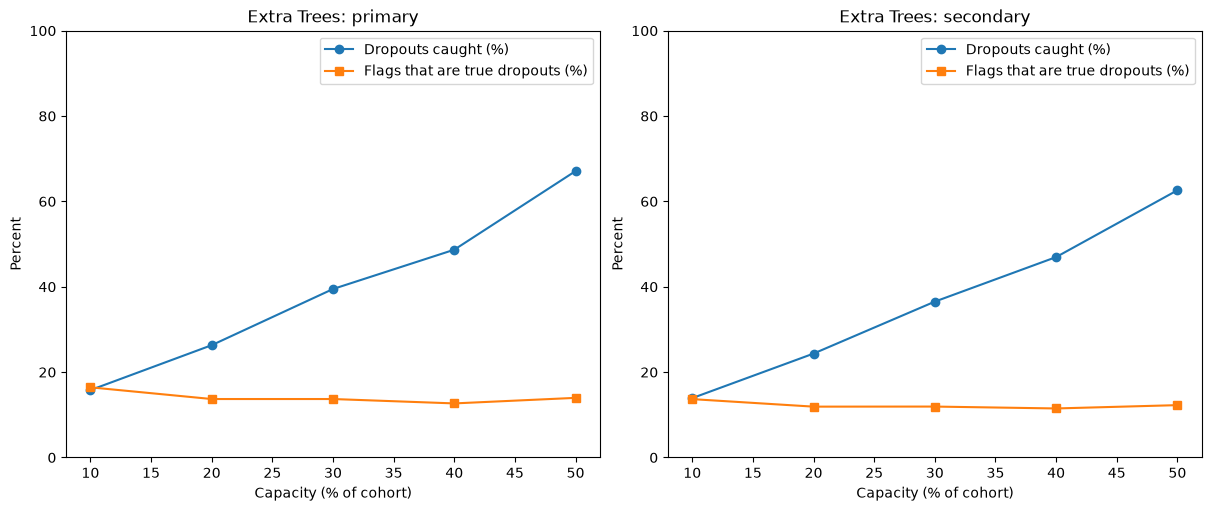

Frozen candidate remains Extra Trees. Higher observed temporal performance by another family does not authorize post-test reselection.


In [38]:
from src.temporal_evaluation import run_temporal_evaluation
temporal_outputs = run_temporal_evaluation(ROOT)
temporal_metrics = temporal_outputs['metrics']
temporal_main = temporal_metrics.query("method == 'sigmoid' and capacity == 0.2").copy()
display(temporal_outputs['cohorts'])
display(temporal_main[['cohort','model','n','events','average_precision','recall_at_capacity',
                       'precision_at_capacity','tp','fp','fn','tn','brier_score','ece_10_equal_width']])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
cv = pd.read_csv(OUT / 'calibration_metrics.csv')
demographic_cv = pd.read_csv(OUT / 'demographic_metrics.csv')
cv = pd.concat([cv, demographic_cv], ignore_index=True)
cv_mean = cv[cv.method.eq('sigmoid')].groupby('model')[
    ['average_precision','recall_at_capacity','precision_at_capacity','brier_score']].mean().add_prefix('cv_mean_').reset_index()
temporal_comparison = temporal_main.merge(cv_mean,on='model',validate='many_to_one')
for metric in ['average_precision','recall_at_capacity','precision_at_capacity','brier_score']:
    temporal_comparison[f'{metric}_temporal_minus_cv_mean'] = temporal_comparison[metric]-temporal_comparison[f'cv_mean_{metric}']
temporal_comparison.to_csv(OUT / 'temporal_cv_comparison.csv',index=False)
display(temporal_comparison[['cohort','model','cv_mean_average_precision','average_precision',
                            'average_precision_temporal_minus_cv_mean']])
print('CV entries are unweighted means over five validation folds, not pooled AP. Temporal AP is cohort-wide; differences also reflect prevalence and cohort composition.')

models=['xgb','lightgbm','catboost','elasticnet','random_forest','extra_trees','demographic_age_sex']
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax,cohort in zip(axes,['primary','secondary']):
    g=temporal_comparison[temporal_comparison.cohort.eq(cohort)].set_index('model').loc[models]
    x=np.arange(len(models))
    ax.bar(x-.2,g.cv_mean_average_precision,.4,label='Mean training CV AP',color='#8796a5')
    ax.bar(x+.2,g.average_precision,.4,label='Temporal AP',color='#27658b')
    ax.axhline(g.prevalence.iloc[0],color='#d95f02',linestyle='--',label='Temporal prevalence')
    ax.set_xticks(x,models,rotation=45,ha='right');ax.set(title=cohort,ylabel='Average precision');ax.legend(fontsize=8)
fig.savefig(ROOT/'figures/fig_temporal_comparison.png',dpi=300,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,cohort in zip(axes,['primary','secondary']):
    for model in ['extra_trees','xgb','demographic_age_sex']:
        g=temporal_outputs['calibration_curves'].query("method == 'sigmoid'")
        g=g[g.cohort.eq(cohort)&g.model.eq(model)&g.n.gt(0)]
        ax.plot(g.mean_probability,g.observed_rate,'o-',label=model)
    ax.plot([0,1],[0,1],'--',color='grey');ax.set(title=cohort,xlabel='Mean calibrated prediction',ylabel='Observed dropout fraction',xlim=(0,1),ylim=(0,1));ax.legend()
fig.savefig(ROOT/'figures/fig_temporal_calibration.png',dpi=300,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,cohort in zip(axes,['primary','secondary']):
    g=temporal_metrics.query("model == 'extra_trees' and method == 'sigmoid'")
    g=g[g.cohort.eq(cohort)].sort_values('capacity')
    ax.plot(g.capacity*100,g.recall_at_capacity*100,'o-',label='Dropouts caught (%)')
    ax.plot(g.capacity*100,g.precision_at_capacity*100,'s-',label='Flags that are true dropouts (%)')
    ax.set(title=f'Extra Trees: {cohort}',xlabel='Capacity (% of cohort)',ylabel='Percent',ylim=(0,100));ax.legend()
fig.savefig(ROOT/'figures/fig_temporal_capacity.png',dpi=300,bbox_inches='tight');plt.show()
print('Frozen candidate remains Extra Trees. Higher observed temporal performance by another family does not authorize post-test reselection.')


#### Temporal findings: substantial performance decline, not a deployment-ready result

The complete new section ran in a fresh kernel. Independent validation checked all 200 model/method/capacity/cohort metric rows, 38,120 exported prediction rows and 294 subgroup rows; these include repeated reports of the same children across models, methods and overlapping cohorts, not 38,120 distinct children. The two independent training-fit runs reproduce probabilities within numerical tolerance. All 75 project tests pass, including a batched-versus-loop bootstrap check. Prior source files, processed data and pre-existing result CSVs are unchanged. This validates the implementation of this step, not the predictive adequacy of the system. A full integrated-notebook rerun remains pending.

**Primary cohort: 731 children, 76 dropouts.** At 20% capacity, the frozen Extra Trees candidate flags 146 children: 20 true positives, 126 false positives, 56 false negatives and 529 true negatives. Recall is 26.3%, precision 13.7% and AP 0.1337, versus mean training CV AP 0.3030. Its descriptive district-bootstrap AP interval is 0.1033–0.1825 and recall interval 12.5%–41.9%. Random allocation of 146 places would capture about 15.2 dropouts in expectation; the observed 20 does not establish a reliable superiority claim. At 50% capacity, the same candidate catches 51/76 (67.1%) but makes 314 false alarms and still misses 25. The target of catching most cases with few false alarms is not met.

**Secondary cohort: 1,175 new people, shared households permitted.** Extra Trees flags 235: 28 true positives, 207 false positives, 87 false negatives and 853 true negatives. Recall is 24.3%, precision 11.9% and AP 0.1179. These overlapping cohorts are not independent replications. All six families show lower temporal AP than their internal mean CV AP. CatBoost has the highest observed primary temporal AP (0.1538), while Random Forest catches the most primary dropouts at 20% capacity (23/76). Neither result changes the frozen selection; switching after inspecting the test would invalidate an untouched-test claim.

**Regional allocation and family gaps.** Regions 8 and 10 exceed the training overall dropout rate and are the frozen high-risk stratum. In the primary cohort, this stratum contains 145 children and 17 dropouts and receives 128/146 flags; all 17 dropouts are caught, with 111 false alarms. The other regions contain 586 children and 59 dropouts, receive only 18 flags, and have just 3 dropouts caught (5.1% recall). This shows a severe concentration of the cohort-wide allocation; it is consistent with poor transfer of historical geographic risk, but does not isolate geography as the cause or justify causal claims. Region-specific figures are in the subgroup CSV, with sparse samples marked. Mother-only households have 3/20 dropouts caught (15.0%), compared with 17/48 (35.4%) in both-parent households. These are descriptive gaps under the same allocation, not equal-capacity subgroup experiments.

**Calibration and prevalence.** Extra Trees' mean primary prediction is 12.37%, versus 10.40% observed dropout; secondary values are 12.42% versus 9.79%. Primary Brier score is 0.0938 and ten-bin ECE 0.0197. A lower temporal Brier score than CV does not by itself prove better calibration, because prevalence changed. The calibration curve's highest occupied bin contains only six primary children (seven secondary) and no observed events; its zero point is highly unstable. Interpret curves together with exported bin counts. The demographic sigmoid slope is negative, as in some earlier folds; raw and calibrated comparator results are both retained rather than selecting the better temporal variant.

**Limits and follow-up.** This is an exploratory retrospective evaluation after prior cohort inspection and repeated CV development, not an untouched prospective validation. Districts overlap across periods, and attrition restricts inference to observable children. The decline can reflect temporal shifts, cohort composition, prevalence changes, selection optimism and other factors; it is not evidence by itself of a coding error or proof of a single data defect. Do not tune to these temporal labels. The subsequent Extra Trees explanations and feature/calibration-drift diagnostics preserve this evaluation as the recorded result. Any later model redesign requires fresh evaluation data or clearly labeled exploratory evidence. The final report and decision log now incorporate this result, and the integrated rerun reaches the final verification cell.


### Training-only comparison of source-audited cleaning alternatives

Compare original, corrected, corrected+routed teacher absence, and corrected+routed+attendance sensitivity on identical five district-grouped folds (seed 42). Six families use the existing fixed baseline settings. Each outer training partition obtains three-fold grouped OOF scores for sigmoid calibration (seed 2242+fold), with preprocessing and grade-KNN refitted inside every training partition. There is no hyperparameter selection. Top 20% capacity and deterministic tie rules are identical. These results are comparable within this experiment, not directly to the previously tuned 0.303 AP result. Existing CV has been repeatedly explored, so any gain is exploratory. No later-wave outcomes or predictions enter this comparison; the recorded temporal failure remains unchanged.


Cleaning comparison: original, fold 1/5


Cleaning comparison: original, fold 2/5


Cleaning comparison: original, fold 3/5


Cleaning comparison: original, fold 4/5


Cleaning comparison: original, fold 5/5


...

Cleaning comparison: corrected_routed_attendance, fold 2/5


Cleaning comparison: corrected_routed_attendance, fold 3/5


Cleaning comparison: corrected_routed_attendance, fold 4/5


Cleaning comparison: corrected_routed_attendance, fold 5/5


,variant,model,mean_ap,mean_brier,tp,fp,fn,selected_n,recall,precision
0,corrected,catboost,0.246966,0.121298,58,202,130,260,0.308511,0.223077
1,corrected,elasticnet,0.266472,0.120167,73,187,115,260,0.388298,0.280769
2,corrected,extra_trees,0.284572,0.118085,79,181,109,260,0.420213,0.303846
3,corrected,lightgbm,0.249819,0.120428,71,189,117,260,0.377660,0.273077
4,corrected,random_forest,0.298388,0.118213,78,182,110,260,0.414894,0.300000
5,corrected,xgb,0.253343,0.120876,68,192,120,260,0.361702,0.261538
6,corrected_routed,catboost,0.250910,0.121526,64,196,124,260,0.340426,0.246154
7,corrected_routed,elasticnet,0.267377,0.120034,72,188,116,260,0.382979,0.276923
8,corrected_routed,extra_trees,0.280066,0.118109,78,182,110,260,0.414894,0.300000
9,corrected_routed,lightgbm,0.243719,0.120541,70,190,118,260,0.372340,0.269231


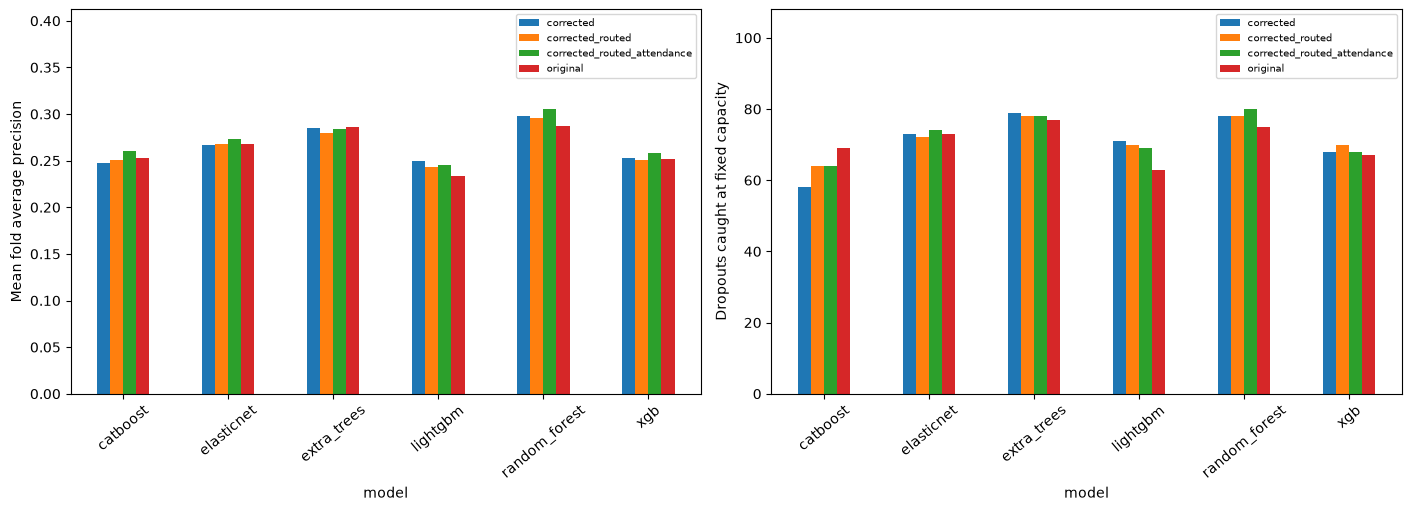

Each model/variant flags 260 children across five held-out folds. Results are exploratory; no temporal reevaluation or automatic model replacement.


In [39]:
from src.data_cleaning import evaluate_cleaning
recleaning_metrics, recleaning_oof, recleaning_summary = evaluate_cleaning(ROOT)
display(recleaning_summary)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax,metric,label in zip(axes,['mean_ap','tp'],['Mean fold average precision','Dropouts caught at fixed capacity']):
    recleaning_summary.pivot(index='model',columns='variant',values=metric).plot.bar(ax=ax)
    ax.set_ylabel(label);ax.tick_params(axis='x',rotation=40)
    ax.margins(y=.35)
    ax.legend(fontsize=7)
fig.savefig(ROOT/'figures/fig_recleaning_comparison.png',dpi=300,bbox_inches='tight')
plt.show()
print('Each model/variant flags 260 children across five held-out folds. Results are exploratory; no temporal reevaluation or automatic model replacement.')


#### Cleaning comparison findings and interpretation

The two new notebook sections executed in fresh kernels, and all 80 project tests passed. Original data, earlier source modules and all earlier result files (including the frozen temporal evaluation) remain unchanged. The six alternative tables retain the same 1,307/1,395 children, 39-column schema, IDs and target values, with `dropout` last. The complete notebooks have not yet been rerun from their first cells in this step.

The core corrected version recognizes 50 additional explicit Wave 1 vacation codes, marks one conflicting English-test score uncertain, and sets incomplete household durable-value totals missing for 93 training and 249 later-wave children (eight further later totals were already missing). Median filling of those totals remains training-fold only. This is a conservative treatment of incomplete totals, not a recovery of their unknown true amounts. No higher duplicate test score was selected to improve results.

At the same 260 total flags across five held-out folds, original versus core corrected results are:

- catboost: mean AP 0.2533 → 0.2470; true positives 69 → 58; false alarms 191 → 202.
- elasticnet: mean AP 0.2684 → 0.2665; true positives 73 → 73; false alarms 187 → 187.
- extra_trees: mean AP 0.2856 → 0.2846; true positives 77 → 79; false alarms 183 → 181.
- lightgbm: mean AP 0.2334 → 0.2498; true positives 63 → 71; false alarms 197 → 189.
- random_forest: mean AP 0.2869 → 0.2984; true positives 75 → 78; false alarms 185 → 182.
- xgb: mean AP 0.2519 → 0.2533; true positives 67 → 68; false alarms 193 → 192.

All these values come from the new fixed-hyperparameter, training-only sigmoid-calibrated comparison. They must not be compared directly with the earlier nested-tuned AP 0.303 result. The same splits, model settings, calibration scheme and capacity are used across cleaning variants; tree preprocessing is reused only within an identical fit/validation partition. No later-wave outcomes or predictions are used. A small numerical improvement is exploratory and does not establish a reliable or temporal gain, because these training folds have been repeatedly inspected.

The routed-teacher variant changes 82 training teacher-absence values and recovers 175 later-wave values. Its maximum observed subject-teacher absence is an explicit proxy, not total lost instruction days. The final sensitivity disables blank-missed-hours→zero inside training fits; for the later-wave table it also retains 151 recorded zero-hour observations and marks vacation unknown for all later children rather than inferring it from zero hours. Training CV cannot validate the benefit of this later-wave holiday change. The alternative table must be used with its matching pipeline setting; passing it to the original pipeline would silently reintroduce the blank-to-zero assumption.

The four versions separate definite recording/representation issues from optional assumptions. Do not undo a documented vacation-code correction simply because a performance number decreases. Conversely, do not promote a proxy or imputation assumption merely because it scores better on these reused folds. The original 20/76 temporal true positives and 126 false alarms remain the recorded evaluation; no claim that re-cleaning solved temporal generalization is supported by this experiment. The following fitted Extra Trees explanations and temporal-drift diagnosis retain this cleaning comparison as separate exploratory evidence.


### Frozen Extra Trees explanations and temporal drift

Reconstruct the recorded Extra Trees model using the original training data and saved training-only settings. Apply the saved OOF sigmoid coefficients without refitting calibration; require reproduction of the recorded temporal probabilities and identities before interpreting them. The separate cleaning experiments do not replace this evaluation.

Exact TreeSHAP uses the fitted trees' training path counts as its reference. For this Extra Trees classifier, SHAP contributions plus the base value reconstruct the **uncalibrated positive-class probability**, verified numerically. They do not add to calibrated risk. Sum signed one-hot contributions within each source feature before taking global mean absolute contributions; this is a regrouping of encoded-feature SHAP, not a newly computed grouped Shapley game. Local examples use the smallest pseudonymous identity hash in each TP/FP/FN/TN category, not hand-picked explanations.

Drift diagnostics compare original raw variables, with later money converted to 2009 prices. Numeric KS statistics compare observed-value distributions; categorical total variation includes missingness; missing-rate differences are reported separately. These are descriptive effect sizes without iid significance tests. Cohort composition, survey routing, and changes in measurement can all contribute; drift and SHAP cannot establish causes of predictive failure. Region summaries compare observed prevalence, predicted risk, alert allocation, and geography contributions, with sparse cells marked. Existing temporal calibration curves remain the calibration reference. No model, features, threshold, or calibration is selected using these results.


,cohort,feature,mean_absolute_shap,mean_signed_shap
24,primary,regioncode,0.075886,-0.033147
31,primary,teacher_absent_days_missing,0.032032,-0.020102
19,primary,mother_edu,0.018046,-0.004435
28,primary,school_type,0.017617,-0.012378
9,primary,father_edu,0.017245,-0.003878
11,primary,father_in_hh,0.016586,-0.003945
5,primary,electricity,0.015628,-0.006602
16,primary,math_status,0.012175,-0.004611
33,primary,urbrur,0.010755,-0.003351
27,primary,school_spend,0.009893,-0.001762


,cohort,regioncode,training_n,temporal_n,training_prevalence,temporal_prevalence,training_share,temporal_share,mean_probability,selected_n,tp,fp,fn,mean_region_shap,sparse_group
0,primary,1,141,62,0.134752,0.161290,0.107881,0.084815,0.109982,2,0,2,10,-0.031223,False
1,primary,2,83,51,0.120482,0.058824,0.063504,0.069767,0.095820,0,0,0,3,-0.046897,True
2,primary,3,101,54,0.089109,0.092593,0.077276,0.073871,0.098710,1,0,1,5,-0.053169,False
3,primary,4,89,64,0.056180,0.062500,0.068095,0.087551,0.097120,4,0,4,4,-0.104218,True
4,primary,5,124,92,0.072581,0.130435,0.094874,0.125855,0.099358,2,1,1,11,-0.074160,False
5,primary,6,224,133,0.084821,0.097744,0.171385,0.181943,0.095698,3,0,3,13,-0.081122,False
6,primary,7,135,88,0.133333,0.068182,0.103290,0.120383,0.113960,5,2,3,4,-0.030432,False
7,primary,8,200,125,0.280000,0.128000,0.153022,0.170999,0.209920,109,16,93,0,0.101553,False
8,primary,9,138,42,0.072464,0.142857,0.105585,0.057456,0.093238,1,0,1,6,-0.134548,False
9,primary,10,72,20,0.458333,0.050000,0.055088,0.027360,0.254961,19,1,18,0,0.144244,True


{'model': 'extra_trees',
 'selection_changed': False,
 'calibration_refitted': False,
 'prediction_max_error': 1.6653345369377348e-16,
 'shap_additivity_max_error': 3.552713678800501e-15,
 'shap_scale': 'uncalibrated positive-class probability',
 'background': 'training tree path counts',
 'local_selection': 'smallest SHA256 identity per outcome and cohort',
 'interpretation': 'Retrospective associations, not causal effects; cohort composition and survey routing can explain distribution shifts.',
 'sha256': {'data\\processed\\train_w1_w2_raw.csv': 'e66f19dfa5c4556f34a540b1bda7c0c6751d436c889bf8e6dce791c828c8695e',
  'data\\processed\\test_w2_w3_raw.csv': '61b2db124be2e6a7f4c54f00057c6def4fca901b277c29a0dafdffd2ceb6fb02',
  'phase2_implementation\\temporal_fit_audit.csv': 'b95ec200ac170123eac199f16393f60030962f407cb70352b682d3429fef92e1',
  'phase2_implementation\\temporal_predictions.csv': '38da31906f36cb07d1441f14c76e1d778468059d04d54a78b6d64e0dc1017b02'}}

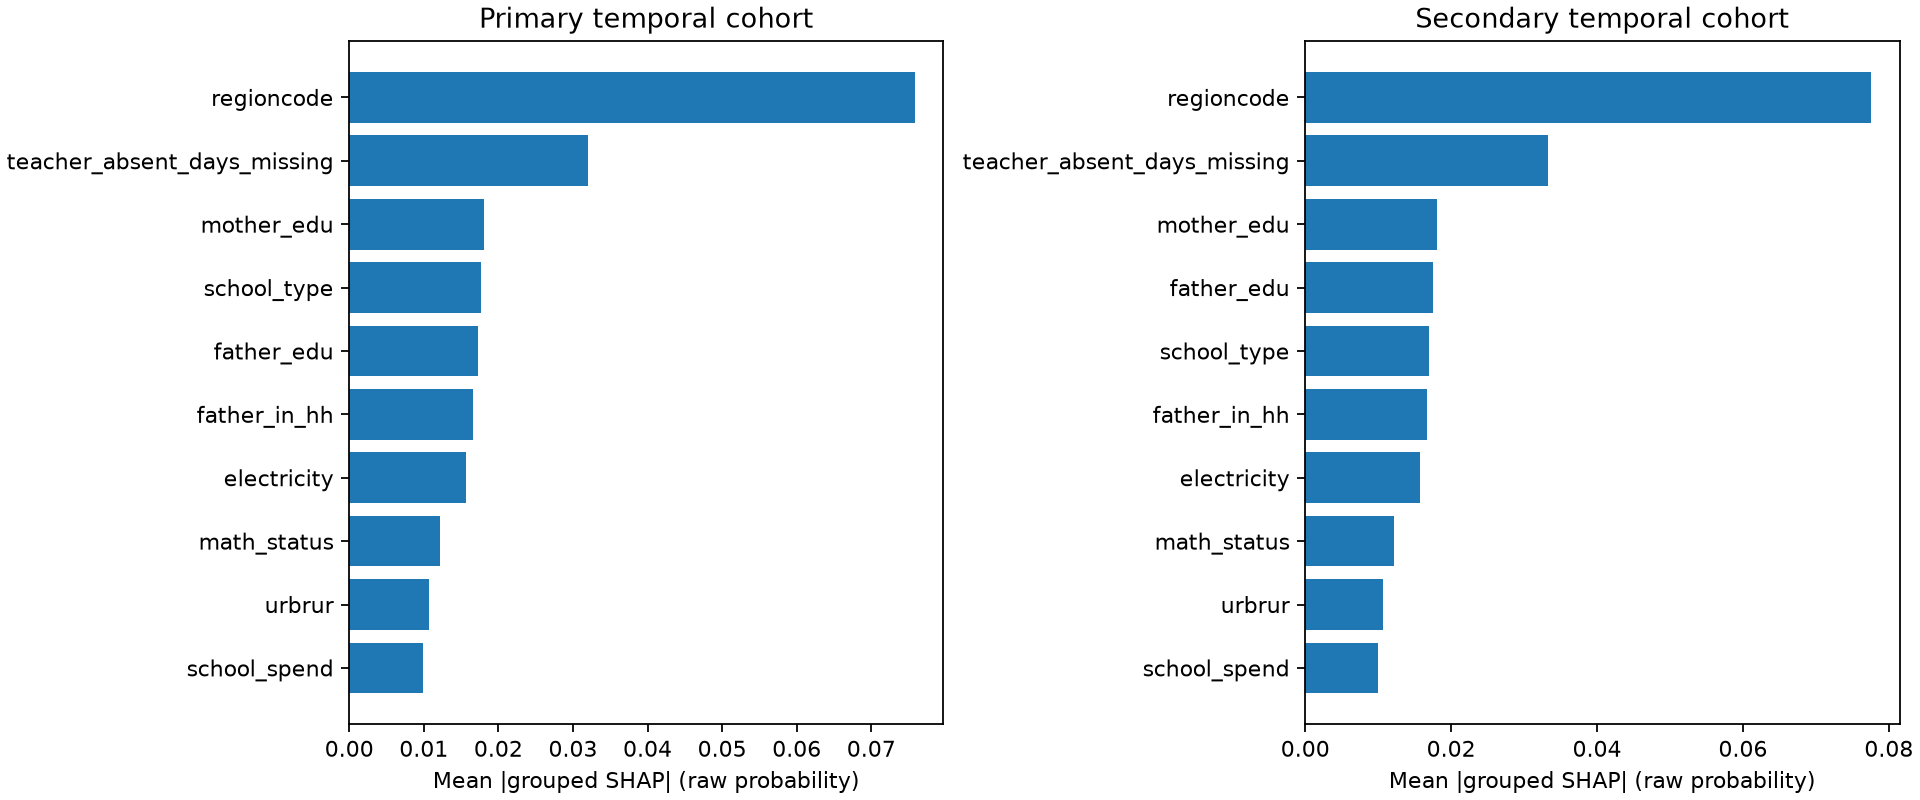

In [40]:
from src.temporal_diagnostics import run_temporal_diagnostics
temporal_diagnostics, temporal_diagnostic_checks = run_temporal_diagnostics(ROOT)
display(temporal_diagnostics['global_shap'].groupby('cohort').head(10))
display(temporal_diagnostics['region_drift'])
display(temporal_diagnostic_checks)
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/fig_temporal_extratrees_shap.png')))


#### What the frozen Extra Trees model reveals

The reconstructed fit reproduces the recorded calibrated predictions to within 1.7e-16; exact TreeSHAP reconstructs raw positive-class probabilities to within 3.6e-15. Global explanations cover all 731 primary and 1,175 secondary children, and local tables contain one deterministically selected TP, FP, FN, and TN per cohort. All 83 project tests pass and the new section executed in a fresh kernel; the integrated execution status is recorded in the final verification cell.

**Geography dominates this fitted model.** In the primary cohort, mean absolute grouped SHAP is 0.0759 for region, 0.0320 for teacher-absence missingness, and 0.0180 for maternal education. These numbers are contributions on the uncalibrated score scale, not calibrated risk differences or causal effects. One-hot regrouping and correlated predictors limit direct causal interpretation or comparisons with other SHAP background choices.

**Regional calibration and allocation are uneven.** Region 8 had 28.0% observed training dropout, versus 12.8% (16/125) in the primary later cohort, but mean calibrated predicted risk remains 21.0%. It receives 109 alerts: 16 true positives and 93 false alarms. Region 10 receives 19 alerts among only 20 children, with one event; its 25.5% mean predicted risk versus 5.0% observed rate is based on a sparse group and should not be generalized. Regions 8 and 10 together receive 128 of the 146 places, catching 17 events. The other regions contain 59 events but receive 18 places, catching just three. This is consistent with the professor's temporal-geography concern, not proof that region alone caused the gap. Earlier training-only geography ablations did not support simply removing all geography.

**The measurements also changed.** Raw missed-hours missingness falls from 77.8% to 13.5%, and teacher-absence missingness from 56.8% to 31.7%, between training and the primary later cohort. Among observed missed-hours entries, medians are 3 versus 0 and KS distance is 0.492. The KS comparison excludes missing entries and precedes the existing pipeline's blank-to-zero rule; it is not the model-input distribution after imputation. These shifts can reflect survey routing and cohort composition as well as actual behavior. They support retaining the separate source-audited cleaning investigation, but do not establish that cleaning alone will solve prediction.

Overall primary mean calibrated risk is 12.4% against 10.4% observed dropout. That modest average discrepancy hides regional overprediction and missed cases elsewhere; good average calibration does not imply good ranking or equitable allocation. The existing calibration curves and subgroup counts remain essential. The frozen primary result remains 20 true positives, 126 false alarms, and 56 missed dropouts at 20% capacity. Neither explanations nor this retrospective diagnosis improved that result or authorize a new model chosen on these test outcomes.

This directly addresses the professor's requests for final-model global/local explanations, temporal and regional drift, and calibration diagnostics, while preserving the earlier preprocessing and training-only model selection. The final Phase 2 report and decision log now incorporate this evidence; the complete notebook has executed in a fresh kernel. Future geographic recalibration or alternative policies require a separately specified evaluation and independent validation data.


### Final decision log and integrated execution check

The original preprocessing decisions remain recorded above. This final log adds professor-requested modelling diagnostics and distinguishes completed work, exploratory alternatives, and unresolved limitations.

In [41]:
# Final decision log is written only after all diagnostic sections succeed.
log = log[log['Step'].ne('Calibration, final test')].copy()
extra_decisions = [
['Model families', 'Professor extension: compare six families with XGBoost benchmark', 'XGBoost, LightGBM, CatBoost, ElasticNet/L1, Random Forest and Extra Trees; identical district folds', 'Completed; no post-test model replacement'],
['Nested tuning and calibration', 'Professor extension: training-only selection and OOF sigmoid/isotonic', 'Inner grouped searches; preprocessing refitted within fits; calibration uses training OOF scores', 'Completed; later outcomes excluded'],
['Frozen temporal evaluation', 'Professor extension: temporal and regional assessment', 'Extra Trees selected by training CV; primary 731 children/76 events; 20 TP, 126 FP, 56 FN at 20% capacity; secondary 1175/115', 'Completed retrospectively; weak transport performance'],
['Attrition', 'Professor extension: compare observed and unobserved outcomes', 'Baseline comparisons by follow-up and parent co-residence; unknown outcomes remain unknown', 'Completed descriptive audit; inverse-probability weighting not implemented'],
['Geography and missingness', 'Professor extension: ablate flags and geography', 'Training-only missing-flag, geography and region-only ablations; frozen temporal regional diagnosis', 'Completed; sensitivity is not causal evidence'],
['Subgroup performance', 'Professor extension: regional and household comparisons', 'Counts, false alarms, misses, calibration and district-bootstrap intervals; sparse cells flagged', 'Completed; allocation disparities remain'],
['Intervention policy', 'Professor extension: capacity and interpretable comparators', 'Top-20% policy; capacity sensitivity; demographic and random comparators; high-recall and F1/F2 alternatives', 'Completed; no policy meets all desired error goals'],
['Interpretability', 'Professor extension: global/local SHAP and logistic odds ratios', 'Held-out XGBoost SHAP and penalized logistic score odds ratios; frozen Extra Trees exact TreeSHAP', 'Completed; score associations, not causal effects'],
['Source-audited cleaning', 'Additional audit requested after temporal failure', 'Separate vacation-code, duplicate-score and asset-total corrections; teacher-routing/attendance sensitivities; six-family training comparison', 'Exploratory; original tables and frozen evaluation retained'],
['Feature enrichment', 'Explore baseline-time predictors within survey evidence', 'Separate literacy, funding and teacher-routing candidates with grouped training validation', 'Exploratory; no automatic adoption'],
['Temporal drift and calibration', 'Professor extension: diagnose cross-wave changes', 'Region and missingness dominate Extra Trees; region 8 prevalence 28.0% to 12.8%, mean predicted risk 21.0%', 'Completed; no later-wave recalibration'],
]
log = pd.concat([log, pd.DataFrame(extra_decisions, columns=log.columns)], ignore_index=True)
log.to_csv(OUT/'decision_log.csv', index=False)
display(log)
assert temporal_diagnostic_checks['prediction_max_error'] < 1e-7
assert temporal_diagnostic_checks['shap_additivity_max_error'] < 1e-7
print('Integrated Phase 2 execution reached the final cell successfully.')


,Step,Planned in Phase 1,Implemented in Phase 2,Status
0,Fix recording errors,"Fixed rules (codes, impossible values)",Applied in 01_build_dataset; nothing learned,As planned
1,Inflation adjustment,Convert 2013/14 money to 2009/10 prices (CPI),"Factor 1.62 (World Bank CPI, weighted by interview months)",Fixed external price adjustment; other distribution changes remain
2,Split,By time; primary new households; secondary new people,"X_train 1307, all temporal 1395, primary 731, secondary 1175",As planned
3,Hours missed,Blank = 0 when attendance recorded; median otherwise,Rule applied; CV PR-AUC (LR) 0.266 vs 0.275 with median fill (descriptive comparison; ...,Sensitivity comparison; no formal equivalence claim
4,Was-missing flags,4 flags before filling,"teacher absent, hours attended, father's and mother's education",As planned
5,Was-missing flags across periods,Compare flags between periods,All four flags are less frequent later; relative frequencies differ by feature (see se...,Confirmed limitation
6,Filling gaps,Mean / median / mode by skew; 'missing' option for school type,SimpleImputer fitted on X_train,As planned
7,School grade,Mixed-distance KNN with training-only k selection,Inner-grouped k=15 on full training; over-age recalculated,Revised and validated
8,Repeating features,"Spearman |rho| >= 0.85, VIF > 10; drop 3; re-check in each fold",MI-only diagnostic matched the structural list in 1/5 folds; removal is fixed from sou...,Fixed structural list; MI-only check is descriptive
9,Extreme values,"Log-IQR cap on travel, household size, rooms","Limits 294.0, 15.2, 18.8; 13 capped (train)",As planned


Integrated Phase 2 execution reached the final cell successfully.
